# QEcon: economic policy as a quantum Hamiltonian

**Team Quantum Larpers:** Snigdha (engine) · Shiven (validation) · Isha (plugins and spec language) · Arsh (frontend and hardware)

**Qiskit Fall Fest 2026** · Code: [https://github.com/ShyZen15/QEcon](https://github.com/ShyZen15/QEcon) · Live app: [https://qecon-q.streamlit.app](https://qecon-q.streamlit.app)

QEcon is a compiler. It takes a plain description of an economic network (banks, firms or
taxpayers) and turns it into a transverse-field Ising Hamiltonian, then into a Qiskit Trotter
circuit, then back into economic numbers:

$$H = -\sum_{(i,j)} J_{ij} Z_i Z_j \;-\; \sum_i h_i Z_i \;-\; \sum_i \Gamma_i X_i$$

| Term | Economic meaning |
|---|---|
| $J_{ij} Z_i Z_j$ | Interaction: exposure between banks, price imitation, social influence |
| $h_i Z_i$ | Policy and fundamentals: capital buffers, money growth, audits, bailouts |
| $\Gamma_i X_i$ | Uncertainty. The only non-commuting term, so the only quantum ingredient |

Each agent is a qubit: $|0\rangle$ is solvent, holding prices or compliant, and $|1\rangle$ is
insolvent, raising prices or evading.

### Results

Every number below is recomputed when this notebook runs, and [Part 3](#p3) stops if any stops being true.

| Scenario | Result |
|---|---|
| **Contagion** (8 banks) | When Core-B fails, peak insolvency reaches 45%, against 22% with no shock. Bailing out Core-A cuts its own peak failure from 47% to 10%. |
| **Inflation** (12 firms) | Peak share of firms raising prices goes from 5.5% at 2% money growth to 54% at 20%. |
| **Compliance** (12 taxpayers) | A cluster of 3 evaders pulls compliance down to 70%. Raising audits from 5% to 20% lifts that floor to 74%. |
| **Validation** | Circuits match an independent NumPy model. Trotter slopes are −2.03 and −4.07 (theory: −2 and −4). With $\Gamma = 0$ the error is zero to machine precision. |

### What we do not claim

We do **not** claim better economic forecasts, a speedup over classical econophysics, or that
people or economies are physically quantum. The claim is narrow: this is a working, validated
compiler, and for this coherent model exact classical simulation needs $16 \cdot 2^n$ bytes
while circuit size grows linearly with the number of interactions. [Part 8](#p8) has the full list.

### Contents

1. [The engine](#p1): Hamiltonian to circuit
2. [The spec language](#p2): YAML to Hamiltonian, with a validator
3. [Three economies](#p3): contagion, inflation, compliance
4. [Validation](#p4): how we know it is right
5. [Hardware readiness](#p5)
6. [The frontend](#p6)
7. [The full test suite](#p7)
8. [Limits and references](#p8)

**To run:** use Run All. It needs only this file. It takes about two minutes, or about six if the
first cell has to install packages. The project's source is written to a `qecon_src/` folder beside
the notebook. Source cells are collapsed, so expand any of them to read the code.

## Setup

In [1]:
import importlib.util
import subprocess
import sys

REQUIRED = {"qiskit": "qiskit==2.6.2", "qiskit_aer": "qiskit-aer==0.18.2",
            "qiskit_ibm_runtime": "qiskit-ibm-runtime==0.51.0", "scipy": "scipy",
            "networkx": "networkx", "yaml": "pyyaml", "matplotlib": "matplotlib",
            "plotly": "plotly", "pytest": "pytest"}
missing = [pin for module, pin in REQUIRED.items() if importlib.util.find_spec(module) is None]
if missing:
    print("Installing:", ", ".join(missing))
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

import json
import os
from pathlib import Path

import numpy as np
import qiskit
from IPython.display import HTML, Image, Markdown, display

BUILD = Path("qecon_src").resolve()
for folder in ("core", "specs", "plugins", "qecon", "validation", "backends", "results/hardware",
               "demo", ".streamlit", "tests", "out"):
    (BUILD / folder).mkdir(parents=True, exist_ok=True)
for package in ("core", "validation", "backends", "demo"):
    (BUILD / package / "__init__.py").touch()
sys.path.insert(0, str(BUILD))


def spec_path(name):
    return str(BUILD / "specs" / f"{name}.yaml")


def show(path, width=900):
    display(Image(filename=str(path), width=width))


print("Qiskit", qiskit.__version__, "| source folder:", BUILD)

Qiskit 2.6.2 | source folder: qecon_src


<a id="p1"></a>
## Part 1: The engine

`compile_ising` turns a network into a `SparsePauliOp`, using integer qubit indices so qubit
order can't be mistaken. `evolve` builds a Trotter circuit with `PauliEvolutionGate`, then
breaks it into real gates. That last step matters: since Qiskit 2.2, simulating an un-broken
evolution gate silently computes the exact answer, which would make any Trotter test meaningless.

In [2]:
%%writefile qecon_src/core/engine.py
import warnings

import numpy as np
from abc import ABC, abstractmethod
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import SparsePauliOp, Statevector, partial_trace, entropy
from qiskit.circuit.library import PauliEvolutionGate
from qiskit.synthesis import SuzukiTrotter, LieTrotter
from qiskit.primitives import StatevectorEstimator
from scipy.sparse import SparseEfficiencyWarning
from scipy.sparse.linalg import expm_multiply

warnings.filterwarnings("ignore", category=SparseEfficiencyWarning)


def compile_ising(n, edges, h, gamma):
    """edges: {(i,j): J}. Index-based -> no endianness bugs."""
    terms  = [("ZZ", [i, j], -J) for (i, j), J in edges.items()]
    terms += [("Z", [i], -h[i]) for i in range(n) if h[i]]
    terms += [("X", [i], -gamma[i]) for i in range(n) if gamma[i]]
    return SparsePauliOp.from_sparse_list(terms, num_qubits=n).simplify()


def evolve(H, t, steps, init_ones=(), order=2, unroll=True):
    qc = QuantumCircuit(H.num_qubits)
    for q in init_ones:
        qc.x(q)
    synth = LieTrotter(reps=steps) if order == 1 else SuzukiTrotter(order=order, reps=steps)
    qc.append(PauliEvolutionGate(H, time=t, synthesis=synth), range(H.num_qubits))
    if unroll:
        qc = transpile(qc, basis_gates=["rx", "rz", "rzz", "x", "cx"],
                optimization_level=0)
    return qc


def magnetization(n):
    return SparsePauliOp.from_sparse_list([("Z", [i], 1 / n) for i in range(n)], num_qubits=n)


def exact_state(H, t, init_ones=()):
    psi0 = Statevector.from_int(sum(1 << q for q in init_ones), 2**H.num_qubits)
    A = (-1j * t * H.to_matrix(sparse=True)).tocsc()
    return expm_multiply(A, psi0.data)

def get_estimator(backend="local"):
    """Return an estimator by name. 'local' = exact statevector simulator."""
    if backend == "local":
        return StatevectorEstimator()
    if backend == "cloud":
        # Imported here so a missing cloud setup never breaks local runs
        from qiskit_ibm_runtime import EstimatorV2
        raise NotImplementedError(
            "Cloud needs a runtime session/backend; wire this up once you have an account."
        )
    raise ValueError(f"Unknown backend '{backend}'. Use 'local' or 'cloud'.")


def run_time_series(H, times, steps, init_ones=(), observables=None,
                    backend="local", order=2):
    """One circuit per time value, all sent in a single batched estimator call.
    Returns a list (one entry per time) of arrays of expectation values."""
    if observables is None:
        observables = [magnetization(H.num_qubits)]
    est = get_estimator(backend)
    circuits = [evolve(H, t, steps, init_ones, order) for t in times]
    result = est.run([(qc, observables) for qc in circuits]).result()
    return [np.atleast_1d(r.data.evs) for r in result]
class Plugin(ABC):
    """Base class for all plugins. Subclass it and override the methods below."""

    name = "unnamed"

    @abstractmethod
    def build_system(self):
        """Return (n, edges, h, gamma) to pass to compile_ising."""

    def init_ones(self):
        """Agents that start as 1 (defaulted/evaded). Default: none."""
        return ()

    def observables(self, n):
        """Observables to measure. Default: average magnetization."""
        return [magnetization(n)]

    def run(self, times, steps=10, backend="local", order=2):
        """Run the full pipeline for this plugin."""
        n, edges, h, gamma = self.build_system()
        H = compile_ising(n, edges, h, gamma)
        return run_time_series(
            H, times, steps,
            init_ones=self.init_ones(),
            observables=self.observables(n),
            backend=backend,
            order=order,
        )

In [3]:
from qiskit.quantum_info import Statevector
from core.engine import compile_ising, evolve, exact_state

# Three agents in a triangle, with a different field on each. Agent 0 starts in |1>.
edges = {(0, 1): 1.0, (1, 2): 0.8, (0, 2): 0.6}
H = compile_ising(3, edges, h=[0.2, -0.1, 0.3], gamma=[0.5, 0.5, 0.5])
print("Hamiltonian:", H, "\n")

circuit = evolve(H, t=1.0, steps=1, init_ones=(0,), order=1)
print(circuit.draw("text", fold=110), "\n")

exact = exact_state(H, 1.0, (0,))
for steps in (1, 4, 16, 64):
    psi = Statevector(evolve(H, 1.0, steps, (0,), 1)).data
    print(f"{steps:3d} Trotter steps: infidelity vs exact = {1 - abs(np.vdot(exact, psi)) ** 2:.2e}")

Hamiltonian: SparsePauliOp(['IZZ', 'ZZI', 'ZIZ', 'IIZ', 'IZI', 'ZII', 'IIX', 'IXI', 'XII'],
              coeffs=[-1. +0.j, -0.8+0.j, -0.6+0.j, -0.2+0.j,  0.1+0.j, -0.3+0.j, -0.5+0.j,
 -0.5+0.j, -0.5+0.j]) 



     ┌───┐                               ┌──────────┐┌────────┐
q_0: ┤ X ├─■───────────────────■─────────┤ Rz(-0.4) ├┤ Rx(-1) ├
     └───┘ │ZZ(-2)             │         ├─────────┬┘├────────┤
q_1: ──────■────────■──────────┼─────────┤ Rz(0.2) ├─┤ Rx(-1) ├
                    │ZZ(-1.6)  │ZZ(-1.2) ├─────────┴┐├────────┤
q_2: ───────────────■──────────■─────────┤ Rz(-0.6) ├┤ Rx(-1) ├
                                         └──────────┘└────────┘ 

  1 Trotter steps: infidelity vs exact = 3.31e-01
  4 Trotter steps: infidelity vs exact = 1.46e-02
 16 Trotter steps: infidelity vs exact = 8.83e-04
 64 Trotter steps: infidelity vs exact = 5.49e-05


<a id="p2"></a>
## Part 2: The spec language

An economy is a YAML file, and every number in it carries its source as a comment. A plugin
reads the spec and returns `(n, edges, h, gamma)`, so the three economies share one engine.

| Scenario | Qubit | $J$ (ZZ) | $h$ (Z) | $\Gamma$ (X) |
|---|---|---|---|---|
| Contagion | Bank | Symmetrised Elliott–Golub–Jackson dependency | Basel III capital buffer, shock, bailout | Liquidity uncertainty |
| Inflation | Firm | Strategic complementarity in pricing | Credibility, money growth, VAT | Uncertainty about rivals |
| Compliance | Taxpayer | Social influence (Zaklan model) | Tax morale, audit × penalty, tax rate | Ambivalence |

The validator collects **every** problem and reports them together, before any simulation runs.

In [4]:
%%writefile qecon_src/specs/banks.yaml
# Interbank contagion: 8 banks, core-periphery.
# Run:   python -m qecon run specs/banks.yaml
# Story: money-center bank Core-B fails. Does it take down the rest of the core?
#        Then bail out Core-A:          --set fields.bailout.nodes=[0]
#        Or ring-fence its dependents:  --set fields.bailout.nodes=[5,6]
#        Contagion vs pure noise:       add --baseline (same model, no shock)
#
# Convention: |0> = solvent, |1> = insolvent.  h > 0 favours solvent.
preset: banks
name: banks_core_periphery_8

agents:
  n: 8
  # Core-periphery tiering: a few money-center banks lend to each other and to many
  # small banks. Craig & von Peter (2014), "Interbank tiering and money center banks",
  # Journal of Financial Intermediation 23(3). Values below are illustrative, not real banks.
  labels: [Core-A, Core-B, Core-C, Peri-1, Peri-2, Peri-3, Peri-4, Peri-5]

network:
  # Cross-holdings C[holder, issuer] = fraction of issuer held by holder.
  # Elliott, Golub & Jackson (2014), "Financial Networks and Contagion", AER 104(10):
  # dependency A = C_hat (I - C)^-1. We use J_ij = (A_ij + A_ji)/2, scaled so max J = J_scale.
  # Every column must sum to < 1 (outside shareholders own the rest).
  holdings:          # [holder, issuer, fraction]
    - [0, 1, 0.15]   # core <-> core
    - [1, 0, 0.15]
    - [0, 2, 0.15]
    - [2, 0, 0.15]
    - [1, 2, 0.15]
    - [2, 1, 0.15]
    - [0, 3, 0.20]   # core holds periphery
    - [0, 4, 0.20]
    - [1, 5, 0.20]
    - [1, 6, 0.20]
    - [2, 7, 0.20]
    - [0, 7, 0.10]
    - [3, 0, 0.05]   # periphery holds a little of its core bank
    - [4, 0, 0.05]
    - [5, 1, 0.05]
    - [6, 1, 0.05]
    - [7, 2, 0.05]
  J_scale: 1.0       # energy unit: strongest dependency = 1
  # (I - C)^-1 adds indirect paths (20 nonzero pairs). Keeping couplings >= 20% of the
  # max leaves the 9 direct relationships -> fewer gates, still has a core triangle.
  min_coupling: 0.2

fields:
  # CET1 capital ratio, % of risk-weighted assets (illustrative).
  capital_buffer: [13.5, 12.0, 14.0, 9.0, 8.5, 8.0, 9.5, 10.0]
  # Basel III: 4.5% CET1 minimum + 2.5% capital conservation buffer = 7%
  # (BCBS, "Basel III: A global regulatory framework for more resilient banks", 2010, rev. 2011)
  regulatory_min: 7.0
  # h_i = kappa * (buffer_i - regulatory_min). Calibration knob (not estimated):
  # chosen (by exact-evolution scan) so contagion is visible above the Gamma-driven noise.
  kappa: 0.05
  # The seeded bank's capital is wiped out: h = -strength keeps it insolvent.
  shock: {nodes: [1], strength: 2.0}
  # Bailout = extra solvency field on chosen banks (external control field, as in
  # Tomar et al., arXiv:2609.17415, 2026 preprint). Try nodes: [0] (Core-A).
  bailout: {nodes: [], strength: 2.0}

uncertainty:
  gamma: 0.6         # liquidity / rollover uncertainty (transverse field)

initial:
  ones: [1]          # Core-B starts insolvent

simulation:
  t_max: 6.0
  n_times: 25
  dt: 0.25            # Trotter step size (each circuit uses ceil steps so step <= dt)
  order: 1           # first order: for Z-basis observables it equals second order to 1e-14
                      # at half the gates (validation/PLAN.md finding 5; tests lock it in)
  backend: local

sources:
  network: "Elliott, Golub & Jackson (2014), AER 104(10); Ising/QUBO mapping: Tomar et al., arXiv:2609.17415 (2026 preprint)"
  structure: "Craig & von Peter (2014), J. Financial Intermediation 23(3)"
  buffers: "Basel III, BCBS (2010, rev. 2011): 4.5% CET1 + 2.5% conservation buffer"
  scales: "kappa, J_scale, gamma are dimensionless calibration knobs"


In [5]:
%%writefile qecon_src/specs/firms.yaml
# Price-setting firms on a 2D supply grid: inflation expectations under a money shock.
# Run:   python -m qecon run specs/firms.yaml
# Slider: --set fields.money_growth=20      (2 = on target, 20 = big expansion)
#
# Convention: |0> = hold price, |1> = raise price.  h > 0 favours holding.
preset: firms
name: firms_grid_4x3

agents:
  # 4 x 3 grid = 12 firms, 17 supplier links. 2D on purpose: the 1D transverse-field
  # Ising chain is free-fermion solvable; 2D + a longitudinal field is not.
  grid: [4, 3]

network:
  # Strategic complementarity in pricing: raise if your neighbours raise.
  # Cooper & John (1988), "Coordinating Coordination Failures in Keynesian Models", QJE 103(3);
  # Ball & Romer (1991), "Sticky Prices as Coordination Failure", AER 81(3).
  J: 1.0

fields:
  # h = anchor*credibility - beta*(money_growth - target) - tau*vat_change + disorder
  credibility: 0.8     # 0..1: how anchored expectations are (central-bank credibility)
  anchor: 1.0
  money_growth: 12.0   # % per year  <-- THE SLIDER
  target: 2.0          # % (2% inflation-target convention)
  beta: 0.1            # h per pp of excess money growth. Calibration knob: 10pp excess = J
  vat_change: 0.0      # pp change in VAT/sales tax: cost-push, tilts toward raising
  tau: 0.05            # calibration knob
  # Heterogeneous firms = random-field Ising model, Bouchaud (2013),
  # "Crises and collective socio-economic phenomena", J. Stat. Phys. 151.
  disorder: {sigma: 0.1, seed: 7}

uncertainty:
  # uncertainty about rivals' pricing (transverse field). 0.8 chosen by exact scan:
  # at 0.5 firms barely move until money growth > 20%.
  gamma: 0.8

initial:
  ones: []             # every firm starts holding (anchored); the money shock is the quench

simulation:
  t_max: 6.0
  n_times: 25
  dt: 0.125            # Trotter step size (each circuit uses ceil steps so step <= dt)
  order: 1           # first order: for Z-basis observables it equals second order to 1e-14
                      # at half the gates (validation/PLAN.md finding 5; tests lock it in)
  backend: local

sources:
  coupling: "Cooper & John (1988), QJE 103(3); Ball & Romer (1991), AER 81(3)"
  disorder: "Bouchaud (2013), J. Stat. Phys. 151:567-606 (random-field Ising model)"
  scales: "anchor, beta, tau, gamma are dimensionless calibration knobs"


In [6]:
%%writefile qecon_src/specs/taxpayers.yaml
# Tax compliance (quantum version of the Zaklan Ising model).
# Run:   python -m qecon run specs/taxpayers.yaml
# Knobs: --set fields.audit_prob=0.2   --set fields.tax_rate=40
#
# Convention: |0> = comply, |1> = evade.  h > 0 favours complying.
preset: taxpayers
name: taxpayers_grid_4x3

agents:
  grid: [4, 3]         # 2D lattice, as in Zaklan et al. (they used 20x20 and up, classically)

network:
  # Social influence / conditional cooperation (Gächter; Frey & Torgler).
  # Zaklan, Westerhoff & Stauffer (2009), "Analysing tax evasion dynamics via the Ising
  # model", J. Economic Interaction and Coordination 4.
  J: 1.0

fields:
  # h = morale + enforcement * audit_prob * penalty - tax_burden * (tax_rate - ref_rate)
  morale: 0.2          # baseline tax morale
  audit_prob: 0.05     # Zaklan's p
  penalty: 10          # Zaklan's k (periods of forced honesty). Folded into a static field here.
  enforcement: 1.0     # calibration knob
  tax_rate: 30.0       # %
  ref_rate: 30.0       # % rate at which the tax-burden term is zero
  tax_burden: 0.05     # calibration knob

uncertainty:
  gamma: 0.5           # ambivalence

initial:
  ones: [0, 1, 4]      # a cluster of evaders in the corner

simulation:
  t_max: 6.0
  n_times: 25
  dt: 0.25            # Trotter step size (each circuit uses ceil steps so step <= dt)
  order: 1           # first order: for Z-basis observables it equals second order to 1e-14
                      # at half the gates (validation/PLAN.md finding 5; tests lock it in)
  backend: local

sources:
  model: "Zaklan, Westerhoff & Stauffer (2009), J. Econ. Interact. Coord. 4"
  scales: "morale, enforcement, tax_burden, gamma are dimensionless calibration knobs"


In [7]:
%%writefile qecon_src/plugins/__init__.py
"""Economics plugins. Each one turns a YAML spec into (n, edges, h, gamma) for
core.engine.compile_ising, via Snigdha's Plugin base class."""
from .banks import BanksPlugin
from .firms import FirmsPlugin
from .taxpayers import TaxpayersPlugin

REGISTRY = {
    "banks": BanksPlugin,
    "firms": FirmsPlugin,
    "taxpayers": TaxpayersPlugin,
}


In [8]:
%%writefile qecon_src/plugins/common.py
"""Shared pieces for the economics plugins.

Every preset compiles to the same Hamiltonian (Snigdha's core/engine.py):

    H = - sum_(i,j) J_ij Z_i Z_j  - sum_i h_i Z_i  - sum_i Gamma_i X_i

Conventions (frozen for the whole team):
    |0>  (Z = +1)  = solvent / comply / hold price      ("good" state)
    |1>  (Z = -1)  = failed  / evade  / raise price
    h_i > 0  pushes agent i toward |0>,  h_i < 0 pushes toward |1>
    J_ij > 0 means i and j want to be in the same state (contagion, imitation,
             strategic complementarity)
    edges are {(i, j): J} with integer indices and i < j, never label strings
"""
import networkx as nx
import numpy as np
from qiskit.quantum_info import SparsePauliOp

from core.engine import Plugin, compile_ising, evolve, magnetization


def as_vector(value, n):
    """Scalar -> length-n list; list stays a list. Shape is checked by the validator."""
    if isinstance(value, (list, tuple, np.ndarray)):
        return [float(v) for v in value]
    return [float(value)] * n


def grid_edges(Lx, Ly):
    """Nearest-neighbour edges of an Lx x Ly grid. Agent (x, y) has index y*Lx + x.
    Edge count = Ly(Lx-1) + Lx(Ly-1)."""
    idx = lambda x, y: y * Lx + x
    pairs = []
    for y in range(Ly):
        for x in range(Lx):
            if x + 1 < Lx:
                pairs.append((idx(x, y), idx(x + 1, y)))
            if y + 1 < Ly:
                pairs.append((idx(x, y), idx(x, y + 1)))
    return pairs


def grid_positions(Lx, Ly):
    return {y * Lx + x: [float(x), float(-y)] for y in range(Ly) for x in range(Lx)}


def z_op(i, n):
    return SparsePauliOp.from_sparse_list([("Z", [i], 1.0)], num_qubits=n)


def mean_zz_op(edges, n):
    """(1/|E|) sum_(i,j) Z_i Z_j  -- 'synchronization' between neighbours."""
    if not edges:
        return SparsePauliOp.from_sparse_list([("", [], 0.0)], num_qubits=n)
    w = 1.0 / len(edges)
    return SparsePauliOp.from_sparse_list([("ZZ", [i, j], w) for (i, j) in edges], num_qubits=n)


class EconPlugin(Plugin):
    """Base for every economics preset. Subclasses implement:

        n_agents(spec)            -> int (before building, for the validator)
        validate_spec(spec, err, warn)
        build_system()            -> (n, edges, h, gamma)       [Snigdha's contract]
        labels(), positions()

    and set the class attributes below to name things in economic language.
    """

    name = "econ"
    state_names = ("state 0", "state 1")      # what |0> and |1> mean
    headline = "fraction_one"                 # name of (1 - <M>)/2 in the output
    headline_label = "Fraction in |1>"
    headline_from_zero = False                # True -> report (1 + <M>)/2 instead
    extra_fields = ()                         # valid fields keys with no default value
    extra_network = ()                        # valid network keys with no default value

    def __init__(self, spec):
        self.spec = spec
        self._system = None

    # ---- Snigdha's Plugin contract -------------------------------------------------
    def init_ones(self):
        return tuple(int(q) for q in self.spec.get("initial", {}).get("ones", []))

    def observables(self, n):
        """[M, Z_0 .. Z_{n-1}, mean ZZ over edges]."""
        _, edges, _, _ = self.system()
        return [magnetization(n)] + [z_op(i, n) for i in range(n)] + [mean_zz_op(edges, n)]

    # ---- helpers -------------------------------------------------------------------
    def system(self):
        if self._system is None:
            self._system = self.build_system()
        return self._system

    def hamiltonian(self):
        n, edges, h, gamma = self.system()
        return compile_ising(n, edges, h, gamma)

    def labels(self):
        n = self.system()[0]
        return [f"Agent {i}" for i in range(n)]

    def positions(self):
        n, edges, _, _ = self.system()
        G = nx.Graph()
        G.add_nodes_from(range(n))
        G.add_edges_from(edges)
        # Kamada-Kawai (graph-distance based) spreads core-periphery structure cleanly;
        # fall back to a seeded spring layout for disconnected graphs.
        try:
            pos = nx.kamada_kawai_layout(G) if nx.is_connected(G) else nx.spring_layout(G, seed=0)
        except Exception:  # noqa: BLE001
            pos = nx.spring_layout(G, seed=0)
        return {i: [float(p[0]), float(p[1])] for i, p in pos.items()}

    def graph(self):
        n, edges, _, _ = self.system()
        G = nx.Graph()
        G.add_nodes_from(range(n))
        G.add_edges_from(edges)
        return G

    def distance_from_seed(self):
        """Graph distance (hops) from the nearest seeded agent; -1 if unreachable.
        With no seed, every agent gets 0. Arsh sorts the light-cone heatmap by this."""
        n = self.system()[0]
        seeds = list(self.init_ones())
        if not seeds:
            return [0] * n
        d = nx.multi_source_dijkstra_path_length(self.graph(), seeds, weight=None)
        return [int(d.get(i, -1)) for i in range(n)]

    def gate_summary(self):
        """Memory for exact simulation and two-qubit gates per Trotter step (pre-routing)."""
        n, edges, _, _ = self.system()
        sim = self.spec["simulation"]
        qc = evolve(self.hamiltonian(), 1.0, 1, (), sim["order"])
        ops = qc.count_ops()
        # Qiskit emits RZZ normally, but CX+RZ when all terms commute (Gamma = 0):
        # count every two-qubit gate in CX units (RZZ = CX . RZ . CX).
        rzz = ops.get("rzz", 0)
        cx_equiv = 2 * rzz + sum(ops.get(g, 0) for g in ("cx", "cz", "ecr"))
        return {
            "n": n,
            "edges": len(edges),
            "statevector_bytes": 16 * 2 ** n,
            "rzz_per_step": int(rzz),
            "cx_per_step": int(cx_equiv),
            "order": sim["order"],
        }

    def baseline_overrides(self):
        """Overrides that remove the shock but keep everything else, so
        (shocked run) - (baseline run) isolates the effect of the shock from the
        Gamma-driven fluctuations every agent has anyway."""
        return ["initial.ones=[]"]

    def interpret(self, times, evs):
        """evs: (T, n + 2) array of [<M>, <Z_0..Z_{n-1}>, <mean ZZ>] -> economic series."""
        evs = np.asarray(evs, dtype=float)
        n = self.system()[0]
        M = evs[:, 0]
        Z = evs[:, 1:1 + n]
        ZZ = evs[:, 1 + n]
        p_one = (1.0 - Z) / 2.0
        headline = (1.0 + M) / 2.0 if self.headline_from_zero else (1.0 - M) / 2.0
        return {
            "series": {
                self.headline: headline.tolist(),
                "magnetization": M.tolist(),
                "synchronization": ZZ.tolist(),
            },
            "per_agent": {"p_one": p_one.tolist()},
        }


def human_bytes(b):
    for unit in ("B", "KB", "MB", "GB", "TB", "PB"):
        if b < 1024 or unit == "PB":
            return f"{b:.0f} {unit}" if unit == "B" else f"{b:.1f} {unit}"
        b /= 1024


In [9]:
%%writefile qecon_src/plugins/banks.py
"""Preset C: interbank contagion on a cross-holdings network.

Qubit = bank.  |0> = solvent,  |1> = insolvent.

    J_ij  <- symmetrized Elliott-Golub-Jackson dependency matrix
             A = C_hat (I - C)^-1,  C_hat_jj = 1 - sum_i C_ij
             Elliott, Golub & Jackson (2014), "Financial Networks and Contagion",
             American Economic Review 104(10). Ising mapping of EGJ contagion:
             Tomar, Nagpal, Chauhan & Hassan, arXiv:2609.17415 (2026 preprint).
    h_i   <- kappa * (CET1 capital ratio - regulatory minimum)   [> 0 favours solvent]
             Basel III minimum 4.5% CET1 + 2.5% conservation buffer = 7%
             (BCBS, "Basel III: A global regulatory framework...", 2010, rev. 2011).
             Shocked bank: h = -shock (its capital is wiped out).
             Bailout: h += strength on the chosen banks (external control field,
             as in Tomar et al.).
    Gamma <- liquidity / rollover uncertainty.

Honest caveats (also on the slide):
  * Real exposure is directed; a Hermitian ZZ coupling must be symmetric, so we use
    (A_ij + A_ji)/2. That loses direction.
  * Coherent dynamics is reversible: a cascade can partially un-spread. We report the
    time series and its peak, and the shocked bank's negative field keeps it down.
  * kappa, J_scale and Gamma are dimensionless calibration knobs chosen so that
    h, J and Gamma are of comparable size. The literature fixes the structure, not
    these absolute scales.
"""
import numpy as np

from .common import EconPlugin, as_vector


def egj_dependency(C):
    """A = C_hat (I - C)^-1. A_ij = how much bank i's value depends on bank j's assets.
    Columns of A sum to 1 (every unit of j's assets ends up owned by someone)."""
    C = np.asarray(C, dtype=float)
    n = len(C)
    C_hat = np.diag(1.0 - C.sum(axis=0))
    return C_hat @ np.linalg.inv(np.eye(n) - C)


def holdings_matrix(n, holdings):
    C = np.zeros((n, n))
    for holder, issuer, frac in holdings:
        C[int(holder), int(issuer)] = float(frac)
    return C


def coupling_matrix(C, J_scale=1.0):
    """Symmetrize the EGJ dependency, drop self-dependency, scale so max J = J_scale."""
    A = egj_dependency(C)
    S = (A + A.T) / 2.0
    np.fill_diagonal(S, 0.0)
    top = S.max()
    if top > 0:
        S = J_scale * S / top
    return S


class BanksPlugin(EconPlugin):
    name = "banks"
    state_names = ("solvent", "insolvent")
    headline = "fraction_failed"
    headline_label = "Fraction of banks insolvent"
    extra_fields = ("capital_buffer",)
    extra_network = ("holdings",)
    defaults = {
        "network": {"J_scale": 1.0, "min_coupling": 0.2},
        "fields": {"regulatory_min": 7.0, "kappa": 0.1,
                   "shock": {"nodes": [], "strength": 1.0},
                   "bailout": {"nodes": [], "strength": 2.0}},
    }

    # ---- validator hooks -----------------------------------------------------------
    @staticmethod
    def n_agents(spec):
        return int(spec["agents"]["n"])

    @staticmethod
    def validate_spec(spec, err, warn, check):
        n = check.integer("agents.n", lo=1)
        if n is None:
            return
        check.labels("agents.labels", n)

        hold = check.get("network.holdings")
        if not isinstance(hold, list) or not hold:
            err("network.holdings", "must be a non-empty list of [holder, issuer, fraction]")
        else:
            column_sums = {}     # not a dense matrix: n has not been size-checked yet
            seen = set()
            ok = True
            for k, row in enumerate(hold):
                where = f"network.holdings[{k}]"
                if not (isinstance(row, (list, tuple)) and len(row) == 3):
                    err(where, f"must be [holder, issuer, fraction], got {row!r}")
                    ok = False
                    continue
                a, b, f = row
                if not all(isinstance(v, int) and not isinstance(v, bool) for v in (a, b)):
                    err(where, "holder and issuer must be integers")
                    ok = False
                    continue
                if not (0 <= a < n and 0 <= b < n):
                    err(where, f"index out of range (n = {n})")
                    ok = False
                    continue
                if a == b:
                    err(where, f"bank {a} cannot hold itself")
                    ok = False
                    continue
                if not check.is_number(f) or not (0 < f < 1):
                    err(where, f"fraction must be in (0, 1), got {f!r}")
                    ok = False
                    continue
                if (a, b) in seen:
                    err(where, f"duplicate pair ({a}, {b})")
                    ok = False
                seen.add((a, b))
                column_sums[b] = column_sums.get(b, 0.0) + f
            if ok:
                for j, s in sorted(column_sums.items()):
                    if s >= 1:
                        err("network.holdings",
                            f"column {j} sums to {s:.3f}; must be < 1 "
                            "(EGJ needs outside shareholders, else I - C is singular)")

        check.number("network.J_scale", lo=0, strict=True)
        check.number("network.min_coupling", lo=0, hi=1)
        check.vector("fields.capital_buffer", n)
        check.number("fields.regulatory_min")
        check.number("fields.kappa")
        for knob in ("shock", "bailout"):
            check.indices(f"fields.{knob}.nodes", n)
            check.number(f"fields.{knob}.strength")

    # ---- Snigdha's contract --------------------------------------------------------
    def build_system(self):
        s = self.spec
        n = int(s["agents"]["n"])
        net, f = s["network"], s["fields"]

        C = holdings_matrix(n, net["holdings"])
        S = coupling_matrix(C, float(net["J_scale"]))
        thr = float(net["min_coupling"]) * float(net["J_scale"])
        edges = {(i, j): float(S[i, j])
                 for i in range(n) for j in range(i + 1, n) if S[i, j] >= thr and S[i, j] > 0}

        buffers = np.array(as_vector(f["capital_buffer"], n))
        h = float(f["kappa"]) * (buffers - float(f["regulatory_min"]))
        for k in f["shock"]["nodes"]:
            h[k] = -float(f["shock"]["strength"])
        for k in f["bailout"]["nodes"]:
            h[k] += float(f["bailout"]["strength"])

        gamma = as_vector(s["uncertainty"]["gamma"], n)
        return n, edges, h.tolist(), gamma

    def baseline_overrides(self):
        return ["initial.ones=[]", "fields.shock.nodes=[]"]

    def labels(self):
        n = int(self.spec["agents"]["n"])
        return list(self.spec["agents"].get("labels") or [f"Bank {i}" for i in range(n)])


In [10]:
%%writefile qecon_src/plugins/firms.py
"""Preset A: firms setting prices on a 2D supply grid (inflation expectations).

Qubit = firm.  |0> = hold price,  |1> = raise price.

    J     <- strategic complementarity in price setting: you raise if your neighbours
             raise. Cooper & John (1988), "Coordinating Coordination Failures in
             Keynesian Models", QJE 103(3); Ball & Romer (1991), "Sticky Prices as
             Coordination Failure", AER 81(3).
    h_i   <- anchor * credibility                     (anchored expectations -> hold)
             - beta * (money_growth - target)         (expansionary money -> raise)
             - tau  * vat_change                      (cost-push tax -> raise)
             + sigma * N(0, 1)                        (heterogeneous firms)
             The disorder term is the random-field Ising model, Bouchaud (2013),
             "Crises and collective socio-economic phenomena", J. Stat. Phys. 151.
    Gamma <- uncertainty about rivals' pricing.

Observable: inflation pressure = fraction of firms raising = (1 - <M>)/2.

The grid is 2D on purpose: a 1D transverse-field Ising chain is free-fermion solvable,
a 2D grid plus a longitudinal field is not. beta, tau, anchor and Gamma are
dimensionless calibration knobs (defaults: 10pp excess money growth ~ one unit of J).
"""
import numpy as np

from .common import EconPlugin, as_vector, grid_edges, grid_positions


def firm_fields(n, f):
    h = (float(f["anchor"]) * float(f["credibility"])
         - float(f["beta"]) * (float(f["money_growth"]) - float(f["target"]))
         - float(f["tau"]) * float(f["vat_change"]))
    h = np.full(n, h)
    d = f.get("disorder") or {}
    sigma = float(d.get("sigma", 0.0))
    if sigma:
        h += sigma * np.random.default_rng(int(d.get("seed", 0))).standard_normal(n)
    return h


class FirmsPlugin(EconPlugin):
    name = "firms"
    state_names = ("hold price", "raise price")
    headline = "inflation_pressure"
    headline_label = "Inflation pressure (fraction of firms raising)"
    defaults = {
        "network": {"J": 1.0},
        "fields": {"credibility": 0.8, "anchor": 1.0, "money_growth": 2.0, "target": 2.0,
                   "beta": 0.1, "vat_change": 0.0, "tau": 0.05,
                   "disorder": {"sigma": 0.0, "seed": 0}},
    }

    @staticmethod
    def n_agents(spec):
        Lx, Ly = spec["agents"]["grid"]
        return int(Lx) * int(Ly)

    @staticmethod
    def validate_spec(spec, err, warn, check):
        g = check.get("agents.grid")
        if not (isinstance(g, list) and len(g) == 2
                and all(isinstance(v, int) and not isinstance(v, bool) and v >= 1 for v in g)):
            err("agents.grid", f"must be [Lx, Ly] with positive integers, got {g!r}")
            return
        n = g[0] * g[1]
        if min(g) == 1:
            warn.append("agents.grid is 1 wide: that's a 1D chain (classically easier); "
                        "use a 2D grid for the demo")
        check.labels("agents.labels", n)
        check.number("network.J")
        check.number("fields.credibility", lo=0, hi=1)
        for k in ("anchor", "money_growth", "target", "beta", "vat_change", "tau"):
            check.number(f"fields.{k}")
        check.number("fields.disorder.sigma", lo=0)

    def build_system(self):
        Lx, Ly = self.spec["agents"]["grid"]
        n = Lx * Ly
        J = float(self.spec["network"]["J"])
        edges = {pair: J for pair in grid_edges(Lx, Ly)}
        h = firm_fields(n, self.spec["fields"])
        gamma = as_vector(self.spec["uncertainty"]["gamma"], n)
        return n, edges, h.tolist(), gamma

    def baseline_overrides(self):
        # same economy, money growth on target and no tax change
        return [f"fields.money_growth={self.spec['fields']['target']}", "fields.vat_change=0"]

    def labels(self):
        Lx, Ly = self.spec["agents"]["grid"]
        return list(self.spec["agents"].get("labels")
                    or [f"Firm ({x},{y})" for y in range(Ly) for x in range(Lx)])

    def positions(self):
        Lx, Ly = self.spec["agents"]["grid"]
        return grid_positions(Lx, Ly)


In [11]:
%%writefile qecon_src/plugins/taxpayers.py
"""Preset B: tax compliance (a quantum version of the Zaklan Ising model).

Qubit = taxpayer.  |0> = comply,  |1> = evade.

    J     <- social influence / conditional cooperation (Gächter; Frey & Torgler).
             Zaklan, Westerhoff & Stauffer (2009), "Analysing tax evasion dynamics via
             the Ising model", J. Econ. Interact. Coord. 4: 2D lattice, +1 honest, -1 evader.
    h_i   <- morale + enforcement * (audit_prob * penalty) - tax_burden * (tax_rate - ref_rate)
             Zaklan's two enforcement knobs are audit probability p and penalty k
             (periods a caught evader must stay honest). In their model k acts through
             the dynamics; here we fold the expected penalty p*k into a static field.
             That is a modeling simplification, stated as such.
    Gamma <- ambivalence.

Observable: compliance rate = (1 + <M>)/2.
"""
import numpy as np

from .common import EconPlugin, as_vector, grid_edges, grid_positions


class TaxpayersPlugin(EconPlugin):
    name = "taxpayers"
    state_names = ("comply", "evade")
    headline = "compliance_rate"
    headline_label = "Compliance rate"
    headline_from_zero = True
    defaults = {
        "network": {"J": 1.0},
        "fields": {"morale": 0.2, "audit_prob": 0.05, "penalty": 10, "enforcement": 1.0,
                   "tax_rate": 30.0, "ref_rate": 30.0, "tax_burden": 0.05},
    }

    @staticmethod
    def n_agents(spec):
        Lx, Ly = spec["agents"]["grid"]
        return int(Lx) * int(Ly)

    @staticmethod
    def validate_spec(spec, err, warn, check):
        g = check.get("agents.grid")
        if not (isinstance(g, list) and len(g) == 2
                and all(isinstance(v, int) and not isinstance(v, bool) and v >= 1 for v in g)):
            err("agents.grid", f"must be [Lx, Ly] with positive integers, got {g!r}")
            return
        check.labels("agents.labels", g[0] * g[1])
        check.number("network.J")
        check.number("fields.audit_prob", lo=0, hi=1)
        check.number("fields.penalty", lo=0)
        for k in ("morale", "enforcement", "tax_rate", "ref_rate", "tax_burden"):
            check.number(f"fields.{k}")

    def build_system(self):
        Lx, Ly = self.spec["agents"]["grid"]
        n = Lx * Ly
        f = self.spec["fields"]
        edges = {pair: float(self.spec["network"]["J"]) for pair in grid_edges(Lx, Ly)}
        h_val = (float(f["morale"])
                 + float(f["enforcement"]) * float(f["audit_prob"]) * float(f["penalty"])
                 - float(f["tax_burden"]) * (float(f["tax_rate"]) - float(f["ref_rate"])))
        h = np.full(n, h_val)
        gamma = as_vector(self.spec["uncertainty"]["gamma"], n)
        return n, edges, h.tolist(), gamma

    def labels(self):
        Lx, Ly = self.spec["agents"]["grid"]
        return [f"Taxpayer ({x},{y})" for y in range(Ly) for x in range(Lx)]

    def positions(self):
        Lx, Ly = self.spec["agents"]["grid"]
        return grid_positions(Lx, Ly)


In [12]:
%%writefile qecon_src/qecon/__init__.py
"""QEcon: domain spec (YAML) -> Ising Hamiltonian -> Trotter circuit -> economic observables."""


In [13]:
%%writefile qecon_src/qecon/spec.py
"""YAML spec loading + validation.

The validator collects EVERY problem and raises once, before anything expensive
(Hamiltonian, circuits, estimator) runs:

    SpecError: 3 problems in specs/banks.yaml
      - network.holdings[4]: index out of range (n = 8)
      - network.holdings: column 0 sums to 1.050; must be < 1 ...
      - initial.ones: 5 listed twice
"""
import copy
import difflib
import math

import yaml

COMMON_DEFAULTS = {
    "uncertainty": {"gamma": 0.5},
    "initial": {"ones": []},
    "simulation": {"t_max": 4.0, "n_times": 21, "steps": 12, "order": 1, "backend": "local"},
    "sources": {},
}

MAX_AGENTS = 24          # statevector = 16 * 2^n bytes: 24 agents = 256 MB per state
DEMO_AGENTS = 16         # above this a live demo gets slow


class SpecError(Exception):
    pass


def deep_merge(base, over):
    out = copy.deepcopy(base)
    for k, v in (over or {}).items():
        if isinstance(v, dict) and isinstance(out.get(k), dict):
            out[k] = deep_merge(out[k], v)
        else:
            out[k] = copy.deepcopy(v)
    return out


def load_spec(path):
    with open(path, encoding="utf-8") as fh:
        raw = yaml.safe_load(fh)
    if not isinstance(raw, dict):
        raise SpecError(f"{path}: top level must be a mapping, got {type(raw).__name__}")
    raw["_path"] = str(path)
    return raw


def with_defaults(spec):
    """Common defaults, then the preset's own defaults, then the user's values."""
    from plugins import REGISTRY
    plugin_cls = REGISTRY.get(spec.get("preset"))
    merged = deep_merge(COMMON_DEFAULTS, getattr(plugin_cls, "defaults", {}))
    return deep_merge(merged, spec)


def apply_overrides(spec, assignments):
    """['fields.bailout.nodes=[1]', 'uncertainty.gamma=0'] -> mutated copy.
    Values are parsed with yaml.safe_load, so lists, numbers and booleans all work."""
    spec = copy.deepcopy(spec)
    for a in assignments or []:
        if "=" not in a:
            raise SpecError(f"--set {a!r}: expected key.path=value")
        key, val = a.split("=", 1)
        node = spec
        parts = key.strip().split(".")
        for p in parts[:-1]:
            node = node.setdefault(p, {})
            if not isinstance(node, dict):
                raise SpecError(f"--set {a!r}: {p} is a single value, so it has no keys")
        node[parts[-1]] = yaml.safe_load(val)
    return spec


def unknown_keys(spec, plugin_cls, err):
    """A typo like fields.kapa would otherwise be ignored and the default used silently."""
    defaults = plugin_cls.defaults
    known = {
        "": {"preset", "name", "agents", "network", "fields", "uncertainty", "initial",
             "simulation", "sources"},
        "network": set(defaults.get("network", {})) | set(plugin_cls.extra_network),
        "fields": set(defaults.get("fields", {})) | set(plugin_cls.extra_fields),
        "uncertainty": set(COMMON_DEFAULTS["uncertainty"]),
        "initial": set(COMMON_DEFAULTS["initial"]),
        "simulation": set(COMMON_DEFAULTS["simulation"]) | {"dt"},
    }
    for section, allowed in known.items():
        node = spec.get(section) if section else spec
        if not isinstance(node, dict):
            continue
        for key in node:
            if str(key).startswith("_") or key in allowed:
                continue
            guess = difflib.get_close_matches(str(key), allowed, n=1)
            where = f"{section}.{key}" if section else str(key)
            err(where, "unknown key" + (f" (did you mean {guess[0]}?)" if guess else ""))


class Check:
    """Small typed-lookup helper handed to each plugin's validate_spec."""

    def __init__(self, spec, err):
        self.spec = spec
        self.err = err

    MISSING = object()

    def get(self, path, default=MISSING):
        node = self.spec
        for p in path.split("."):
            if not isinstance(node, dict) or p not in node:
                if default is not Check.MISSING:
                    return default
                return Check.MISSING
            node = node[p]
        return node

    @staticmethod
    def is_number(v):
        return (isinstance(v, (int, float)) and not isinstance(v, bool)
                and math.isfinite(float(v)))

    def number(self, path, lo=None, hi=None, strict=False):
        v = self.get(path)
        if v is Check.MISSING:
            self.err(path, "missing")
            return None
        if not self.is_number(v):
            self.err(path, f"must be a finite number, got {v!r}")
            return None
        if lo is not None and (v <= lo if strict else v < lo):
            self.err(path, f"must be {'>' if strict else '>='} {lo}, got {v}")
            return None
        if hi is not None and v > hi:
            self.err(path, f"must be <= {hi}, got {v}")
            return None
        return float(v)

    def integer(self, path, lo=None, hi=None):
        v = self.get(path)
        if v is Check.MISSING:
            self.err(path, "missing")
            return None
        if not isinstance(v, int) or isinstance(v, bool):
            self.err(path, f"must be an integer, got {v!r}")
            return None
        if lo is not None and v < lo:
            self.err(path, f"must be >= {lo}, got {v}")
            return None
        if hi is not None and v > hi:
            self.err(path, f"must be <= {hi}, got {v}")
            return None
        return v

    def vector(self, path, n, lo=None):
        """Scalar or list of length n, all finite numbers."""
        v = self.get(path)
        if v is Check.MISSING:
            self.err(path, "missing")
            return
        vals = v if isinstance(v, list) else [v]
        if isinstance(v, list) and len(v) != n:
            self.err(path, f"has {len(v)} entries, expected {n} (one per agent) or a single number")
            return
        for k, x in enumerate(vals):
            where = f"{path}[{k}]" if isinstance(v, list) else path
            if not self.is_number(x):
                self.err(where, f"must be a finite number, got {x!r}")
            elif lo is not None and x < lo:
                self.err(where, f"must be >= {lo}, got {x}")

    def indices(self, path, n):
        v = self.get(path, [])
        if not isinstance(v, list):
            self.err(path, f"must be a list of agent indices, got {v!r}")
            return
        seen = set()
        for k, q in enumerate(v):
            if not isinstance(q, int) or isinstance(q, bool):
                self.err(f"{path}[{k}]", f"must be an integer index, got {q!r}")
            elif not 0 <= q < n:
                self.err(f"{path}[{k}]", f"agent {q} out of range (n = {n})")
            elif q in seen:
                self.err(path, f"{q} listed twice")
            seen.add(q)

    def labels(self, path, n):
        v = self.get(path, None)
        if v is None:
            return
        if not isinstance(v, list) or len(v) != n:
            self.err(path, f"must be a list of {n} names")


def validate(spec):
    """Fill defaults, check everything, raise SpecError listing all problems.
    Returns (spec_with_defaults, warnings)."""
    from plugins import REGISTRY

    path = spec.get("_path", "<spec>")
    errs, warns = [], []

    def err(where, msg):
        errs.append(f"{where}: {msg}")

    preset = spec.get("preset")
    if preset not in REGISTRY:
        raise SpecError(f"1 problem in {path}\n  - preset: {preset!r} is not one of "
                        f"{sorted(REGISTRY)}")
    spec = with_defaults(spec)
    plugin_cls = REGISTRY[preset]
    check = Check(spec, err)

    if not isinstance(spec.get("name", preset), str):
        err("name", "must be a string")
    unknown_keys(spec, plugin_cls, err)

    # preset-specific structure first: it tells us n
    try:
        plugin_cls.validate_spec(spec, err, warns, check)
    except (KeyError, TypeError, ValueError) as e:
        err("<structure>", f"could not read spec ({type(e).__name__}: {e})")

    n = None
    try:
        n = plugin_cls.n_agents(spec)
        if not isinstance(n, int) or n < 1:
            n = None
    except Exception as e:  # noqa: BLE001  (any shape problem -> spec error)
        if not any(e_.startswith("agents") for e_ in errs):
            err("agents", f"could not determine number of agents ({e})")

    if n is not None:
        if n > MAX_AGENTS:
            size = f"{2.0 ** (n - 26):.1f} GiB" if n < 100 else "more memory than exists"
            err("agents", f"{n} agents needs {size} per statevector "
                          f"(16 * 2^n bytes); limit is {MAX_AGENTS}")
        elif n > DEMO_AGENTS:
            warns.append(f"{n} agents: fine offline, slow for a live demo (> {DEMO_AGENTS})")
        check.vector("uncertainty.gamma", n, lo=0)
        check.indices("initial.ones", n)

    check.number("simulation.t_max", lo=0)
    check.integer("simulation.n_times", lo=2)
    if check.get("simulation.dt", None) is not None:
        check.number("simulation.dt", lo=0, strict=True)
    else:
        check.integer("simulation.steps", lo=1)
    order = check.get("simulation.order")
    if order not in (1, 2):
        err("simulation.order", f"must be 1 (Lie-Trotter) or 2 (Suzuki-Trotter), got {order!r}")
    backend = check.get("simulation.backend")
    if backend not in ("local", "cloud"):
        err("simulation.backend", f"must be 'local' or 'cloud', got {backend!r}")

    if errs:
        raise SpecError(f"{len(errs)} problem{'s' if len(errs) != 1 else ''} in {path}\n  - "
                        + "\n  - ".join(errs))

    # ---- warnings that need the built system (cheap: no circuits yet) ---------------
    plugin = plugin_cls(spec)
    n, edges, h, gamma = plugin.system()
    if all(g == 0 for g in gamma):
        warns.append("gamma = 0 everywhere: all terms commute, nothing will move "
                     "(this is the classical limit)")
    G = plugin.graph()
    if n > 1 and not __import__("networkx").is_connected(G):
        comps = __import__("networkx").number_connected_components(G)
        warns.append(f"interaction graph has {comps} disconnected pieces: some agents never "
                     "feel the shock")
    degrees = [d for _, d in G.degree()]
    is_chain = n > 2 and len(edges) == n - 1 and max(degrees, default=0) <= 2
    if is_chain and all(x == 0 for x in h):
        warns.append("1D chain with h = 0 is free-fermion solvable (Jordan-Wigner): add a "
                     "field or use a 2D graph")
    return spec, warns


In [14]:
%%writefile qecon_src/qecon/api.py
"""One function for everything: the CLI and both demos call run_spec().

    from qecon.api import run_spec
    result = run_spec("specs/banks.yaml")                         # path ...
    result = run_spec(spec_dict, overrides=["fields.bailout.nodes=[1]"])   # ... or dict

The returned dict is JSON-serializable (see RESULT SHAPE in README_PLUGINS.md).
"""
import copy
import json
import math
import os
import time

import numpy as np
from qiskit.quantum_info import Statevector

from core.engine import evolve, exact_state, get_estimator
from plugins import REGISTRY

from .spec import SpecError, apply_overrides, load_spec, validate

EXACT_MAX_AGENTS = 16


PHYSICS_KEYS = ("preset", "agents", "network", "fields", "uncertainty", "initial")


def physics_hash(spec):
    """Fingerprint of the MODEL (who, links, fields, Gamma, initial state), ignoring
    simulator settings, names and sources. Used to match cached hardware runs to the
    demo's current levers, so changing e.g. Trotter order doesn't orphan them."""
    import hashlib
    core = {k: spec.get(k) for k in PHYSICS_KEYS}
    return hashlib.sha1(json.dumps(core, sort_keys=True).encode()).hexdigest()[:12]


def prepare(spec_or_path, overrides=None):
    """Load + override + validate. Returns (plugin, spec, warnings). No circuits yet."""
    spec = load_spec(spec_or_path) if isinstance(spec_or_path, (str, os.PathLike)) \
        else copy.deepcopy(spec_or_path)
    spec = apply_overrides(spec, overrides)
    spec, warns = validate(spec)
    return REGISTRY[spec["preset"]](spec), spec, warns


def exact_series(plugin, times):
    """Same observables, computed by sparse matrix exponential instead of circuits.
    On a uniform grid, SciPy steps exp(-iHt)|psi0> across all times in one call
    (same result as core.engine.exact_state at each t, several times faster)."""
    from scipy.sparse.linalg import expm_multiply
    n = plugin.system()[0]
    H = plugin.hamiltonian()
    obs = [o.to_matrix(sparse=True) for o in plugin.observables(n)]
    T = np.asarray(times, dtype=float)
    uniform = len(T) > 2 and np.allclose(np.diff(T), T[1] - T[0])
    if uniform:
        psi0 = Statevector.from_int(sum(1 << q for q in plugin.init_ones()), 2 ** n).data
        A = (-1j * H.to_matrix(sparse=True)).tocsc()
        states = expm_multiply(A, psi0, start=T[0], stop=T[-1], num=len(T), endpoint=True)
    else:
        states = [exact_state(H, float(t), plugin.init_ones()) for t in T]
    return np.array([[float(np.real(np.vdot(psi, O @ psi))) for O in obs] for psi in states])


def trotter_schedule(sim, times):
    """Trotter steps for each time point.

    With simulation.dt (preferred): the gap between time points is split into
    m = ceil(gap / dt) steps, and time t_k gets k*m steps. Every circuit then has
    the same step size (<= dt), so late times are not under-resolved, AND the circuit
    for t_k is exactly the circuit for t_(k-1) followed by m more identical steps.
    Without dt: the legacy fixed simulation.steps for every time.
    Returns (steps_per_time, m or None)."""
    if sim.get("dt"):
        gap = float(times[1] - times[0])
        m = max(1, math.ceil(gap / float(sim["dt"]) - 1e-9))
        return [k * m for k in range(len(times))], m
    return [int(sim["steps"])] * len(times), None


def simulate_engine(plugin, times, steps, order, backend):
    """One circuit per time (Snigdha's evolve), one batched estimator call."""
    H = plugin.hamiltonian()
    obs = plugin.observables(plugin.system()[0])
    circuits = [evolve(H, float(t), max(1, s), plugin.init_ones(), order)
                for t, s in zip(times, steps)]
    res = get_estimator(backend).run([(qc, obs) for qc in circuits]).result()
    return np.vstack([np.atleast_1d(r.data.evs) for r in res])


def simulate_incremental(plugin, times, m, order):
    """The SAME Trotter circuits, simulated block by block: the state at t_k is the
    state at t_(k-1) pushed through one block evolve(H, gap, m). Identical to
    simulate_engine (tested to 1e-10) but ~T/2 times cheaper. Statevector only."""
    H = plugin.hamiltonian()
    n = plugin.system()[0]
    obs = plugin.observables(n)
    gap = float(times[1] - times[0])
    block = evolve(H, gap, m, (), order)
    psi = Statevector.from_int(sum(1 << q for q in plugin.init_ones()), 2 ** n)
    rows = []
    for k in range(len(times)):
        if k:
            psi = psi.evolve(block)
        rows.append([float(psi.expectation_value(o).real) for o in obs])
    return np.array(rows)


def run_spec(spec_or_path, backend=None, overrides=None, exact=False, baseline=False,
             method="auto"):
    """method: 'engine' (one circuit per time through the estimator), 'incremental'
    (same circuits, block-by-block statevector; needs simulation.dt and a local
    backend), or 'auto' (incremental when possible)."""
    t0 = time.perf_counter()
    plugin, spec, warns = prepare(spec_or_path, overrides)
    sim = spec["simulation"]
    times = np.linspace(0.0, float(sim["t_max"]), int(sim["n_times"]))
    backend = backend or sim["backend"]
    if backend != "local":
        raise SpecError(f"backend {backend!r} is not available in run_spec: real-hardware "
                        "runs go through python -m backends.hardware")
    steps, m = trotter_schedule(sim, times)
    if method == "auto":
        method = "incremental" if (m is not None and backend == "local") else "engine"
    if method == "incremental":
        if m is None:
            raise ValueError("incremental simulation needs simulation.dt")
        evs = simulate_incremental(plugin, times, m, int(sim["order"]))
    else:
        evs = simulate_engine(plugin, times, steps, int(sim["order"]), backend)
    out = plugin.interpret(times, evs)

    n, edges, h, gamma = plugin.system()
    result = {
        "preset": spec["preset"],
        "name": spec.get("name", spec["preset"]),
        "times": times.tolist(),
        "labels": plugin.labels(),
        "states": {"0": plugin.state_names[0], "1": plugin.state_names[1]},
        "headline": plugin.headline,
        "headline_label": plugin.headline_label,
        "series": out["series"],
        "per_agent": out["per_agent"],
        "graph": {
            "n": n,
            "edges": [[i, j, J] for (i, j), J in sorted(edges.items())],
            "h": list(h),
            "gamma": list(gamma),
            "init_ones": list(plugin.init_ones()),
            "positions": {str(k): v for k, v in plugin.positions().items()},
            "distance_from_seed": plugin.distance_from_seed(),
        },
        "summary": {**plugin.gate_summary(), "method": method,
                    "trotter_steps_at_t_max": int(steps[-1]),
                    "trotter_dt": float(times[-1] / steps[-1]) if steps[-1] else None},
        "warnings": warns,
        "sources": spec.get("sources", {}),
        "spec": {k: v for k, v in spec.items() if not k.startswith("_")},
    }
    if exact and n <= EXACT_MAX_AGENTS:
        ex = plugin.interpret(times, exact_series(plugin, times))
        result["exact"] = ex
        result["trotter_max_error"] = float(np.max(np.abs(
            np.array(out["series"][plugin.headline]) - np.array(ex["series"][plugin.headline]))))
    if baseline:
        base = run_spec(result["spec"], backend=backend,
                        overrides=plugin.baseline_overrides(), method=method)
        key = plugin.headline
        result["baseline"] = {"series": base["series"], "per_agent": base["per_agent"],
                              "overrides": plugin.baseline_overrides()}
        result["excess"] = {
            "series": {key: (np.array(out["series"][key]) - np.array(base["series"][key])).tolist()},
            "per_agent": {"p_one": (np.array(out["per_agent"]["p_one"])
                                    - np.array(base["per_agent"]["p_one"])).tolist()},
        }
    result["runtime_s"] = round(time.perf_counter() - t0, 3)
    return result


def save_result(result, out_dir="out", stem=None):
    os.makedirs(out_dir, exist_ok=True)
    path = os.path.join(out_dir, f"{stem or result['name']}.json")
    with open(path, "w", encoding="utf-8") as fh:
        json.dump(result, fh, indent=1)
    return path


def load_result(path):
    with open(path, encoding="utf-8") as fh:
        return json.load(fh)


In [15]:
%%writefile qecon_src/qecon/plots.py
"""Static figures for the CLI and the deck (matplotlib, PNG).

Colors: categorical slots in fixed order (blue, orange, aqua, yellow), one-hue blue
ramp for magnitude (P(state 1)), recessive gray axes/grid, text in ink colors only.
"""
import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt  # noqa: E402
import numpy as np  # noqa: E402
from matplotlib.colors import LinearSegmentedColormap  # noqa: E402

SURFACE = "#fcfcfb"
INK = "#0b0b0b"
INK2 = "#52514e"
MUTED = "#898781"
GRID = "#e1e0d9"
AXIS = "#c3c2b7"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
BLUE_RAMP = LinearSegmentedColormap.from_list(
    "blue_ramp", ["#f4f8fd", "#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "lines.linewidth": 2.0, "legend.frameon": False,
})


def _sorted_agents(result):
    d = np.array(result["graph"]["distance_from_seed"])
    d = np.where(d < 0, d.max() + 1, d)
    return np.argsort(d, kind="stable"), d


def _heatmap(ax, result, title):
    order, d = _sorted_agents(result)
    P = np.array(result["per_agent"]["p_one"])[:, order].T
    t = np.array(result["times"])
    im = ax.imshow(P, aspect="auto", origin="upper", cmap=BLUE_RAMP, vmin=0, vmax=1,
                   extent=[t[0], t[-1], len(order) - 0.5, -0.5], interpolation="nearest")
    labels = [f"{result['labels'][i]}  (d={d[i]})" for i in order]
    ax.set_yticks(range(len(order)))
    ax.set_yticklabels(labels, fontsize=8, color=INK2)
    ax.set_xlabel("time (units of 1/J)")
    ax.set_title(title, loc="left")
    ax.grid(False)
    return im


def plot_result(result, path):
    """Left: headline series vs time (exact overlay if present). Right: per-agent heatmap."""
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.4), gridspec_kw={"width_ratios": [1, 1.15]})
    t = result["times"]
    key = result["headline"]
    a1.plot(t, result["series"][key], color=SERIES[0], label="Trotter circuit")
    a1.plot(t, result["series"][key], "o", color=SERIES[0], ms=4,
            markeredgecolor=SURFACE, markeredgewidth=1)
    if "exact" in result:
        a1.plot(t, result["exact"]["series"][key], "--", color=INK2, lw=1.2,
                label=f"exact expm (max err {result['trotter_max_error']:.1e})")
        a1.legend(loc="best", fontsize=8)
    a1.set_ylim(-0.02, 1.02)
    a1.set_xlabel("time (units of 1/J)")
    a1.set_ylabel(result["headline_label"])
    s = result["summary"]
    a1.set_title(f"{result['name']}  ·  {s['n']} agents, {s['edges']} edges", loc="left")
    im = _heatmap(a2, result, f"P({result['states']['1']}) per agent, sorted by distance from seed")
    cb = fig.colorbar(im, ax=a2, fraction=0.04, pad=0.02)
    cb.outline.set_visible(False)
    cb.ax.tick_params(colors=MUTED)
    fig.tight_layout()
    fig.savefig(path, dpi=160)
    plt.close(fig)
    return path


def plot_compare(results, names, path, title, ylabel=None):
    """Headline series from several runs on one axis (<= 4 runs: direct-labeled + legend)."""
    fig, ax = plt.subplots(figsize=(8.5, 4.4))
    ends = []
    for k, (r, nm) in enumerate(zip(results, names)):
        y = r["series"][r["headline"]]
        ax.plot(r["times"], y, color=SERIES[k], label=nm)
        ends.append([y[-1], nm, r["times"][-1]])
    if len(results) <= 4:
        # direct labels at line ends, nudged apart so they never overlap
        ends.sort(key=lambda e: e[0])
        gap = 0.05
        for a in range(1, len(ends)):
            ends[a][0] = max(ends[a][0], ends[a - 1][0] + gap)
        for ylab, nm, tend in ends:
            ax.annotate(nm, (tend, ylab), xytext=(6, 0), textcoords="offset points",
                        va="center", fontsize=8, color=INK2, annotation_clip=False)
    ax.set_ylim(-0.02, 1.02)
    ax.set_xlabel("time (units of 1/J)")
    ax.set_ylabel(ylabel or results[0]["headline_label"])
    ax.set_title(title, loc="left")
    ax.legend(loc="upper left", fontsize=8)
    ax.margins(x=0)
    fig.tight_layout()
    fig.subplots_adjust(right=0.74)
    fig.savefig(path, dpi=160)
    plt.close(fig)
    return path


def plot_lightcone_pair(r_left, r_right, path, left_title, right_title):
    """Two heatmaps on one color scale: e.g. no bailout vs bailout."""
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), sharey=True)
    im = _heatmap(axes[0], r_left, left_title)
    _heatmap(axes[1], r_right, right_title)
    axes[1].tick_params(labelleft=False)
    cb = fig.colorbar(im, ax=axes, fraction=0.025, pad=0.02)
    cb.set_label(f"P({r_left['states']['1']})", color=INK2)
    cb.outline.set_visible(False)
    cb.ax.tick_params(colors=MUTED)
    fig.savefig(path, dpi=160, bbox_inches="tight")
    plt.close(fig)
    return path


In [16]:
%%writefile qecon_src/qecon/__main__.py
"""QEcon command line.

    python -m qecon run specs/banks.yaml                 # -> out/<name>.json + out/<name>.png
    python -m qecon run specs/banks.yaml --exact         # overlay exact expm, report Trotter error
    python -m qecon run specs/banks.yaml --set fields.bailout.nodes=[1] --set uncertainty.gamma=0
    python -m qecon validate specs/banks.yaml            # check only, print size/gate summary
    python -m qecon list                                 # available presets
"""
import argparse
import sys

from plugins import REGISTRY

from .spec import SpecError


def _summary_line(s):
    from plugins.common import human_bytes
    return (f"n = {s['n']} | edges = {s['edges']} | statevector = {human_bytes(s['statevector_bytes'])}"
            f" | {s['rzz_per_step']} RZZ (~{s['cx_per_step']} CX) per order-{s['order']} Trotter step,"
            " pre-routing")


def main(argv=None):
    p = argparse.ArgumentParser(prog="qecon", description="Economics -> Ising Hamiltonian -> Trotter circuit")
    sub = p.add_subparsers(dest="cmd", required=True)

    r = sub.add_parser("run", help="validate, simulate, write JSON + PNG")
    r.add_argument("spec")
    r.add_argument("--out", default="out", help="output directory (default: out)")
    r.add_argument("--backend", choices=["local", "cloud"], help="override simulation.backend")
    r.add_argument("--set", action="append", default=[], metavar="KEY=VALUE",
                   help="override a spec value, e.g. fields.money_growth=12")
    r.add_argument("--name", help="output file stem (default: spec name)")
    r.add_argument("--exact", action="store_true", help="also compute exact evolution (n <= 16)")
    r.add_argument("--baseline", action="store_true",
                   help="also run the same model without the shock; report the excess")
    r.add_argument("--no-plot", action="store_true")

    v = sub.add_parser("validate", help="check a spec without simulating")
    v.add_argument("spec")
    v.add_argument("--set", action="append", default=[], metavar="KEY=VALUE")

    sub.add_parser("list", help="list presets")
    args = p.parse_args(argv)

    if args.cmd == "list":
        for name, cls in REGISTRY.items():
            print(f"{name:10s} |0> = {cls.state_names[0]:12s} |1> = {cls.state_names[1]:12s} "
                  f"headline: {cls.headline}")
        return 0

    from .api import prepare, run_spec, save_result

    try:
        if args.cmd == "validate":
            plugin, spec, warns = prepare(args.spec, args.set)
            for w in warns:
                print("WARNING:", w)
            print("OK:", _summary_line(plugin.gate_summary()))
            return 0

        result = run_spec(args.spec, backend=args.backend, overrides=args.set, exact=args.exact,
                         baseline=args.baseline)
    except SpecError as e:
        print("SpecError:", e, file=sys.stderr)
        return 2

    for w in result["warnings"]:
        print("WARNING:", w)
    print(_summary_line(result["summary"]))
    jpath = save_result(result, args.out, args.name)
    print(f"wrote {jpath}  ({result['runtime_s']} s)")
    key = result["headline"]
    ys = result["series"][key]
    print(f"{key}: t=0 -> {ys[0]:.3f}, peak {max(ys):.3f}, final {ys[-1]:.3f}")
    if "trotter_max_error" in result:
        print(f"max |Trotter - exact| on {key}: {result['trotter_max_error']:.2e}")
    if "baseline" in result:
        b = result["baseline"]["series"][key]
        what = ", ".join(result["baseline"]["overrides"])
        print(f"baseline ({what}) {key}: peak {max(b):.3f}, min {min(b):.3f};  "
              f"time-avg difference vs baseline {sum(result['excess']['series'][key]) / len(b):+.3f}")
    if not args.no_plot:
        from .plots import plot_result
        print("wrote", plot_result(result, jpath[:-5] + ".png"))
    return 0


if __name__ == "__main__":
    sys.exit(main())


In [17]:
from qecon.api import prepare, run_spec
from qecon.spec import SpecError, load_spec

plugin, spec, warnings = prepare(spec_path("banks"))
n, edges, h, gamma = plugin.system()
print(f"{spec['name']}: {n} qubits, {len(edges)} ZZ terms")
print("Strongest links:", [(plugin.labels()[i], plugin.labels()[j], round(J, 2))
                           for (i, j), J in sorted(edges.items(), key=lambda e: -e[1])[:3]], "\n")

bad = load_spec(spec_path("banks"))
bad["_path"] = "specs/banks.yaml"
bad["network"]["holdings"][0] = [0, 99, 0.15]    # a bank that doesn't exist
bad["fields"]["kapa"] = 0.5                      # a typo
bad["initial"]["ones"] = [1, 1]                  # the same bank twice
bad["uncertainty"]["gamma"] = -1                 # a negative field
try:
    run_spec(bad)
except SpecError as error:
    print(error)

banks_core_periphery_8: 8 qubits, 9 ZZ terms
Strongest links: [('Core-A', 'Core-C', 1.0), ('Core-B', 'Core-C', 0.99), ('Core-A', 'Core-B', 0.96)] 

4 problems in specs/banks.yaml
  - fields.kapa: unknown key (did you mean kappa?)
  - network.holdings[0]: index out of range (n = 8)
  - uncertainty.gamma: must be >= 0, got -1
  - initial.ones: 1 listed twice


<a id="p3"></a>
## Part 3: Three economies

**Contagion.** Core-B fails. The gap between the lines is contagion: $\Gamma$ moves agents even
with no shock, so the no-shock run is the fair comparison. The light-cone sorts banks by network
distance from Core-B. A bailout adds a solvency field to Core-A, and its row goes pale.

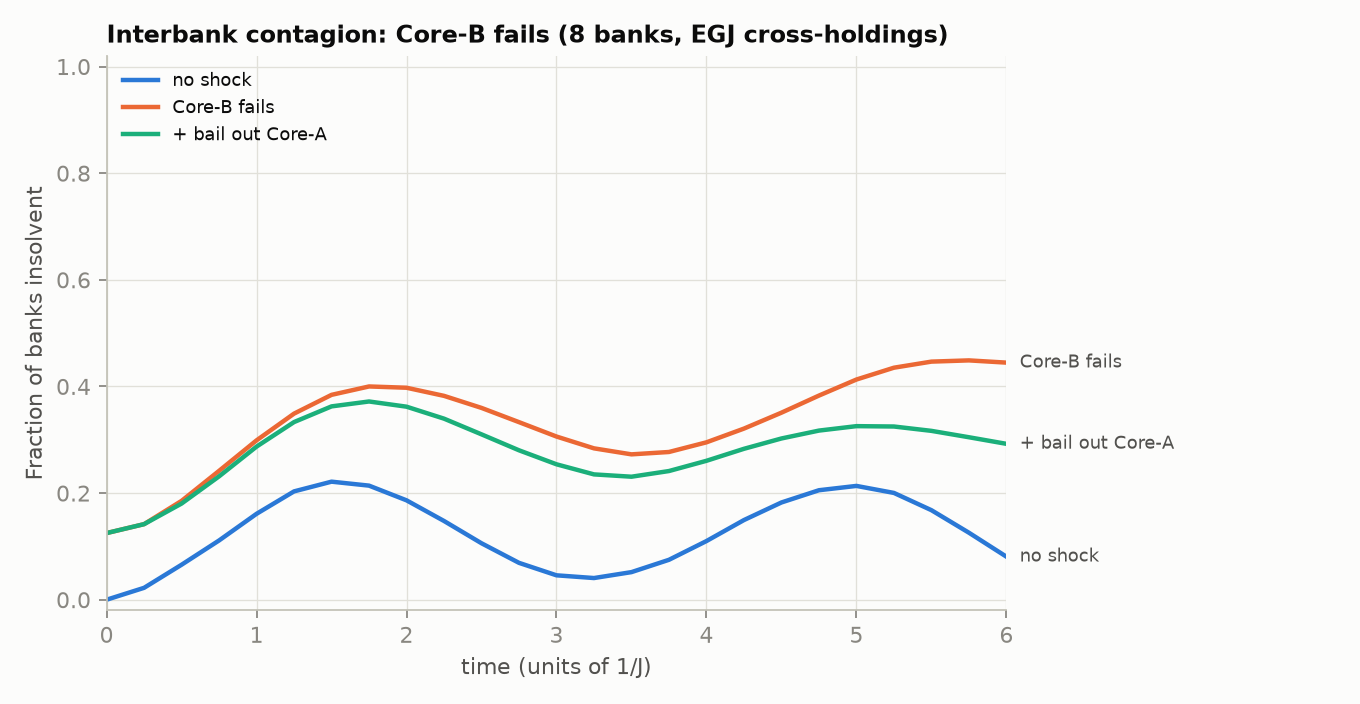

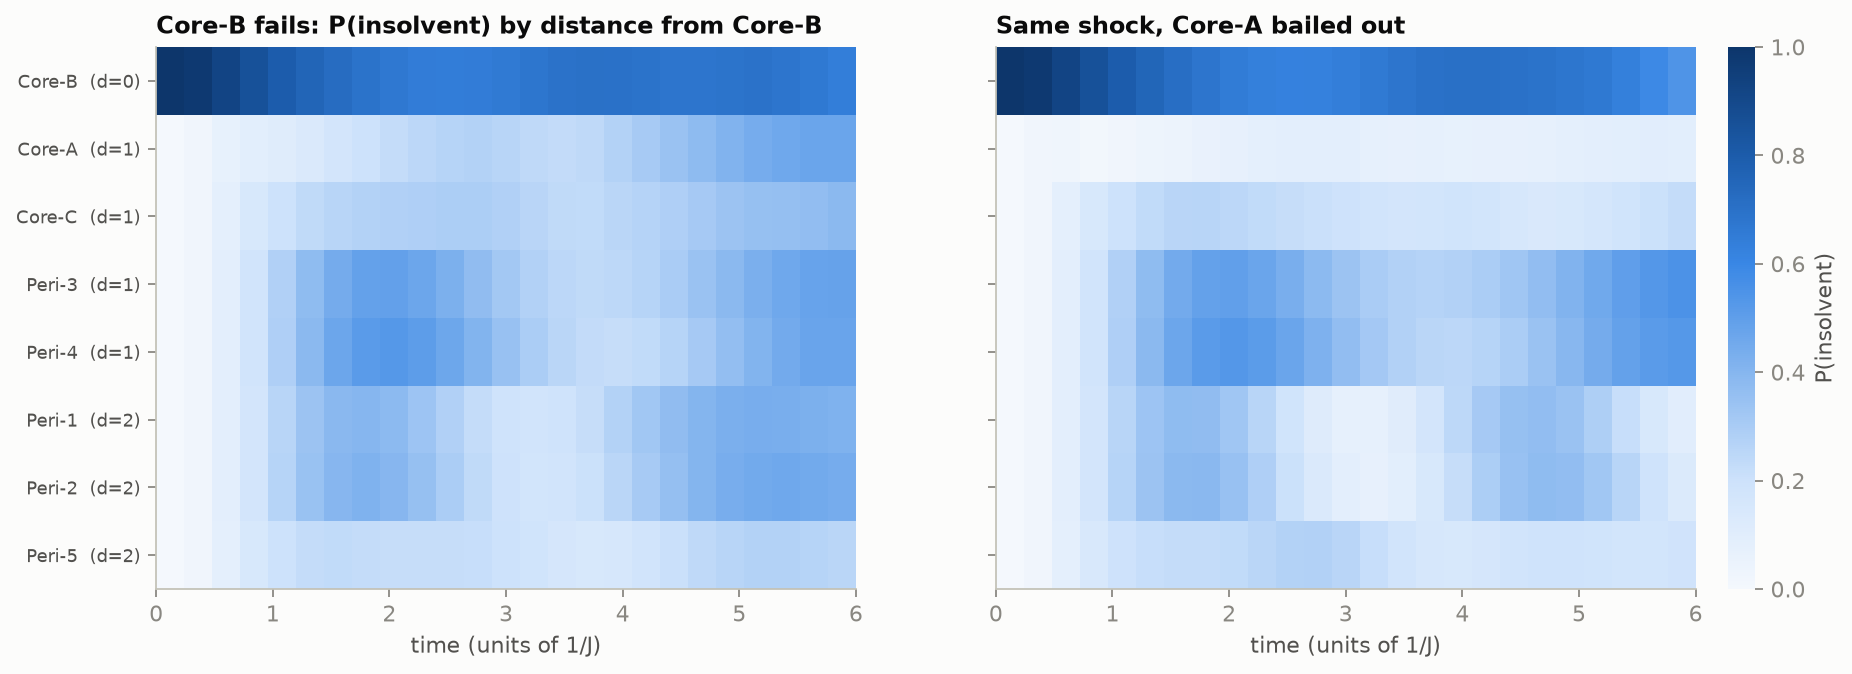

In [18]:
from qecon.plots import plot_compare, plot_lightcone_pair

OUT = BUILD / "out"
banks = {
    "no shock": run_spec(spec_path("banks"), overrides=["initial.ones=[]", "fields.shock.nodes=[]"]),
    "Core-B fails": run_spec(spec_path("banks"), exact=True),
    "+ bail out Core-A": run_spec(spec_path("banks"), overrides=["fields.bailout.nodes=[0]"]),
}
plot_compare(list(banks.values()), list(banks), OUT / "banks.png",
             "Interbank contagion: Core-B fails (8 banks, EGJ cross-holdings)")
plot_lightcone_pair(banks["Core-B fails"], banks["+ bail out Core-A"], OUT / "banks_cone.png",
                    "Core-B fails: P(insolvent) by distance from Core-B",
                    "Same shock, Core-A bailed out")
show(OUT / "banks.png")
show(OUT / "banks_cone.png")

**Inflation.** Expectations stay anchored at target, then de-anchor as money growth rises.

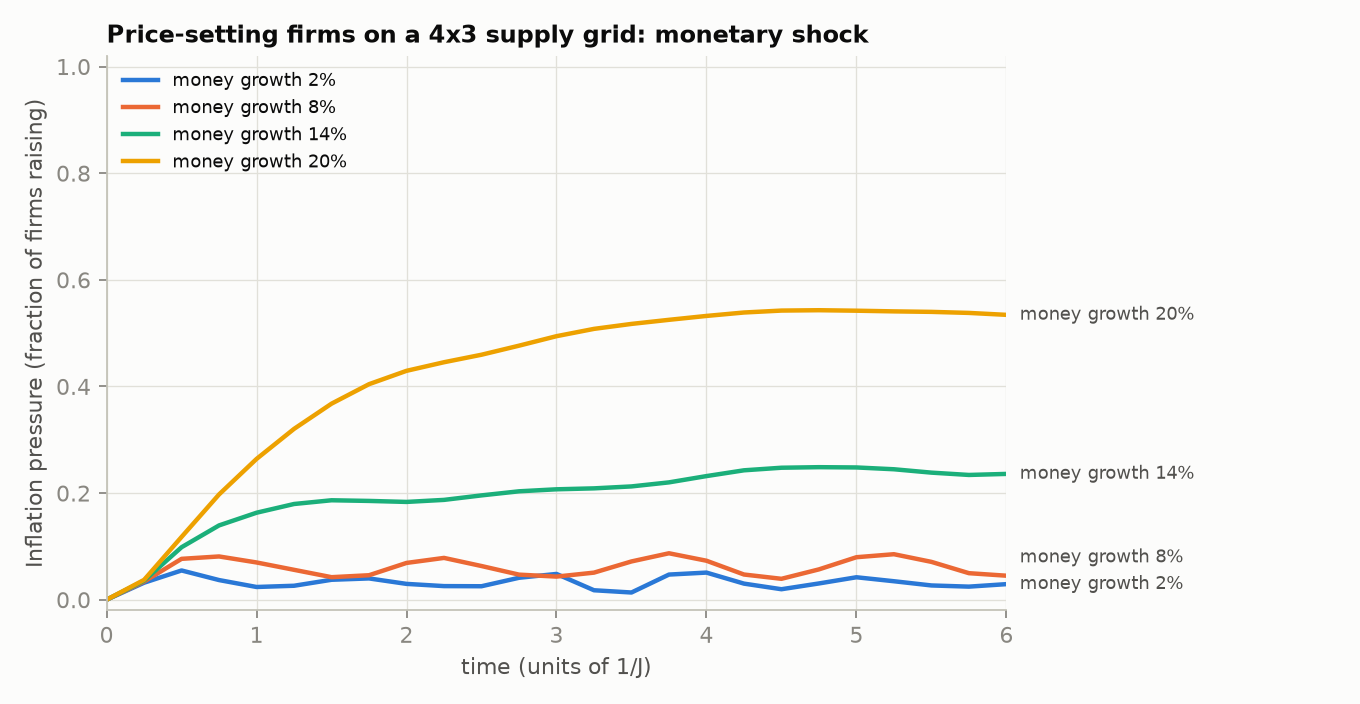

In [19]:
money = [2, 8, 14, 20]
firms = [run_spec(spec_path("firms"), overrides=[f"fields.money_growth={m}"], exact=True) for m in money]
plot_compare(firms, [f"money growth {m}%" for m in money], OUT / "firms.png",
             "Price-setting firms on a 4x3 supply grid: monetary shock")
show(OUT / "firms.png")

**Compliance.** Three evaders pull their neighbours along. More audits raise the floor.

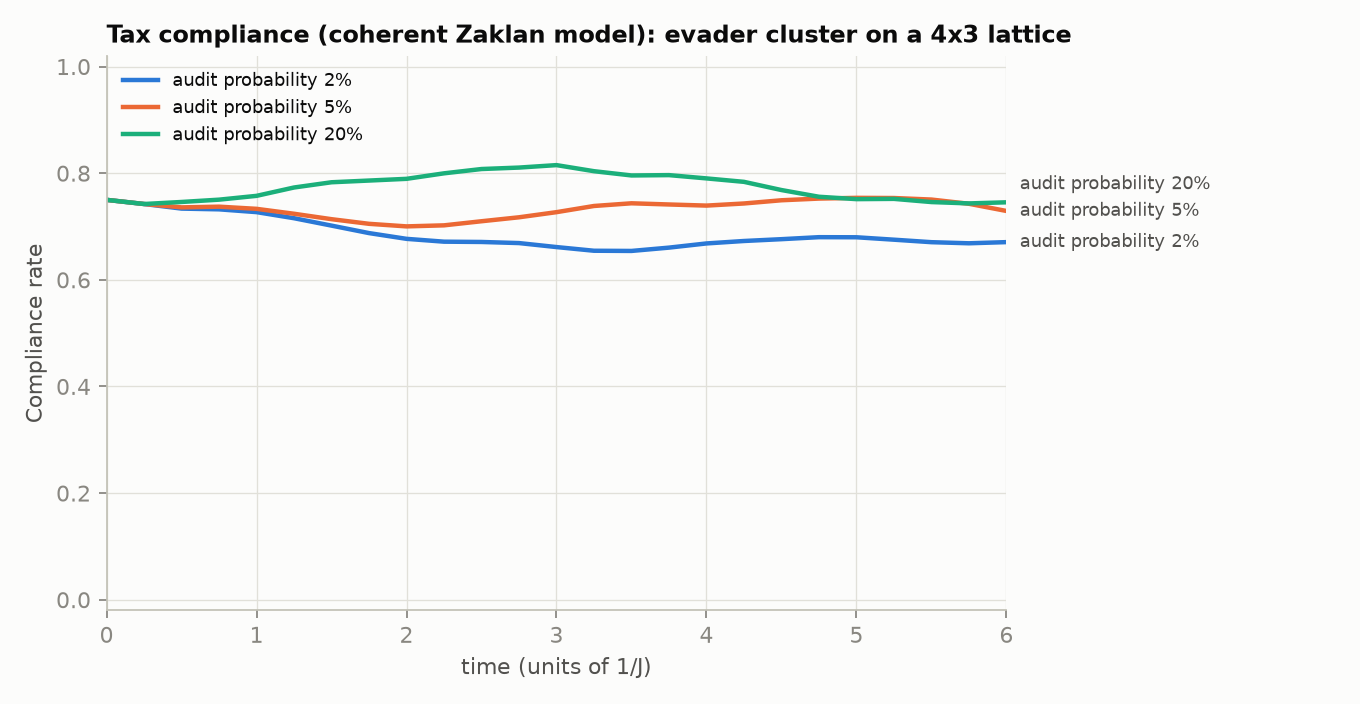

In [20]:
audits = [0.02, 0.05, 0.20]
taxpayers = [run_spec(spec_path("taxpayers"), overrides=[f"fields.audit_prob={p}"], exact=True) for p in audits]
plot_compare(taxpayers, [f"audit probability {p:.0%}" for p in audits], OUT / "taxpayers.png",
             "Tax compliance (coherent Zaklan model): evader cluster on a 4x3 lattice")
show(OUT / "taxpayers.png")

**Checking the headline claims.** This cell stops the notebook if a number at the top of this page is wrong.

In [21]:
def peak(result):
    return max(result["series"][result["headline"]])


def floor(result):
    return min(result["series"][result["headline"]])


def agent_peak(result, i):
    return float(np.array(result["per_agent"]["p_one"])[:, i].max())


rows = [
    ("Peak insolvency when Core-B fails", peak(banks["Core-B fails"]), 0.45),
    ("Peak insolvency with no shock", peak(banks["no shock"]), 0.22),
    ("Core-A peak failure, no bailout", agent_peak(banks["Core-B fails"], 0), 0.47),
    ("Core-A peak failure, bailed out", agent_peak(banks["+ bail out Core-A"], 0), 0.10),
    ("Peak firms raising, 2% money growth", peak(firms[0]), 0.055),
    ("Peak firms raising, 20% money growth", peak(firms[3]), 0.54),
    ("Lowest compliance, 5% audits", floor(taxpayers[1]), 0.70),
    ("Lowest compliance, 20% audits", floor(taxpayers[2]), 0.74),
]
table = ["| Claim | Computed now | Stated above |", "|---|---:|---:|"]
for name, value, stated in rows:
    assert abs(value - stated) < 0.0101, (name, value, stated)
    table.append(f"| {name} | {value:.1%} | {stated * 100:g}% |")
errors = [r["trotter_max_error"] for r in [banks["Core-B fails"], *firms, *taxpayers]]
table.append(f"| Largest Trotter error vs exact, all runs above | {max(errors):.1e} | below 1e-2 |")
assert max(errors) < 1e-2
display(Markdown("\n".join(table)))

| Claim | Computed now | Stated above |
|---|---:|---:|
| Peak insolvency when Core-B fails | 44.9% | 45% |
| Peak insolvency with no shock | 22.1% | 22% |
| Core-A peak failure, no bailout | 47.2% | 47% |
| Core-A peak failure, bailed out | 9.5% | 10% |
| Peak firms raising, 2% money growth | 5.5% | 5.5% |
| Peak firms raising, 20% money growth | 54.3% | 54% |
| Lowest compliance, 5% audits | 70.0% | 70% |
| Lowest compliance, 20% audits | 74.2% | 74% |
| Largest Trotter error vs exact, all runs above | 5.5e-03 | below 1e-2 |

<a id="p4"></a>
## Part 4: Validation

How do we know the circuit computes what we say it computes? We built the same physics a second
way and measured the gap. `validation/reference.py` builds $H$ from the raw parameters using only
NumPy, because the engine's own `exact_state` shares its matrix with the circuit and would hide a
sign or qubit-order bug.

The test system is a 3×4 grid with a different $J$, $h$ and $\Gamma$ on every site, because
uniform values hide qubit-order bugs and 1D chains are classically solvable.

In [22]:
%%writefile qecon_src/validation/systems.py
"""The standard test system every validation script shares.

Why this system and not the chain in bench.py:
  * 2D grid: a 1D nearest-neighbour chain is classically solvable.
  * h != 0: breaks the free-fermion solution.
  * Different J, h, Gamma on every site: uniform values hide qubit-order bugs.
"""
from dataclasses import dataclass

import numpy as np

SEED = 7
ROWS, COLS = 3, 4
INIT_ONES = (0, 5)   # agents that start in |1> (failed / evading / raising)
T_REF = 1.0          # evolution time used for the convergence figures
STEPS = (1, 2, 4, 8, 16, 32)
FIT_FROM = 4         # slopes fit r >= 4 only; r = 1, 2 are outside the small-step regime


@dataclass(frozen=True)
class System:
    n: int
    edges: dict
    h: np.ndarray
    gamma: np.ndarray
    init_ones: tuple


def grid_edges(rows, cols):
    """Nearest-neighbour edges of a rows x cols grid, as (i, j) index pairs."""
    pairs = []
    for a in range(rows):
        for b in range(cols):
            q = a * cols + b
            if b + 1 < cols:
                pairs.append((q, q + 1))
            if a + 1 < rows:
                pairs.append((q, q + cols))
    return pairs


def standard_system(gamma_scale=1.0, seed=SEED, rows=ROWS, cols=COLS, init_ones=INIT_ONES):
    """3x4 heterogeneous grid. gamma_scale=0 gives the same system with Gamma off."""
    rng = np.random.default_rng(seed)
    n = rows * cols
    edges = {pair: float(rng.uniform(0.5, 1.5)) for pair in grid_edges(rows, cols)}
    h = rng.uniform(-0.6, 0.6, n)
    gamma = rng.uniform(0.3, 0.7, n) * gamma_scale
    return System(n, edges, h, gamma, tuple(init_ones))


In [23]:
%%writefile qecon_src/validation/reference.py
"""Ground truth that shares no code with the thing it checks.

core.engine.exact_state builds its matrix from the same SparsePauliOp the circuit
uses, so a bug in compile_ising would appear on both sides and cancel. Everything
here starts from the raw (edges, h, gamma) and uses only NumPy and SciPy.

Convention: bit i of a basis index is qubit i, and |0> means Z = +1.
"""
import numpy as np
import scipy.sparse as sp
from scipy.sparse.linalg import expm_multiply


def spins(n):
    """Array of shape (n, 2^n): the Z eigenvalue of qubit i in each basis state."""
    idx = np.arange(1 << n)
    return np.array([1 - 2 * ((idx >> i) & 1) for i in range(n)])


def diagonal_energy(n, edges, h):
    """-sum J s_i s_j - sum h s_i for every basis state."""
    s = spins(n)
    energy = np.zeros(1 << n)
    for (i, j), J in edges.items():
        energy -= J * s[i] * s[j]
    for i in range(n):
        energy -= h[i] * s[i]
    return energy


def hamiltonian(n, edges, h, gamma):
    """H = -sum J Z_i Z_j - sum h Z_i - sum Gamma X_i as a sparse matrix."""
    dim = 1 << n
    idx = np.arange(dim)
    H = sp.diags(diagonal_energy(n, edges, h)).tocsr().astype(complex)
    for i in range(n):
        if gamma[i]:
            flip = sp.csr_matrix(
                (np.full(dim, -gamma[i], dtype=complex), (idx ^ (1 << i), idx)),
                shape=(dim, dim),
            )
            H = H + flip
    return H.tocsc()


def basis_state(n, init_ones=()):
    psi = np.zeros(1 << n, dtype=complex)
    psi[sum(1 << q for q in init_ones)] = 1.0
    return psi


def exact_evolve(system, t):
    """exp(-itH)|init>, built without Qiskit."""
    H = hamiltonian(system.n, system.edges, system.h, system.gamma)
    return expm_multiply(-1j * t * H, basis_state(system.n, system.init_ones))


def exact_series(system, times):
    """Exact states at each time. Rows follow `times`."""
    H = hamiltonian(system.n, system.edges, system.h, system.gamma)
    psi0 = basis_state(system.n, system.init_ones)
    return np.array([expm_multiply(-1j * t * H, psi0) for t in times])


def infidelity(a, b):
    """1 - |<a|b>|^2. Rounding can make this about -1e-15, so don't take its log raw."""
    return 1.0 - abs(np.vdot(a, b)) ** 2


def z_expectations(psi, n):
    """<Z_i> for every qubit, from the probabilities."""
    return spins(n) @ (np.abs(psi) ** 2)


def magnetization(psi, n):
    return float(z_expectations(psi, n).mean())


def zz_expectation(psi, n, i, j):
    s = spins(n)
    return float((s[i] * s[j]) @ (np.abs(psi) ** 2))


def x_bar(psi, n):
    """Average <X_i>. Off-diagonal, so it sees phases that Z-basis numbers cannot."""
    idx = np.arange(1 << n)
    return float(np.mean([np.real(np.vdot(psi, psi[idx ^ (1 << i)])) for i in range(n)]))


def half_entropy(psi, n, k=None):
    """Entanglement entropy in bits between qubits 0..k-1 and the rest.

    Basis index = high_bits * 2^k + low_bits, so reshaping to (2^(n-k), 2^k) puts the
    kept qubits on the columns. Schmidt weights are the squared singular values.
    """
    k = n // 2 if k is None else k
    weights = np.linalg.svd(psi.reshape(1 << (n - k), 1 << k), compute_uv=False) ** 2
    weights = weights[weights > 1e-14]
    return max(0.0, float(-(weights * np.log2(weights)).sum()))


def slope(steps, values, fit_from):
    """Log-log slope using only points with steps >= fit_from."""
    r = np.array(steps, dtype=float)
    y = np.array(values, dtype=float)
    keep = r >= fit_from
    return float(np.polyfit(np.log(r[keep]), np.log(y[keep]), 1)[0])


In [24]:
%%writefile qecon_src/validation/glauber.py
"""Classical Glauber Monte Carlo of the Gamma = 0 energy function.

This is the kind of model the econophysics papers run (Zaklan's taxpayers, for
example): one definite bit-string per replica, with spins flipped at random.
Spin convention matches the Hamiltonian: s = +1 is |0>, s = -1 is |1>.
"""
import numpy as np


def coupling_matrix(n, edges):
    J = np.zeros((n, n))
    for (i, j), value in edges.items():
        J[i, j] = J[j, i] = value
    return J


def energy(s, J, h):
    """-sum_{i<j} J s_i s_j - sum h s_i for rows of spins s."""
    return -0.5 * np.einsum("ri,ij,rj->r", s, J, s) - s @ h


def flip_cost(s, sites, J, h):
    """Energy change from flipping one spin per replica. `sites` is an int or one per row."""
    rows = np.arange(len(s))
    sites = np.broadcast_to(sites, rows.shape)
    return 2.0 * s[rows, sites] * (np.einsum("ri,ri->r", s, J[sites]) + h[sites])


def run(system, temperature, sweeps, replicas=4000, seed=0):
    """Returns per-agent <s_i> after each sweep, shape (sweeps + 1, n).

    One sweep is n single-spin update attempts per replica. Each replica picks its own
    site: sharing one site across replicas makes the whole ensemble jump in lockstep.
    """
    rng = np.random.default_rng(seed)
    n = system.n
    J = coupling_matrix(n, system.edges)
    s = np.ones((replicas, n))
    s[:, list(system.init_ones)] = -1.0
    rows = np.arange(replicas)
    history = [s.mean(axis=0)]
    for _ in range(sweeps):
        for _ in range(n):
            sites = rng.integers(n, size=replicas)
            accept = 1.0 / (1.0 + np.exp(flip_cost(s, sites, J, system.h) / temperature))
            flipped = rng.random(replicas) < accept
            s[rows[flipped], sites[flipped]] *= -1.0
        history.append(s.mean(axis=0))
    return np.array(history)


In [25]:
%%writefile qecon_src/validation/plotting.py
"""Shared chart style and output helpers, so all five figures read as one set."""
import json
from pathlib import Path

import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt

OUT = Path(__file__).parent / "figures"

SURFACE = "#fcfcfb"
INK = "#0b0b0b"
INK_SECONDARY = "#52514e"
INK_MUTED = "#8a8983"
GRID = "#e6e5e0"

# Fixed order, checked with the palette validator. Colour follows the entity.
BLUE = "#2a78d6"     # first order / coherent / Gamma > 0
ORANGE = "#eb6834"   # second order
AQUA = "#1baf7a"     # Gamma = 0 / classical reference

plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "font.size": 13,
    "font.family": "sans-serif",
    "text.color": INK,
    "axes.labelcolor": INK_SECONDARY,
    "axes.titlecolor": INK,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.edgecolor": INK_MUTED,
    "axes.linewidth": 0.8,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "xtick.color": INK_SECONDARY,
    "ytick.color": INK_SECONDARY,
    "xtick.minor.visible": False,
    "ytick.minor.visible": False,
    "lines.linewidth": 2.0,
    "lines.markersize": 7,
    "legend.frameon": False,
    "legend.fontsize": 12,
})


def heading(fig, title, subtitle=None):
    """Claim-style title in the top-left, with an optional line of conditions under it."""
    fig.text(0.015, 0.975, title, fontsize=18, fontweight="bold", color=INK, va="top")
    if subtitle:
        fig.text(0.015, 0.905, subtitle, fontsize=12.5, color=INK_SECONDARY, va="top")


def save(fig, name, data):
    """Writes figures/<name>.png and figures/<name>.json. Slides quote the JSON."""
    OUT.mkdir(exist_ok=True)
    fig.savefig(OUT / f"{name}.png", dpi=200)
    plt.close(fig)
    (OUT / f"{name}.json").write_text(json.dumps(data, indent=2) + "\n", encoding="utf-8")
    print(f"wrote {OUT / name}.png")


In [26]:
%%writefile qecon_src/validation/fig1_trotter.py
"""Fig 1: Trotter convergence and the Gamma = 0 test. Never cut this one.

Each point compares a real gate-level circuit against the independent NumPy reference.
Run from the repo root:  python -m validation.fig1_trotter
"""
import matplotlib.pyplot as plt
import numpy as np
from qiskit.quantum_info import Statevector

from core.engine import compile_ising, evolve
from validation import reference as ref
from validation.plotting import AQUA, BLUE, INK_SECONDARY, ORANGE, heading, save
from validation.systems import FIT_FROM, STEPS, T_REF, standard_system

FLOOR = 1e-16   # log axes cannot show 0 or the tiny negatives rounding produces


def infidelities(system, order):
    H = compile_ising(system.n, system.edges, system.h, system.gamma)
    exact = ref.exact_evolve(system, T_REF)
    return [
        float(ref.infidelity(Statevector(evolve(H, T_REF, r, system.init_ones, order)).data, exact))
        for r in STEPS
    ]


def reference_line(ax, value_at_last, power, label=None):
    """Theory slope, drawn just above the data so the two can be compared by eye."""
    r = np.array([STEPS[2], STEPS[-1]], dtype=float)
    ax.plot(r, 6 * value_at_last * (r / r[-1]) ** power, color=INK_SECONDARY,
            linestyle=(0, (4, 3)), linewidth=1.4, zorder=1, label=label)


def main():
    system = standard_system()
    classical = standard_system(gamma_scale=0.0)
    first = infidelities(system, 1)
    second = infidelities(system, 2)
    zero = infidelities(classical, 2)
    zero_first = infidelities(classical, 1)

    slope_first = ref.slope(STEPS, first, FIT_FROM)
    slope_second = ref.slope(STEPS, second, FIT_FROM)
    worst_zero = max(abs(v) for v in zero + zero_first)

    assert abs(slope_first + 2) < 0.2, slope_first
    assert abs(slope_second + 4) < 0.3, slope_second
    assert worst_zero < 1e-12, worst_zero

    fig, ax = plt.subplots(figsize=(11, 6.2))
    fig.subplots_adjust(left=0.09, right=0.80, top=0.82, bottom=0.12)
    heading(fig, "Trotter error falls as theory predicts, and vanishes when Γ = 0",
            f"{system.n} agents on a 3×4 grid, {len(system.edges)} edges, different J, h, Γ per site, t = {T_REF:g}."
            "  Circuit vs independent NumPy reference.")

    ax.plot(STEPS, first, "-o", color=BLUE, label="First order")
    ax.plot(STEPS, second, "-s", color=ORANGE, label="Second order")
    shown_zero = np.maximum(np.abs(zero), FLOOR)
    ax.plot(STEPS, shown_zero, "-^", color=AQUA, label="Γ = 0 (second order)")
    reference_line(ax, first[-1], -2, "Theory slopes (shifted up)")
    reference_line(ax, second[-1], -4)

    ax.set_xscale("log", base=2)
    ax.set_yscale("log")
    ax.set_ylim(FLOOR / 3, 3)
    ax.set_xticks(STEPS, [str(r) for r in STEPS])
    ax.set_yticks([10.0 ** p for p in range(-16, 1, 4)])
    ax.set_xlabel("Trotter steps r")
    ax.set_ylabel("Infidelity  1 − |⟨ψ_exact|ψ_circuit⟩|²")
    ax.legend(loc="center left", bbox_to_anchor=(0.0, 0.42))

    edge = STEPS[-1] * 1.12
    ax.annotate(f"slope −{abs(slope_first):.2f}\n(theory −2)", (edge, first[-1]), va="center",
                annotation_clip=False, fontsize=12.5)
    ax.annotate(f"slope −{abs(slope_second):.2f}\n(theory −4)", (edge, second[-1]), va="center",
                annotation_clip=False, fontsize=12.5)
    ax.annotate(f"zero to machine\nprecision\n(worst {worst_zero:.0e})", (edge, shown_zero[-1]),
                va="center", annotation_clip=False, fontsize=12.5)

    save(fig, "fig1_trotter", {
        "steps": list(STEPS),
        "infidelity_first_order": first,
        "infidelity_second_order": second,
        "infidelity_gamma_zero_first_order": zero_first,
        "infidelity_gamma_zero_second_order": zero,
        "slope_first_order": slope_first,
        "slope_second_order": slope_second,
        "fit_uses_steps_from": FIT_FROM,
        "worst_abs_gamma_zero_infidelity": worst_zero,
    })
    print(f"slopes {slope_first:.3f} {slope_second:.3f}  worst Gamma=0 {worst_zero:.2e}")


if __name__ == "__main__":
    main()


In [27]:
%%writefile qecon_src/validation/fig2_memory_wall.py
"""Fig 2: the memory wall. This is the deck's "why quantum" picture.

Gate counts come from real compiled circuits, not a formula. Memory is checked
against an actual state vector before being extrapolated.
Run from the repo root:  python -m validation.fig2_memory_wall
"""
import matplotlib.pyplot as plt
import numpy as np
from qiskit.quantum_info import Statevector

from core.engine import compile_ising, evolve
from validation.plotting import AQUA, BLUE, INK_SECONDARY, ORANGE, heading, save
from validation.systems import grid_edges

GIB = 2 ** 30
LAPTOP_GIB = 31.6              # this machine's physical RAM
NIGHTHAWK_GATES = 5000         # IBM-stated two-qubit gate budget (vendor figure)
CZ_PER_RZZ = 2                 # Nighthawk is CZ-native, and an RZZ costs 2 CZ
GRIDS = [(2, 2), (3, 3), (3, 4), (4, 5), (5, 6), (6, 7), (7, 8), (8, 9), (9, 10), (10, 11), (10, 12)]
STEP_COUNTS = (1, 4, 8)


def statevector_bytes(n):
    return 16 * 2.0 ** n


def rzz_per_step(rows, cols):
    """Two-qubit gates in one first-order step, counted from the compiled circuit."""
    n = rows * cols
    edges = {pair: 1.0 for pair in grid_edges(rows, cols)}
    H = compile_ising(n, edges, [0.1] * n, [0.5] * n)
    circuit = evolve(H, 1.0, 1, order=1)
    count = circuit.count_ops().get("rzz", 0)
    assert count == len(edges), (count, len(edges))
    return count


def main():
    for n in (10, 14):
        measured = Statevector.from_int(0, 2 ** n).data.nbytes
        assert measured == statevector_bytes(n), (n, measured)

    sizes = [r * c for r, c in GRIDS]
    rzz = [rzz_per_step(r, c) for r, c in GRIDS]
    cz = np.array(rzz) * CZ_PER_RZZ

    ns = np.arange(2, sizes[-1] + 1)
    wall = int(ns[statevector_bytes(ns) > LAPTOP_GIB * GIB][0])
    assert wall == 31, wall

    fig, (left, right) = plt.subplots(1, 2, figsize=(13, 6.2), sharex=True)
    fig.subplots_adjust(left=0.07, right=0.97, top=0.76, bottom=0.12, wspace=0.24)
    heading(fig, "Exact simulation memory doubles per agent. Circuit size grows with edges.",
            "Applies to exact state-vector simulation of our coherent model on square grids. "
            "Not a claim about all classical methods:\n"
            "tensor networks can go further when entanglement stays low.")

    left.plot(ns, statevector_bytes(ns), color=BLUE)
    left.axhline(LAPTOP_GIB * GIB, color=INK_SECONDARY, linestyle=(0, (4, 3)), linewidth=1.2)
    left.plot([wall], [statevector_bytes(wall)], "o", color=BLUE, markeredgecolor="white", markersize=9)
    left.set_yscale("log")
    left.set_yticks([10.0 ** p for p in range(3, 40, 6)])
    left.set_ylabel("Bytes")
    left.set_title("Memory for one exact state vector (16 · 2ⁿ bytes)")
    left.set_xlabel("Agents n")
    left.annotate(f"This laptop ({LAPTOP_GIB:g} GiB)\nruns out at n = {wall}",
                  (wall, LAPTOP_GIB * GIB), xytext=(46, 3e4), fontsize=12.5,
                  arrowprops={"arrowstyle": "-", "color": INK_SECONDARY, "linewidth": 0.8})
    left.text(sizes[-1] - 8, statevector_bytes(sizes[-1]),
              f"n = {sizes[-1]}: about 2 × 10³⁷ bytes", ha="right", va="center", fontsize=12.5)

    for steps, color, marker in zip(STEP_COUNTS, (BLUE, ORANGE, AQUA), "os^"):
        label = f"{steps} step" + ("" if steps == 1 else "s")
        right.plot(sizes, cz * steps, "-" + marker, color=color, label=label)
    right.axhline(NIGHTHAWK_GATES, color=INK_SECONDARY, linestyle=(0, (4, 3)), linewidth=1.2)
    right.text(2, NIGHTHAWK_GATES + 90, "IBM Nighthawk budget: 5,000 (vendor figure)", va="bottom", fontsize=12.5)
    right.set_ylim(0, 5800)
    right.set_title("Two-qubit gates, first order, before routing")
    right.set_xlabel("Agents n")
    right.set_ylabel("CZ count (2 per compiled RZZ)")
    right.legend(loc="upper left", bbox_to_anchor=(0.0, 0.85))

    save(fig, "fig2_memory_wall", {
        "grid_shapes": GRIDS,
        "agents": sizes,
        "rzz_per_first_order_step_measured": rzz,
        "cz_per_first_order_step": cz.tolist(),
        "laptop_gib": LAPTOP_GIB,
        "first_n_exceeding_laptop": wall,
        "bytes_at_largest_n": statevector_bytes(sizes[-1]),
        "max_first_order_steps_in_nighthawk_budget_at_largest_n": int(NIGHTHAWK_GATES // cz[-1]),
    })
    print(f"wall n={wall}; n={sizes[-1]}: {rzz[-1]} RZZ/step, {cz[-1]} CZ/step, "
          f"{NIGHTHAWK_GATES // cz[-1]} steps fit the budget")


if __name__ == "__main__":
    main()


In [28]:
%%writefile qecon_src/validation/fig5_observable_error.py
"""Fig 5: error in the numbers the app actually reports.

Uses the worst error across several times, because a single time can land on an
accidental zero crossing and flatter the result. First and second order overlap
exactly on Z-basis observables: see finding 5 in PLAN.md. <X> is off-diagonal, so it
is included to show the two orders are genuinely different circuits.
Run from the repo root:  python -m validation.fig5_observable_error
"""
import matplotlib.pyplot as plt
from qiskit.quantum_info import Statevector

from core.engine import compile_ising, evolve
from validation import reference as ref
from validation.plotting import BLUE, ORANGE, heading, save
from validation.systems import FIT_FROM, standard_system

TIMES = (0.5, 1.0, 1.5, 2.0)
STEPS = (1, 2, 4, 8, 16, 32, 64, 128)
PAIR = (0, 1)   # a coupled pair that includes a seeded agent


def observables(psi, n):
    return {
        "M": ref.magnetization(psi, n),
        "ZZ": ref.zz_expectation(psi, n, *PAIR),
        "X": ref.x_bar(psi, n),
    }


def worst_errors(system, H, exact, order):
    """{observable: [worst error over TIMES, one per step count]}."""
    errors = {name: [] for name in ("M", "ZZ", "X")}
    for r in STEPS:
        worst = dict.fromkeys(errors, 0.0)
        for t in TIMES:
            psi = Statevector(evolve(H, t, r, system.init_ones, order)).data
            got = observables(psi, system.n)
            for name in errors:
                worst[name] = max(worst[name], abs(got[name] - exact[t][name]))
        for name in errors:
            errors[name].append(worst[name])
    return errors


def main():
    system = standard_system()
    H = compile_ising(system.n, system.edges, system.h, system.gamma)
    exact = {t: observables(ref.exact_evolve(system, t), system.n) for t in TIMES}
    first = worst_errors(system, H, exact, 1)
    second = worst_errors(system, H, exact, 2)

    for name in ("M", "ZZ"):
        gap = max(abs(a - b) for a, b in zip(first[name], second[name]))
        assert gap < 1e-11, (name, gap)
        assert abs(ref.slope(STEPS, first[name], FIT_FROM) + 2) < 0.2, name

    slopes = {
        name: {"first": ref.slope(STEPS, first[name], FIT_FROM),
               "second": ref.slope(STEPS, second[name], FIT_FROM)}
        for name in first
    }

    panels = (("M", "Average ⟨Z⟩  (Z-basis)"),
              ("ZZ", f"Pair ⟨Z{PAIR[0]}Z{PAIR[1]}⟩  (Z-basis)"),
              ("X", "Average ⟨X⟩  (not Z-basis)"))
    fig, axes = plt.subplots(1, 3, figsize=(14, 5.8), sharey=True, sharex=True)
    fig.subplots_adjust(left=0.065, right=0.985, top=0.78, bottom=0.13, wspace=0.08)
    heading(fig, "On Z-basis numbers, first order matches second at half the gates",
            f"Worst error over t = {', '.join(f'{t:g}' for t in TIMES)}.  12 agents, 3×4 grid.  "
            "The overlap is exact, not a plotting error: the orders differ only by diagonal phases.")

    for ax, (name, title) in zip(axes, panels):
        ax.plot(STEPS, first[name], "-o", color=BLUE, label="First order")
        ax.plot(STEPS, second[name], linestyle=(0, (3, 3)), marker="s", markerfacecolor="none",
                markeredgewidth=1.6, color=ORANGE, label="Second order")
        ax.set_xscale("log", base=2)
        ax.set_yscale("log")
        ax.set_xticks(STEPS, [str(r) for r in STEPS])
        ax.set_title(title, fontsize=12.5)
        ax.set_xlabel("Trotter steps r")
    axes[0].set_ylabel("Worst absolute error")
    axes[0].legend(loc="lower left")
    for ax, name in zip(axes, ("M", "ZZ")):
        ax.text(0.97, 0.93, f"both orders: slope −{abs(slopes[name]['first']):.2f}",
                transform=ax.transAxes, ha="right", fontsize=12.5)
    axes[2].text(0.97, 0.93, f"first order: slope −{abs(slopes['X']['first']):.2f}\n"
                             f"second order: slope −{abs(slopes['X']['second']):.2f}",
                 transform=axes[2].transAxes, ha="right", va="center", fontsize=12.5)

    save(fig, "fig5_observable_error", {
        "times": list(TIMES),
        "steps": list(STEPS),
        "worst_error_first_order": first,
        "worst_error_second_order": second,
        "slopes_from_r4": slopes,
    })
    for name in first:
        print(name, "r=16 err", f"{first[name][4]:.2e}", "slopes", {k: round(v, 2) for k, v in slopes[name].items()},
              "first", [f"{v:.1e}" for v in first[name]], "second", [f"{v:.1e}" for v in second[name]])


if __name__ == "__main__":
    main()


In [29]:
%%writefile qecon_src/validation/fig4_glauber.py
"""Fig 4: the classical Glauber model and our coherent model are different models.

Shared: J, h, graph, seeded agents. Glauber adds a temperature, the coherent model adds
Gamma, and their clocks are different units, so each gets its own time axis.

The core difference is energy. Unitary evolution conserves <H> and has no bath to absorb
energy, and here the seeded agent stays near where it started. Glauber is coupled to a
heat bath, so it forgets the start and settles at a temperature-set equilibrium.
Run from the repo root:  python -m validation.fig4_glauber
"""
import math

import matplotlib.pyplot as plt
import numpy as np
from qiskit.quantum_info import Statevector

from core.engine import compile_ising, evolve
from validation import glauber, reference as ref
from validation.plotting import BLUE, ORANGE, heading, save
from validation.systems import standard_system

T_MAX = 12.0
SWEEPS = 40
TEMPERATURES = (1.0, 2.5)
SEEDED_AGENT = 0
MAX_DT = 0.05


def main():
    system = standard_system()
    n = system.n
    H = compile_ising(n, system.edges, system.h, system.gamma)
    H_matrix = ref.hamiltonian(n, system.edges, system.h, system.gamma)

    times = np.linspace(0, T_MAX, 241)
    states = ref.exact_series(system, times)
    z = np.array([ref.z_expectations(psi, n) for psi in states])
    coherent_M, coherent_agent = z.mean(axis=1), z[:, SEEDED_AGENT]
    energy = np.array([np.real(np.vdot(psi, H_matrix @ psi)) for psi in states])
    energy_drift = float(np.abs(energy - energy[0]).max())
    assert energy_drift < 1e-9, energy_drift

    check_times = np.arange(1.0, T_MAX + 0.5, 1.0)
    circuit_z = []
    for t in check_times:
        psi = Statevector(evolve(H, t, math.ceil(t / MAX_DT), system.init_ones, 2)).data
        circuit_z.append(ref.z_expectations(psi, n))
    circuit_z = np.array(circuit_z)
    circuit_gap = float(np.abs(
        circuit_z - np.array([ref.z_expectations(p, n) for p in ref.exact_series(system, check_times)])
    ).max())
    assert circuit_gap < 2e-2, circuit_gap

    runs = {T: glauber.run(system, T, SWEEPS) for T in TEMPERATURES}
    sweeps = np.arange(SWEEPS + 1)

    fig, (left, right) = plt.subplots(1, 2, figsize=(13, 6), sharey=True)
    fig.subplots_adjust(left=0.075, right=0.985, top=0.78, bottom=0.13, wspace=0.07)
    heading(fig, "Same economy, different models: one conserves energy, one relaxes",
            "Shared: J, h, graph, seeded agents. Coherent adds Γ, Glauber adds temperature T. "
            "Time axes are different units and are not comparable.")

    left.plot(times, coherent_M, color=BLUE, label="All agents")
    left.plot(times, coherent_agent, color=ORANGE, label=f"Seeded agent {SEEDED_AGENT}")
    left.plot(check_times, circuit_z.mean(axis=1), "o", color=BLUE, markeredgecolor="white", label="Circuit points")
    left.plot(check_times, circuit_z[:, SEEDED_AGENT], "o", color=ORANGE, markeredgecolor="white")
    left.set_title("Coherent model: seeded agent stays near its start")
    left.set_xlabel("Time t (units of 1/J)")
    left.set_ylabel("⟨Z⟩  (+1 = |0⟩, −1 = |1⟩)")
    left.set_ylim(-1.08, 1.08)
    left.legend(loc="center right", bbox_to_anchor=(1.0, 0.45))

    for T, style in zip(TEMPERATURES, ("-", (0, (4, 2)))):
        right.plot(sweeps, runs[T].mean(axis=1), color=BLUE, linestyle=style, label=f"All agents, T = {T:g}")
        right.plot(sweeps, runs[T][:, SEEDED_AGENT], color=ORANGE, linestyle=style, label=f"Seeded agent, T = {T:g}")
    right.set_title("Glauber Monte Carlo: start is forgotten")
    right.set_xlabel("Monte Carlo sweeps (4,000 replicas)")
    right.legend(loc="lower right")

    data = {
        "max_abs_gap_circuit_vs_exact": circuit_gap,
        "coherent_energy_start": float(energy[0]),
        "coherent_energy_max_drift": energy_drift,
        "coherent_seeded_agent_z_final": float(coherent_agent[-1]),
        "coherent_seeded_agent_z_max": float(coherent_agent.max()),
        "coherent_average_z_range": [float(coherent_M.min()), float(coherent_M.max())],
        "glauber": {
            str(T): {
                "final_average": float(runs[T][-1].mean()),
                "final_seeded_agent": float(runs[T][-1][SEEDED_AGENT]),
            }
            for T in TEMPERATURES
        },
    }
    save(fig, "fig4_glauber", data)
    print(data)


if __name__ == "__main__":
    main()


In [30]:
%%writefile qecon_src/validation/fig3_entropy.py
"""Fig 3: entanglement entropy. With no transverse field, there is no entanglement.

Only true because we start from a definite bit-string: ZZ terms alone can entangle a
superposition. Here "entanglement" is a correlation diagnostic of the model, not a claim
about real people.
Run from the repo root:  python -m validation.fig3_entropy
"""
import math

import matplotlib.pyplot as plt
import numpy as np
from qiskit.quantum_info import Statevector

from core.engine import compile_ising, evolve
from validation import reference as ref
from validation.plotting import AQUA, BLUE, ORANGE, heading, save
from validation.systems import standard_system

T_MAX = 6.0
MAX_DT = 0.05
SCALES = ((1.0, "Full Γ", BLUE, "o"), (0.5, "Half Γ", ORANGE, "s"), (0.0, "Γ = 0", AQUA, "^"))


def main():
    times = np.linspace(0, T_MAX, 121)
    check_times = np.arange(1.0, T_MAX + 0.5, 1.0)

    fig, ax = plt.subplots(figsize=(11, 6.2))
    fig.subplots_adjust(left=0.085, right=0.84, top=0.8, bottom=0.12)
    heading(fig, "Entanglement only appears when the transverse field is on",
            "Entropy between agents 0–5 and 6–11, from a definite starting bit-string.  "
            "Lines are exact, points are the circuit.")

    data = {"times": times.tolist(), "circuit_times": check_times.tolist(), "curves": {}}
    for scale, label, color, marker in SCALES:
        system = standard_system(gamma_scale=scale)
        n = system.n
        H = compile_ising(n, system.edges, system.h, system.gamma)
        exact = [ref.half_entropy(psi, n) for psi in ref.exact_series(system, times)]
        circuit = [
            ref.half_entropy(
                Statevector(evolve(H, t, math.ceil(t / MAX_DT), system.init_ones, 2)).data, n)
            for t in check_times
        ]
        gap = max(abs(c - exact[int(np.argmin(np.abs(times - t)))]) for c, t in zip(circuit, check_times))
        assert gap < 2e-2, (label, gap)
        ax.plot(times, exact, color=color)
        ax.plot(check_times, circuit, marker, color=color, markeredgecolor="white", markersize=9, label=label)
        ax.annotate(f"{label}: {exact[-1]:.2f} bits", (T_MAX * 1.015, exact[-1]), va="center",
                    annotation_clip=False, fontsize=12.5)
        data["curves"][label] = {"gamma_scale": scale, "exact": exact, "circuit": circuit,
                                 "max_gap_circuit_vs_exact": gap}

    zero = data["curves"]["Γ = 0"]
    assert max(zero["exact"] + zero["circuit"]) < 1e-9
    assert data["curves"]["Full Γ"]["exact"][-1] > 0.5

    ax.set_xlabel("Time t (units of 1/J)")
    ax.set_ylabel("Half-system entropy (bits)")
    ax.set_xlim(0, T_MAX)
    ax.set_ylim(bottom=-0.05)
    ax.legend(loc="upper left")

    save(fig, "fig3_entropy", data)
    for curve in data["curves"].values():   # ASCII only: Windows consoles can't print Gamma
        print(f"gamma scale {curve['gamma_scale']:g}: S(t={T_MAX:g}) = {curve['exact'][-1]:.3f} bits, "
              f"circuit gap {curve['max_gap_circuit_vs_exact']:.1e}")


if __name__ == "__main__":
    main()


In [31]:
from validation import reference
from validation.systems import standard_system

system = standard_system()
ours = compile_ising(system.n, system.edges, system.h, system.gamma).to_matrix(sparse=True).tocsc()
independent = reference.hamiltonian(system.n, system.edges, system.h, system.gamma)
print("Engine vs independent Hamiltonian, largest difference:", abs(ours - independent).max())

for name in ("banks", "firms", "taxpayers"):
    plugin, _, _ = prepare(spec_path(name))
    n, edges, h, gamma = plugin.system()
    gap = abs(plugin.hamiltonian().to_matrix(sparse=True) - reference.hamiltonian(n, edges, h, gamma)).max()
    assert gap < 1e-12
    print(f"{name:10s} preset vs independent Hamiltonian, largest difference: {gap:.1e}")

Engine vs independent Hamiltonian, largest difference: 8.881784197001252e-15
banks      preset vs independent Hamiltonian, largest difference: 1.8e-15
firms      preset vs independent Hamiltonian, largest difference: 7.1e-15
taxpayers  preset vs independent Hamiltonian, largest difference: 7.1e-15


**Trotter convergence and the $\Gamma = 0$ test.** Error falls at the rate theory predicts. With
the transverse field off, every term commutes and nothing moves, which is why $\Gamma$ is the
engine of the model. The result is zero to machine precision, not literally zero.

wrote qecon_src\validation\figures\fig1_trotter.png
slopes -2.026 -4.073  worst Gamma=0 6.22e-15


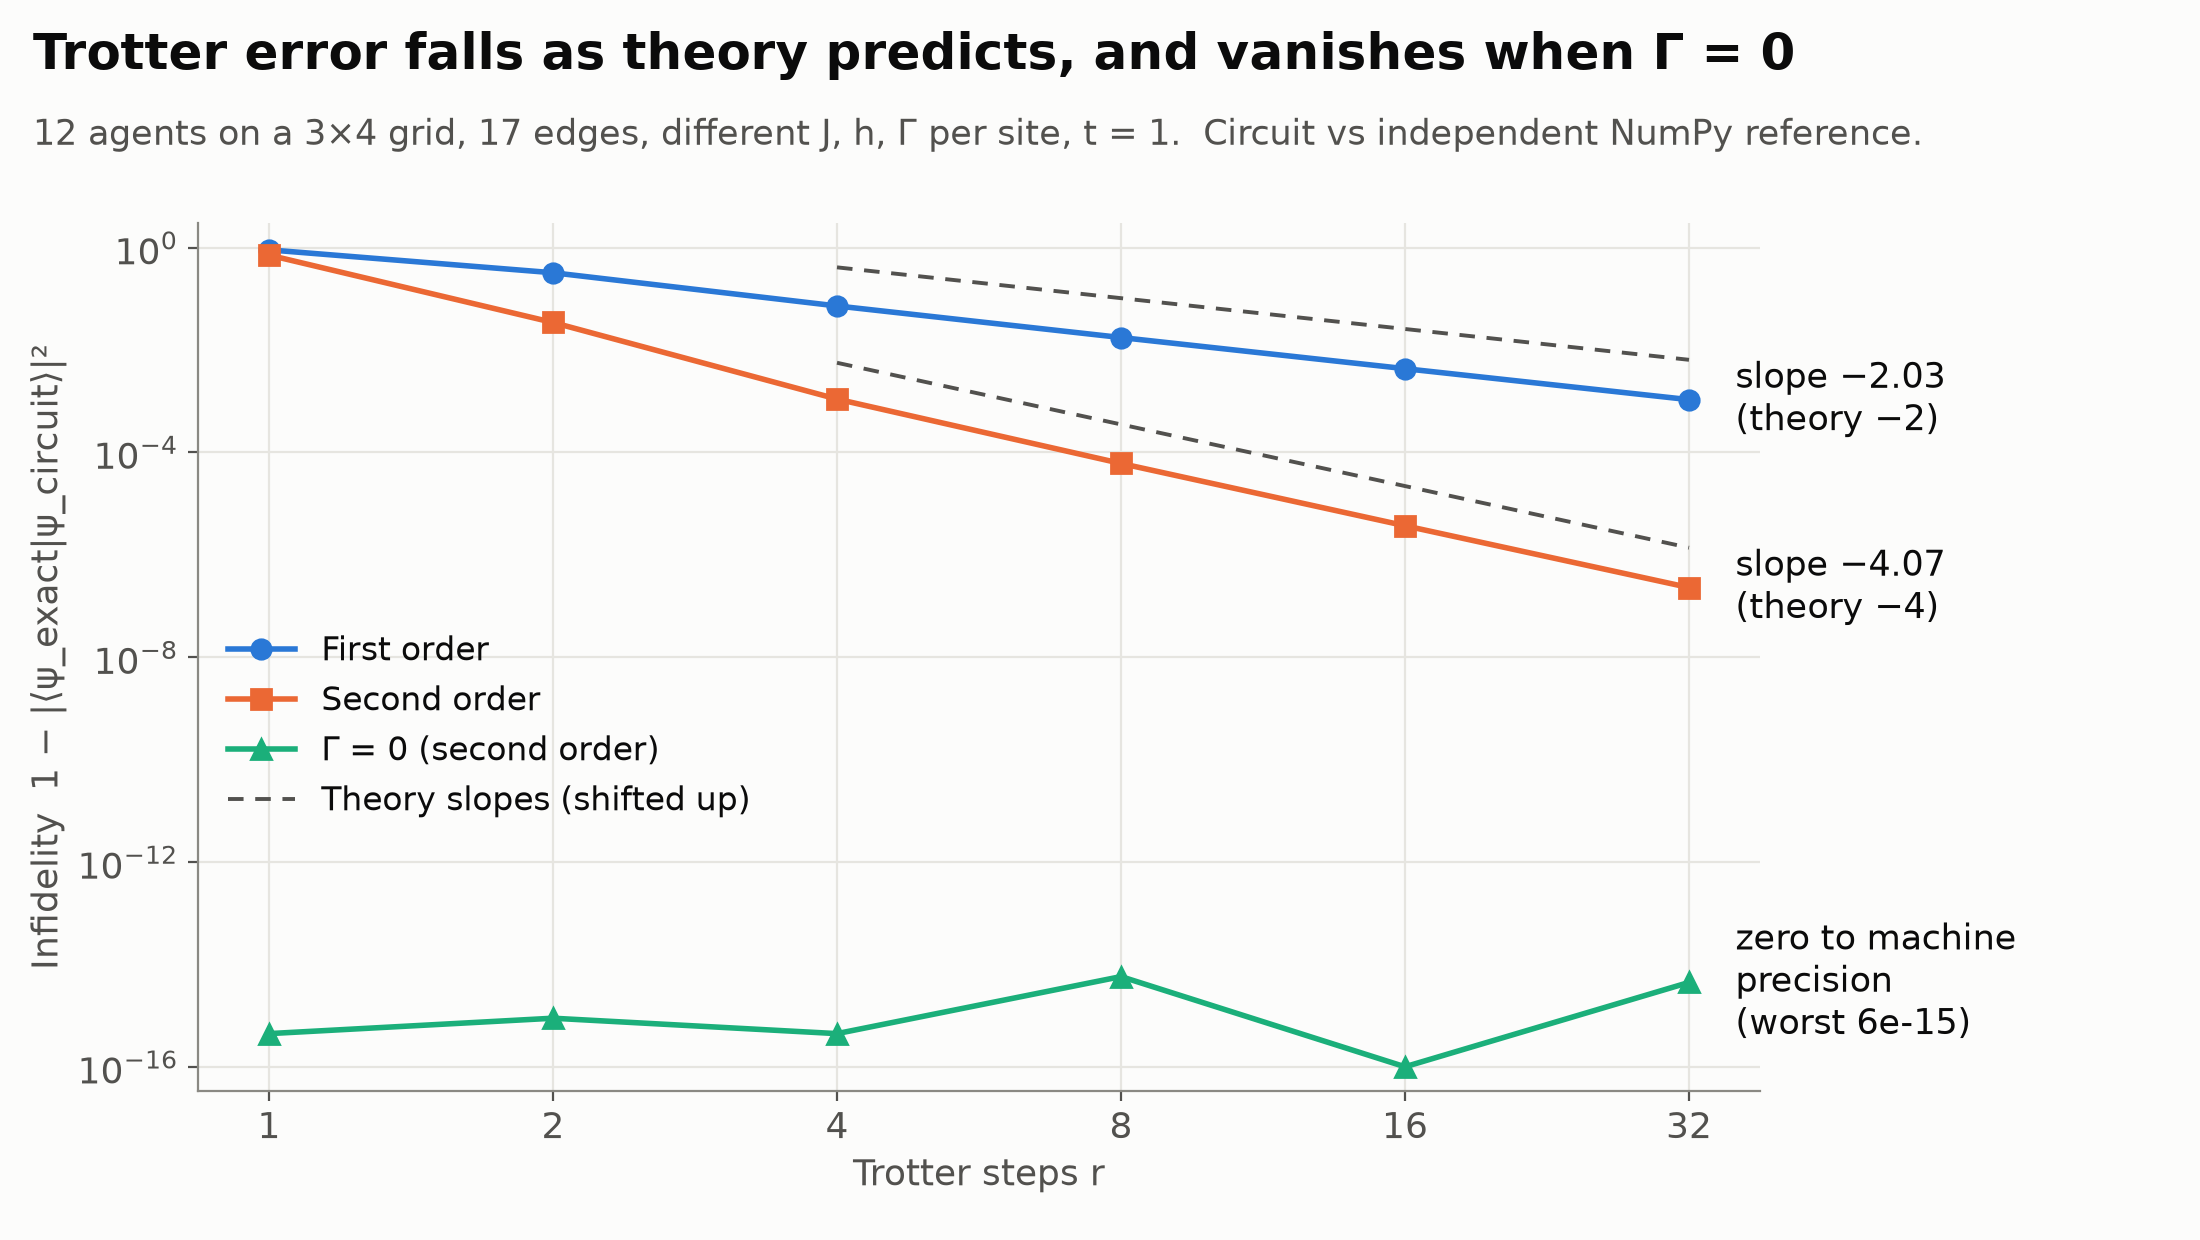

In [32]:
from validation import fig1_trotter

fig1_trotter.main()
show(BUILD / "validation" / "figures" / "fig1_trotter.png")

**The memory wall.** This is the reason to use a quantum computer for this model. Exact memory
doubles with every agent, while gate counts from real compiled circuits grow with the number of
edges. It covers exact state vectors only.

wrote qecon_src\validation\figures\fig2_memory_wall.png
wall n=31; n=120: 218 RZZ/step, 436 CZ/step, 11 steps fit the budget


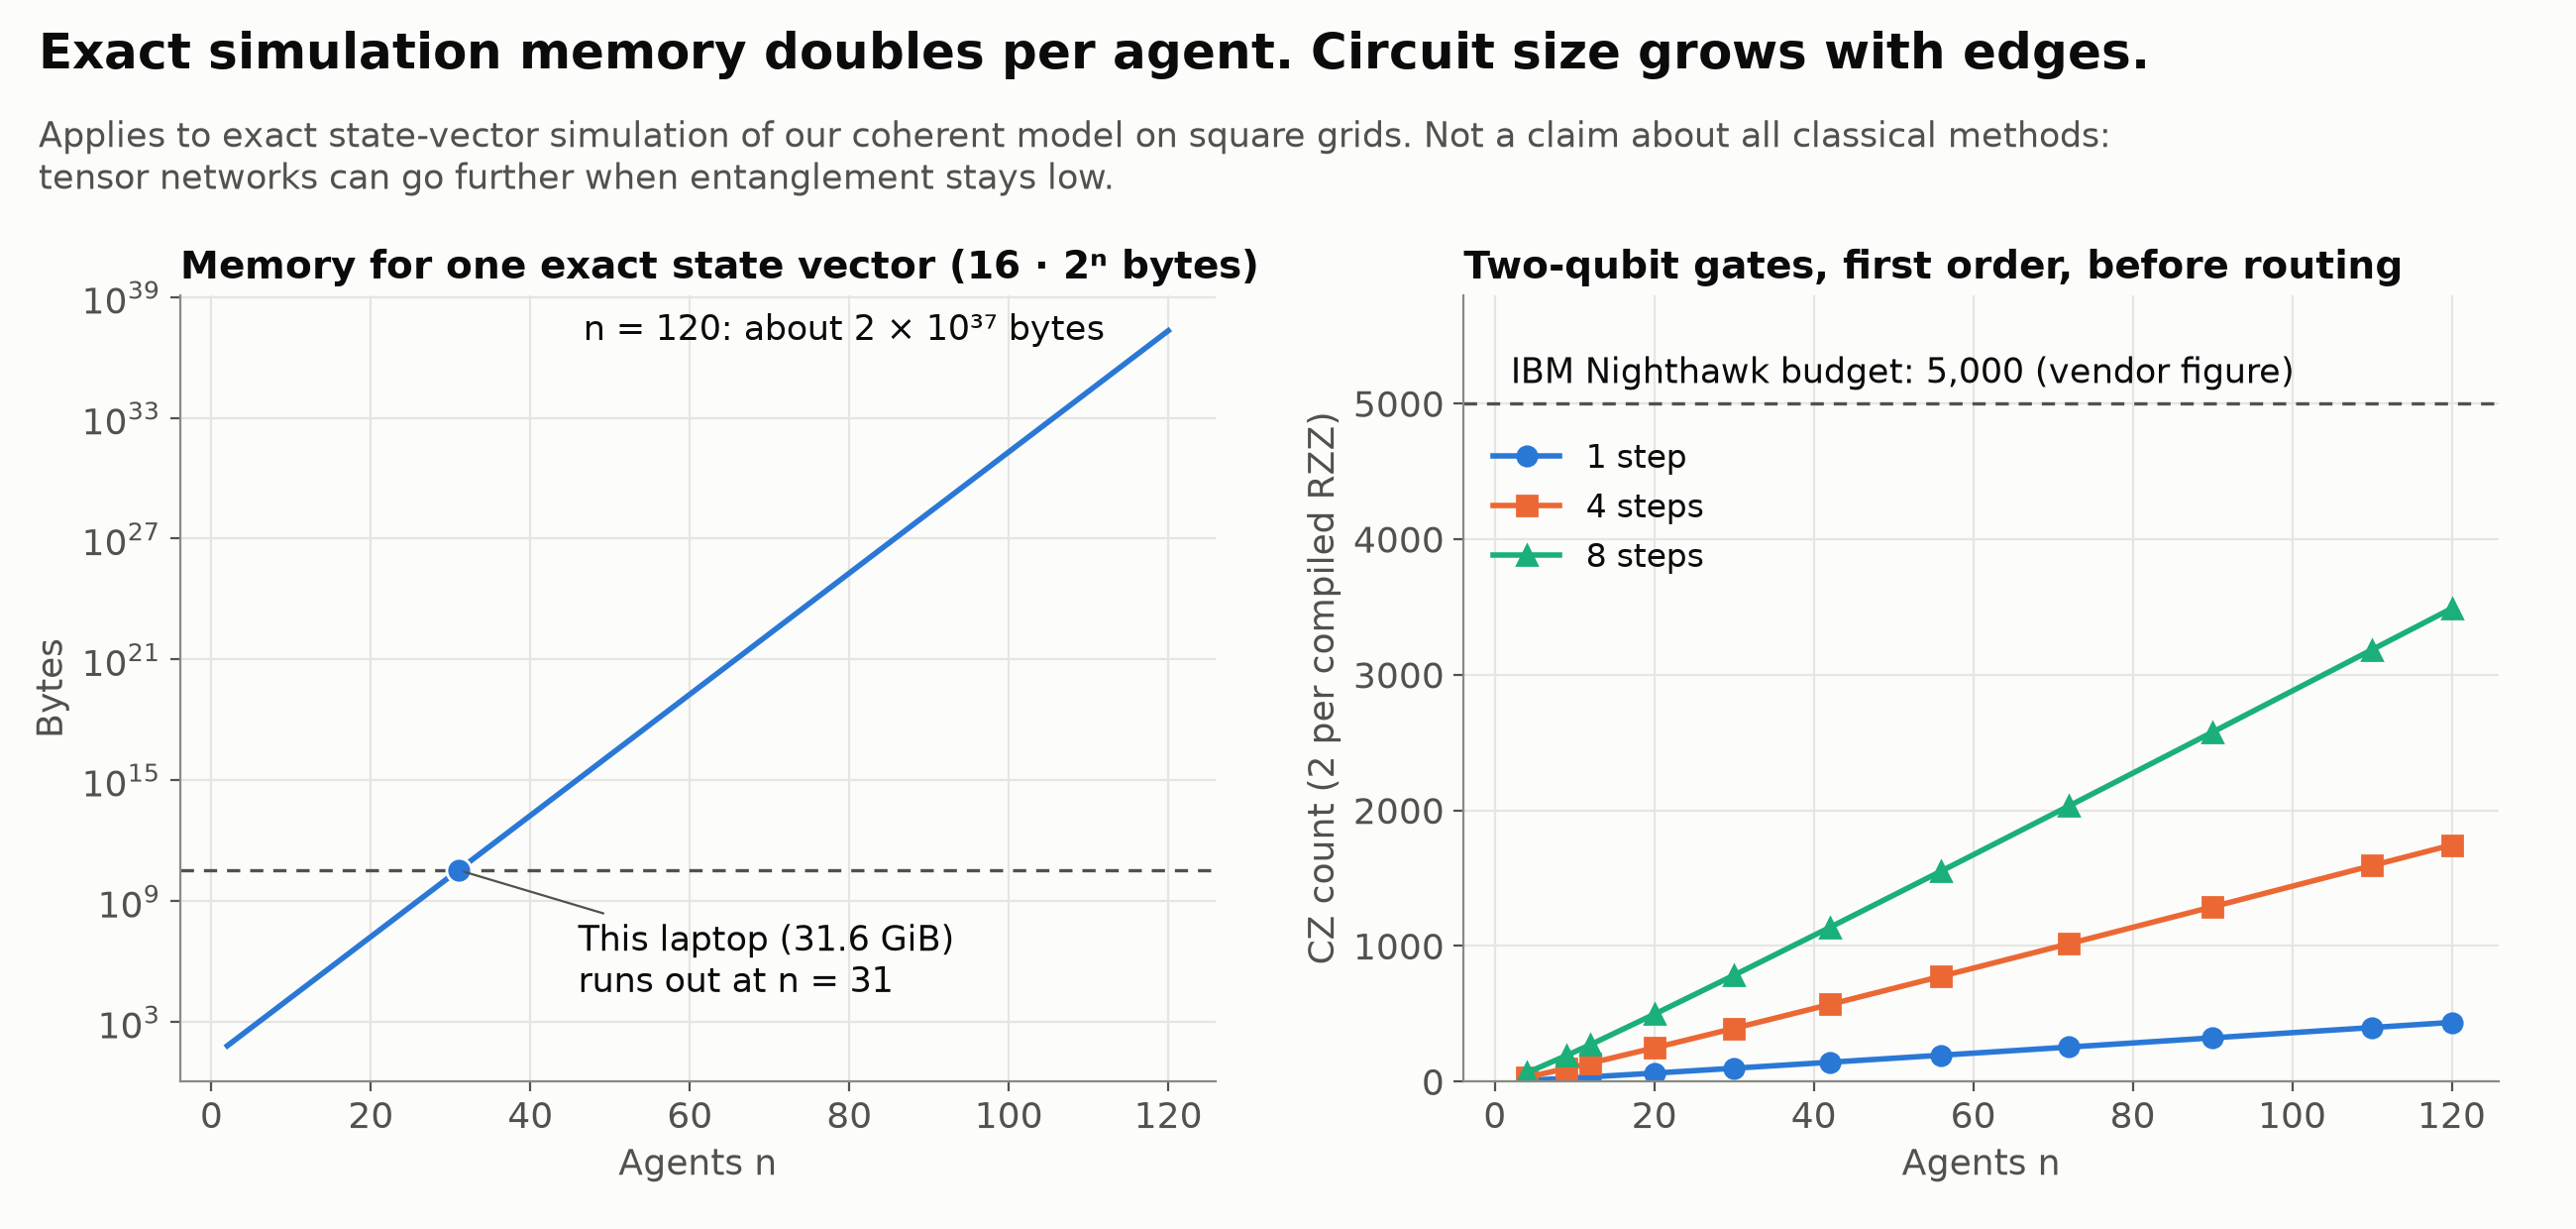

In [33]:
from validation import fig2_memory_wall

fig2_memory_wall.main()
show(BUILD / "validation" / "figures" / "fig2_memory_wall.png")

**Observable error.** First and second order overlap exactly on Z-basis numbers: they differ only
by diagonal phases, which can't change Z-basis probabilities from a basis-state start. So our specs
and hardware runs use first order, at half the two-qubit gates. $\langle X \rangle$ is not a
Z-basis number, and it shows the two really are different circuits.

wrote qecon_src\validation\figures\fig5_observable_error.png
M r=16 err 5.75e-04 slopes {'first': -1.97, 'second': -1.97} first ['4.9e-01', '8.2e-02', '7.9e-03', '2.3e-03', '5.8e-04', '1.4e-04', '3.6e-05', '9.0e-06'] second ['4.9e-01', '8.2e-02', '7.9e-03', '2.3e-03', '5.8e-04', '1.4e-04', '3.6e-05', '9.0e-06']
ZZ r=16 err 1.13e-03 slopes {'first': -2.05, 'second': -2.05} first ['3.1e-01', '3.2e-01', '2.2e-02', '4.6e-03', '1.1e-03', '2.8e-04', '7.0e-05', '1.8e-05'] second ['3.1e-01', '3.2e-01', '2.2e-02', '4.6e-03', '1.1e-03', '2.8e-04', '7.0e-05', '1.8e-05']
X r=16 err 1.34e-02 slopes {'first': -0.85, 'second': -2.08} first ['1.4e-01', '4.3e-02', '3.1e-02', '2.4e-02', '1.3e-02', '7.0e-03', '3.6e-03', '1.8e-03'] second ['9.0e-02', '2.8e-02', '3.2e-02', '6.0e-03', '1.4e-03', '3.6e-04', '8.9e-05', '2.2e-05']


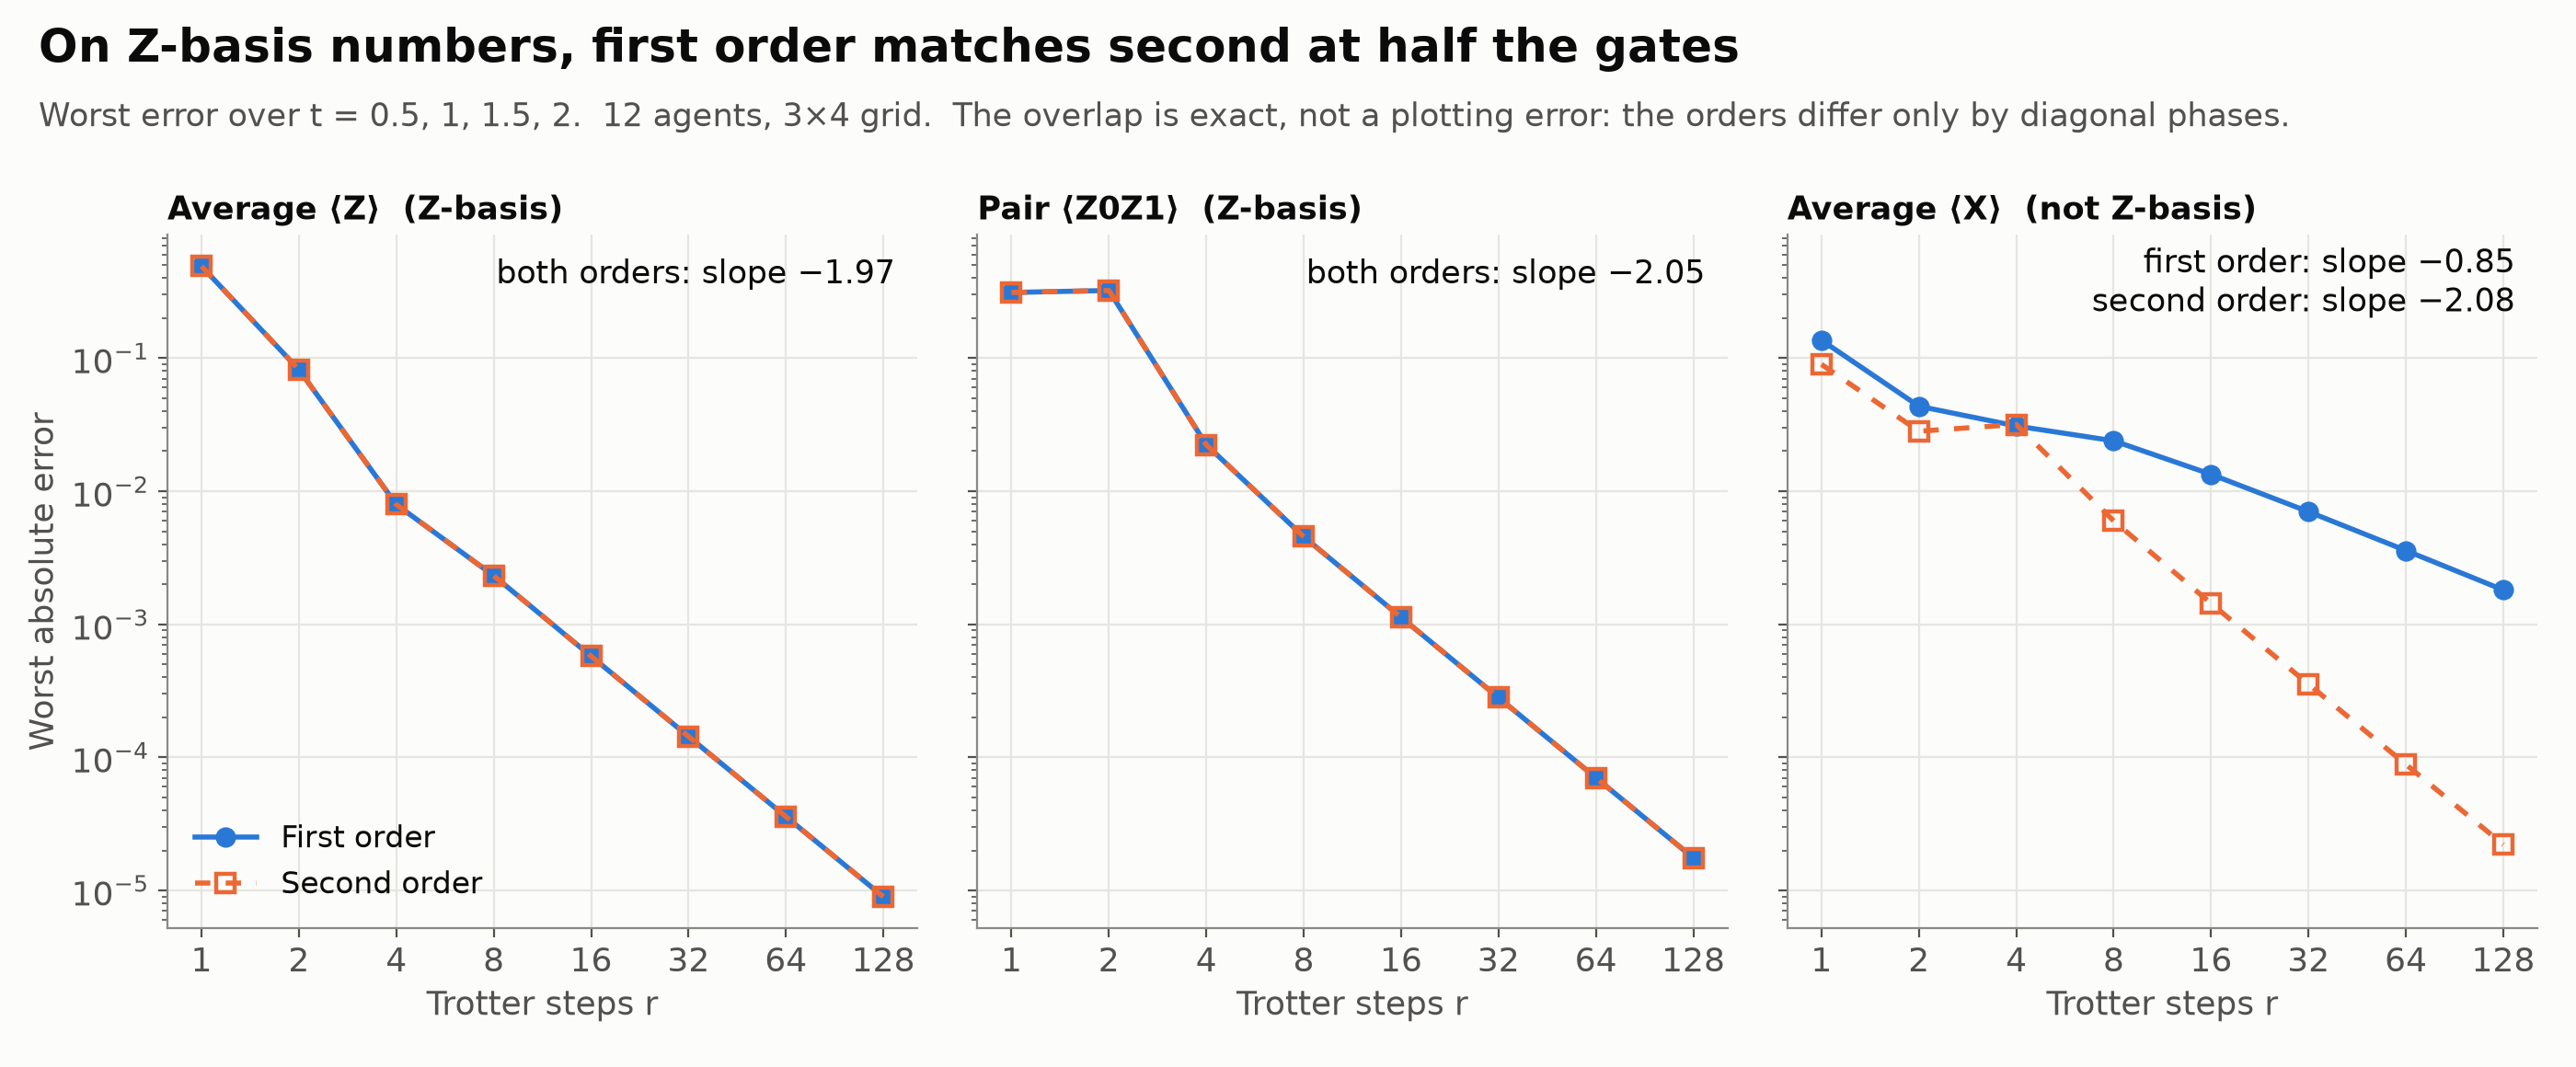

In [34]:
from validation import fig5_observable_error

fig5_observable_error.main()
show(BUILD / "validation" / "figures" / "fig5_observable_error.png")

**Against the classical model.** Glauber Monte Carlo uses the same $J$, $h$ and graph. It has a
heat bath, so it forgets its start and settles at a temperature-set equilibrium. The coherent
model conserves energy. These are different models, not faster and slower versions of one model.

wrote qecon_src\validation\figures\fig4_glauber.png
{'max_abs_gap_circuit_vs_exact': 0.0015676567550906295, 'coherent_energy_start': -3.9702289932583006, 'coherent_energy_max_drift': 3.597122599785507e-14, 'coherent_seeded_agent_z_final': -0.702312800256553, 'coherent_seeded_agent_z_max': -0.6644966369794397, 'coherent_average_z_range': [0.4725559444660652, 0.6666666666666666], 'glauber': {'1.0': {'final_average': 0.7955, 'final_seeded_agent': 0.834}, '2.5': {'final_average': 0.011333333333333334, 'final_seeded_agent': 0.1125}}}


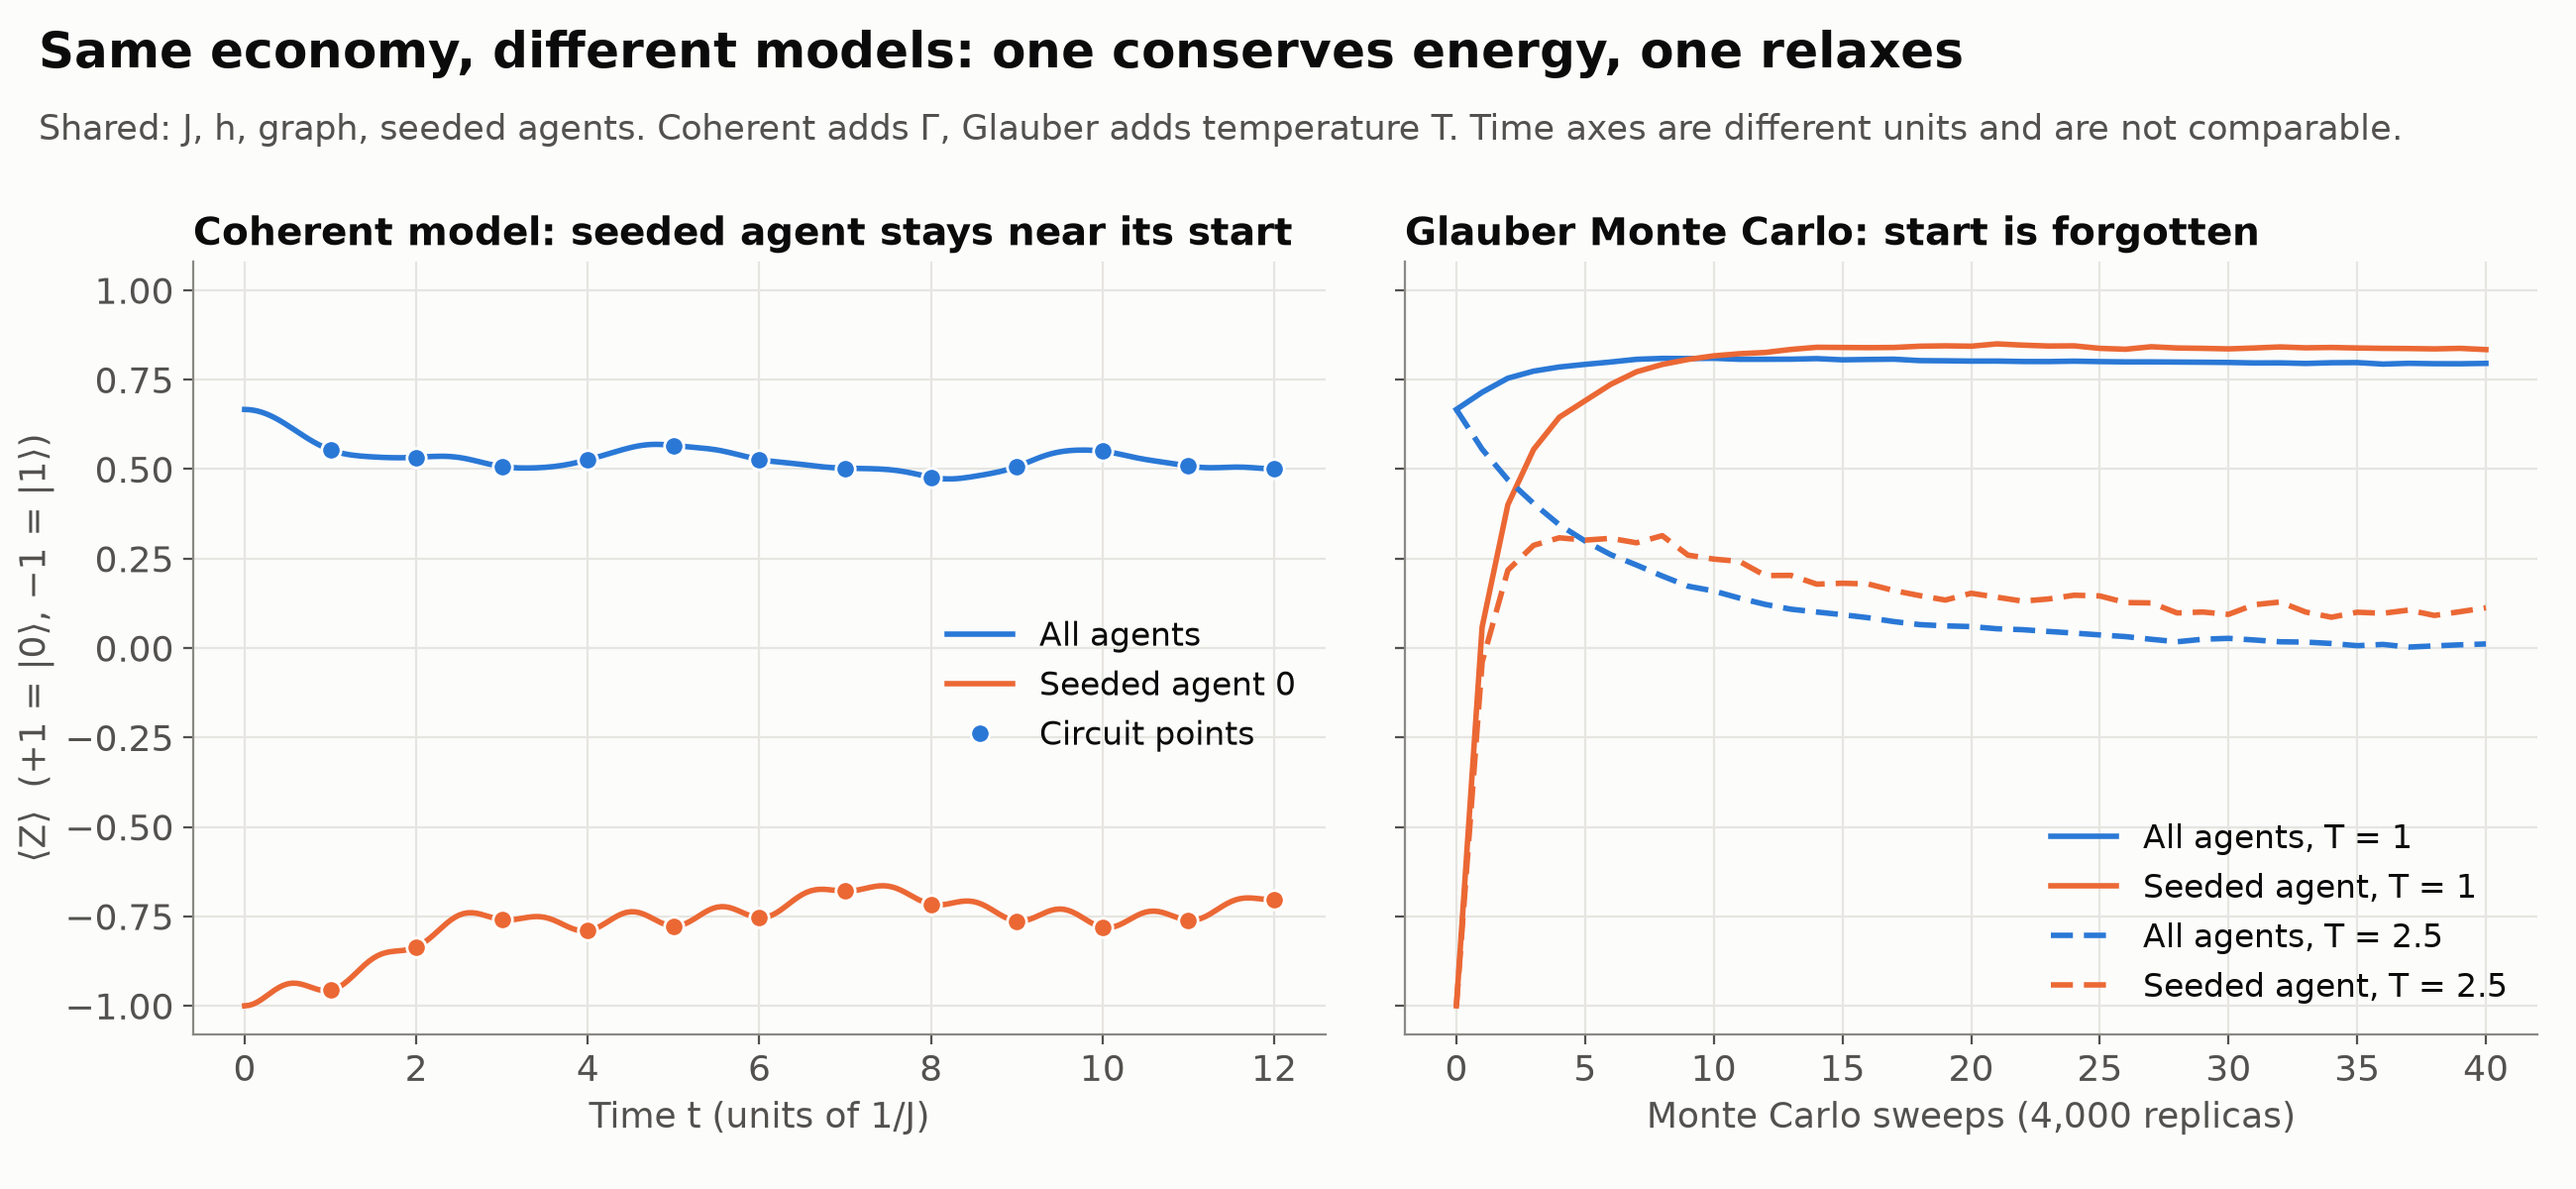

In [35]:
from validation import fig4_glauber

fig4_glauber.main()
show(BUILD / "validation" / "figures" / "fig4_glauber.png")

**Entanglement.** From a definite starting bit-string, entropy stays at zero with $\Gamma = 0$
and grows with $\Gamma$ on. This is a correlation measure of the model, not a claim about real people.

wrote qecon_src\validation\figures\fig3_entropy.png
gamma scale 1: S(t=6) = 1.221 bits, circuit gap 1.5e-03
gamma scale 0.5: S(t=6) = 0.119 bits, circuit gap 1.8e-04
gamma scale 0: S(t=6) = 0.000 bits, circuit gap 0.0e+00


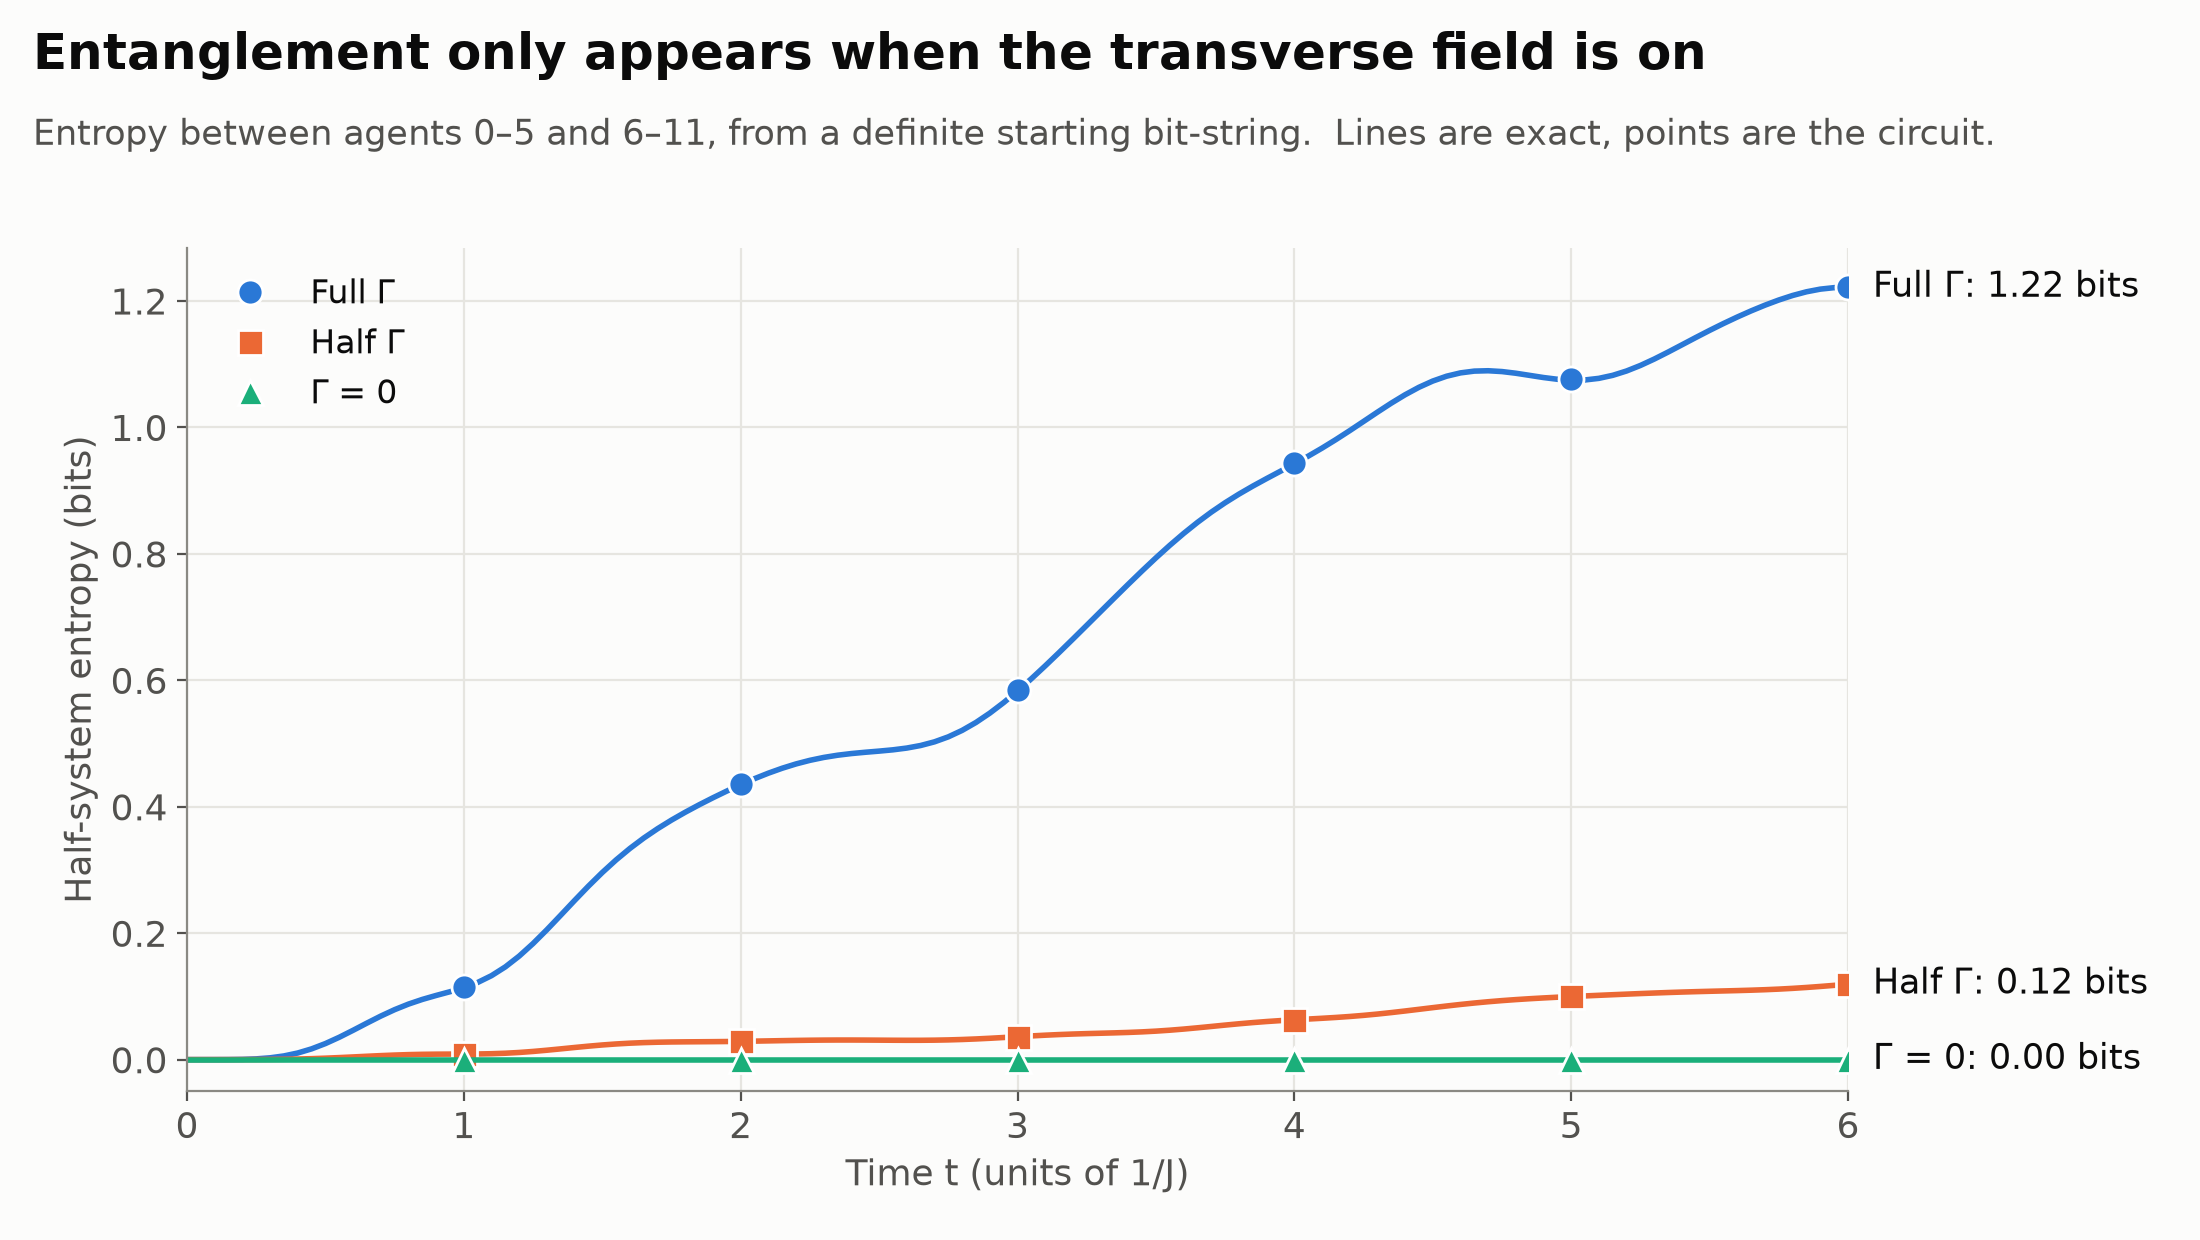

In [36]:
from validation import fig3_entropy

fig3_entropy.main()
show(BUILD / "validation" / "figures" / "fig3_entropy.png")

<a id="p5"></a>
## Part 5: Hardware readiness

The same spec compiles to a real device through the Runtime Estimator with error mitigation. The
8-bank preset is the right size: at most 115 two-qubit gates after transpiling for a Heron device.

**No job has run on real hardware yet.** The table is a noisy simulation with `FakeBoston`, which
uses a real device's noise model. It separates hardware noise (device vs ideal, same circuit) from
Trotter error (ideal vs exact).

In [37]:
%%writefile qecon_src/backends/hardware.py
"""IBM hardware adapter (lottery ticket, not a dependency).

Same spec → same Trotter circuits as the simulator, transpiled for a real device and
run through the Runtime Estimator with error mitigation. Results are cached as JSON in
results/hardware/, where both demos pick them up automatically (matched by a
hash of the spec, so points only appear when the levers are at those settings).

One-time setup (you type the token yourself; it is never stored in this repo):
    python -c "from qiskit_ibm_runtime import QiskitRuntimeService as S; S.save_account(token='...', overwrite=True)"
    (check the channel/instance arguments against the current qiskit-ibm-runtime docs)

Commands (from the repo root):
    # dress rehearsal on a FAKE backend: real device noise model, runs locally, free
    python -m backends.hardware fake   specs/banks.yaml --device FakeBoston

    # real hardware: submit, walk away, fetch later
    python -m backends.hardware submit specs/banks.yaml --device ibm_boston
    python -m backends.hardware fetch  results/hardware/<name>.pending.json

    # see what a run would cost before submitting
    python -m backends.hardware plan   specs/banks.yaml --device FakeBoston

Hardware runs use only a few time points and few Trotter steps: every extra two-qubit
gate costs fidelity (signal ~ exp(-N_2q * error)). Defaults: times 0.5, 1.0, 1.5, 2.0,
first order, 1 step per 0.5 time units.
"""
import argparse
import datetime as dt
import json
import math
import os
import sys

import numpy as np

ROOT = os.path.dirname(os.path.dirname(os.path.abspath(__file__)))
if ROOT not in sys.path:
    sys.path.insert(0, ROOT)

from core.engine import evolve  # noqa: E402
from qecon.api import exact_series, physics_hash, prepare  # noqa: E402

HW_DIR = os.path.join(ROOT, "results", "hardware")


def get_device(name):
    """'Fake*' -> local fake backend with a real device's noise model; else IBM Runtime."""
    if name.startswith("Fake"):
        from qiskit_ibm_runtime import fake_provider
        return getattr(fake_provider, name)()
    from qiskit_ibm_runtime import QiskitRuntimeService
    return QiskitRuntimeService().backend(name)


def build(spec_path, overrides, times, dt_hw, order):
    """Logical circuits + observables + metadata. Nothing device-specific yet."""
    plugin, spec, _ = prepare(spec_path, overrides)
    n = plugin.system()[0]
    H = plugin.hamiltonian()
    steps = [max(1, math.ceil(t / dt_hw - 1e-9)) for t in times]
    circuits = [evolve(H, t, s, plugin.init_ones(), order) for t, s in zip(times, steps)]
    obs = plugin.observables(n)
    return plugin, spec, circuits, obs, steps


def transpile_all(circuits, obs, device):
    from qiskit.transpiler import generate_preset_pass_manager
    pm = generate_preset_pass_manager(optimization_level=3, backend=device, seed_transpiler=7)  # reproducible gate counts
    pubs, stats = [], []
    for qc in circuits:
        isa = pm.run(qc)
        isa_obs = [o.apply_layout(isa.layout) for o in obs]
        pubs.append((isa, isa_obs))
        ops = isa.count_ops()
        twoq = sum(v for k, v in ops.items() if k in ("cz", "cx", "ecr", "rzz"))
        depth2 = isa.depth(lambda ins: ins.operation.num_qubits == 2)
        stats.append({"two_qubit_gates": int(twoq), "two_qubit_depth": int(depth2),
                      "depth": int(isa.depth())})
    return pubs, stats


def make_estimator(device, fake, shots, zne):
    # EstimatorV2 is deprecated since qiskit-ibm-runtime 0.50 (removal >= 3 months later)
    # in favour of the client-side qiskit_ibm_runtime.executor_estimator.Estimator.
    # It still works on 0.51 and its options API is the documented one, so we keep it.
    import warnings
    from qiskit_ibm_runtime import EstimatorV2
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", DeprecationWarning)
        est = EstimatorV2(mode=device)
    est.options.default_shots = shots
    if not fake:
        # Mitigation only matters on real hardware (local fake runs ignore most of it).
        est.options.resilience_level = 1                      # measurement-error mitigation (TREX)
        if zne:
            est.options.resilience.zne_mitigation = True       # zero-noise extrapolation
        est.options.dynamical_decoupling.enable = True
        est.options.twirling.enable_gates = True
    return est


def package(plugin, spec, times, steps, evs, stds, stats, device_name, kind, order, job_id=None):
    """Same economic interpretation as the simulator, plus the noiseless value of the SAME
    shallow circuit (so the gap you see is hardware noise, not Trotter error) and the
    exact evolution."""
    out = plugin.interpret(np.array(times), np.array(evs))
    ideal = plugin.interpret(np.array(times), exact_series_trotter(plugin, times, steps, order))
    exact = plugin.interpret(np.array(times), exact_series(plugin, np.array(times)))
    key = plugin.headline
    std_M = np.array(stds)[:, 0]
    sign = 1 if plugin.headline_from_zero else -1
    return {
        "preset": spec["preset"], "name": spec.get("name"), "spec_hash": physics_hash(spec),
        "kind": kind, "backend": device_name, "job_id": job_id,
        "created": dt.datetime.now().isoformat(timespec="seconds"),
        "times": list(map(float, times)), "trotter_steps": steps, "order": order,
        "series": out["series"], "per_agent": out["per_agent"],
        "stds": {key: (np.abs(sign) * std_M / 2).tolist()},
        "ideal_same_circuit": {key: ideal["series"][key]},
        "exact": {key: exact["series"][key]},
        "circuit_stats": stats,
    }


def exact_series_trotter(plugin, times, steps, order):
    """Noiseless statevector of the exact same (logical) circuits."""
    from qiskit.quantum_info import Statevector
    H = plugin.hamiltonian()
    obs = plugin.observables(plugin.system()[0])
    rows = []
    for t, s in zip(times, steps):
        psi = Statevector(evolve(H, t, s, plugin.init_ones(), order))
        rows.append([float(psi.expectation_value(o).real) for o in obs])
    return np.array(rows)


def save(data, stem):
    os.makedirs(HW_DIR, exist_ok=True)
    path = os.path.join(HW_DIR, f"{stem}.json")
    with open(path, "w", encoding="utf-8") as fh:
        json.dump(data, fh, indent=1)
    return path


def report(data):
    key = next(iter(data["ideal_same_circuit"]))
    print(f"{'t':>5} {'steps':>5} {'2q gates':>8} {'2q depth':>8} {'device':>8} {'ideal':>8} {'exact':>8}")
    for k, t in enumerate(data["times"]):
        s = data["circuit_stats"][k]
        print(f"{t:5.2f} {data['trotter_steps'][k]:5d} {s['two_qubit_gates']:8d} "
              f"{s['two_qubit_depth']:8d} {data['series'][key][k]:8.3f} "
              f"{data['ideal_same_circuit'][key][k]:8.3f} {data['exact'][key][k]:8.3f}")


def main(argv=None):
    p = argparse.ArgumentParser(prog="backends.hardware")
    sub = p.add_subparsers(dest="cmd", required=True)
    for name in ("fake", "submit", "plan"):
        q = sub.add_parser(name)
        q.add_argument("spec")
        q.add_argument("--device", default="FakeBoston" if name != "submit" else None,
                       required=name == "submit")
        q.add_argument("--times", default="0.5,1.0,1.5,2.0")
        q.add_argument("--dt", type=float, default=0.5, help="Trotter step size on hardware")
        q.add_argument("--order", type=int, default=1, choices=[1, 2])
        q.add_argument("--shots", type=int, default=4096)
        q.add_argument("--no-zne", action="store_true")
        q.add_argument("--set", action="append", default=[], metavar="KEY=VALUE")
    f = sub.add_parser("fetch")
    f.add_argument("pending")
    args = p.parse_args(argv)

    if args.cmd == "fetch":
        with open(args.pending, encoding="utf-8") as fh:
            pend = json.load(fh)
        from qiskit_ibm_runtime import QiskitRuntimeService
        job = QiskitRuntimeService().job(pend["job_id"])
        print("status:", job.status())
        res = job.result()
        evs = [np.atleast_1d(r.data.evs) for r in res]
        stds = [np.atleast_1d(r.data.stds) for r in res]
        times = pend["times"]
        plugin, spec, _, _, steps = build(pend["spec"], pend["overrides"], times,
                                          pend["dt"], pend["order"])
        data = package(plugin, spec, times, steps, evs, stds, pend["circuit_stats"],
                       pend["backend"], "hardware", pend["order"], pend["job_id"])
        print("wrote", save(data, pend["stem"]))
        report(data)
        return 0

    times = [float(x) for x in args.times.split(",")]
    plugin, spec, circuits, obs, steps = build(args.spec, args.set, times, args.dt, args.order)
    device = get_device(args.device)
    pubs, stats = transpile_all(circuits, obs, device)
    total = sum(s["two_qubit_gates"] for s in stats)
    print(f"{spec.get('name')} on {args.device}: {plugin.system()[0]} qubits, "
          f"2q gates per circuit {[s['two_qubit_gates'] for s in stats]}, "
          f"2q depth {[s['two_qubit_depth'] for s in stats]}")
    worst = max(s["two_qubit_gates"] for s in stats)
    print(f"rough signal kept at the deepest circuit, exp(-N*3e-3): {math.exp(-worst * 3e-3):.0%}")
    if args.cmd == "plan":
        return 0

    stem = f"{spec.get('name')}_{args.device}"
    if args.cmd == "fake":
        est = make_estimator(device, True, args.shots, False)
        res = est.run(pubs).result()
        evs = [np.atleast_1d(r.data.evs) for r in res]
        stds = [np.atleast_1d(r.data.stds) for r in res]
        data = package(plugin, spec, times, steps, evs, stds, stats, args.device,
                       "noisy simulator, not hardware", args.order)
        print("wrote", save(data, stem))
        report(data)
        return 0

    # submit to real hardware
    est = make_estimator(device, False, args.shots, not args.no_zne)
    job = est.run(pubs)
    pend = {"job_id": job.job_id(), "backend": args.device, "spec": os.path.abspath(args.spec),
            "overrides": args.set, "times": times, "dt": args.dt, "order": args.order,
            "circuit_stats": stats, "stem": stem,
            "submitted": dt.datetime.now().isoformat(timespec="seconds")}
    os.makedirs(HW_DIR, exist_ok=True)
    path = os.path.join(HW_DIR, f"{stem}.pending.json")
    with open(path, "w", encoding="utf-8") as fh:
        json.dump(pend, fh, indent=1)
    print(f"submitted job {job.job_id()} -> {path}")
    print(f"fetch later with:  python -m backends.hardware fetch {path}")
    return 0


if __name__ == "__main__":
    sys.exit(main())


In [38]:
%%writefile qecon_src/results/hardware/banks_core_periphery_8_FakeBoston.json
{
 "preset": "banks",
 "name": "banks_core_periphery_8",
 "spec_hash": "78ba2d8bbd61",
 "kind": "noisy simulator, not hardware",
 "backend": "FakeBoston",
 "job_id": null,
 "created": "2026-11-05T22:40:52",
 "times": [
  0.5,
  1.0,
  1.5,
  2.0
 ],
 "trotter_steps": [
  1,
  2,
  3,
  4
 ],
 "order": 1,
 "series": {
  "fraction_failed": [
   0.194000244140625,
   0.3043212890625,
   0.40106201171875,
   0.41546630859375
  ],
  "magnetization": [
   0.61199951171875,
   0.391357421875,
   0.1978759765625,
   0.1690673828125
  ],
  "synchronization": [
   0.07080078125000001,
   0.12776692708333331,
   0.140625,
   0.1941189236111111
  ]
 },
 "per_agent": {
  "p_one": [
   [
    0.106201171875,
    0.897216796875,
    0.090087890625,
    0.087646484375,
    0.087158203125,
    0.0927734375,
    0.092041015625,
    0.098876953125
   ],
   [
    0.135498046875,
    0.759033203125,
    0.213623046875,
    0.278564453125,
    0.26416015625,
    0.282958984375,
    0.283935546875,
    0.216796875
   ],
   [
    0.20166015625,
    0.694580078125,
    0.283203125,
    0.412109375,
    0.409912109375,
    0.452392578125,
    0.48486328125,
    0.269775390625
   ],
   [
    0.262451171875,
    0.655029296875,
    0.310791015625,
    0.40625,
    0.420166015625,
    0.488525390625,
    0.5244140625,
    0.256103515625
   ]
  ]
 },
 "stds": {
  "fraction_failed": [
   0.004571523759971418,
   0.006606195258219965,
   0.007300299024476276,
   0.007419163972453952
  ]
 },
 "ideal_same_circuit": {
  "fraction_failed": [
   0.1904991444088706,
   0.3074534529234681,
   0.3956154460753202,
   0.4095319371082805
  ]
 },
 "exact": {
  "fraction_failed": [
   0.184009364683824,
   0.29631675967134224,
   0.3807198657767012,
   0.3939988337362165
  ]
 },
 "circuit_stats": [
  {
   "two_qubit_gates": 27,
   "two_qubit_depth": 18,
   "depth": 61
  },
  {
   "two_qubit_gates": 58,
   "two_qubit_depth": 47,
   "depth": 140
  },
  {
   "two_qubit_gates": 85,
   "two_qubit_depth": 67,
   "depth": 211
  },
  {
   "two_qubit_gates": 115,
   "two_qubit_depth": 90,
   "depth": 281
  }
 ]
}

In [39]:
from backends.hardware import main as hardware, report

hardware(["plan", spec_path("banks"), "--device", "FakeBoston"])
print()
report(json.loads((BUILD / "results/hardware/banks_core_periphery_8_FakeBoston.json").read_text()))

banks_core_periphery_8 on FakeBoston: 8 qubits, 2q gates per circuit [27, 58, 85, 115], 2q depth [18, 47, 67, 90]
rough signal kept at the deepest circuit, exp(-N*3e-3): 71%



    t steps 2q gates 2q depth   device    ideal    exact
 0.50     1       27       18    0.194    0.190    0.184
 1.00     2       58       47    0.304    0.307    0.296
 1.50     3       85       67    0.401    0.396    0.381
 2.00     4      115       90    0.415    0.410    0.394


<a id="p6"></a>
## Part 6: The frontend

The live app lets you move policy levers and watch the economy respond. It has three scenarios,
a headline rewritten from the numbers on every run, counterfactuals, light-cones and a spec editor
that shows validator errors. It runs from `demo/streamlit_app.py`.
**Try it:** [https://qecon-q.streamlit.app](https://qecon-q.streamlit.app)

The app calls `demo.server.api_run`, the same function as the local web demo in the repo, so both
share one tested path. The cell below uses that function and that chart. Press Play to watch a
bailed-out economy over time (needs an internet connection to load Plotly).

In [40]:
%%writefile qecon_src/demo/server.py
"""QEcon demo server: the web front end in demo/web/ talks to run_spec over a tiny JSON API.

    python -m demo.server              # -> http://localhost:8501
    python -m demo.server --port 9000

Standard library only (no Flask). demo/streamlit_app.py calls api_run too, so both demos
share one path. Everything runs on the local statevector simulator, so the demo cannot
fail on stage. Hardware points (results/hardware/*.json) are attached to a run when their
spec hash matches the current settings.
"""
import argparse
import json
import mimetypes
import os
import sys
import threading
import traceback
from functools import lru_cache
from http.server import BaseHTTPRequestHandler, ThreadingHTTPServer

ROOT = os.path.dirname(os.path.dirname(os.path.abspath(__file__)))
if ROOT not in sys.path:
    sys.path.insert(0, ROOT)

import yaml  # noqa: E402

from qecon.api import physics_hash, run_spec  # noqa: E402
from qecon.spec import SpecError, load_spec  # noqa: E402

WEB = os.path.join(ROOT, "demo", "web")
HW_DIR = os.path.join(ROOT, "results", "hardware")
SPECS = {"banks": "specs/banks.yaml", "firms": "specs/firms.yaml",
         "taxpayers": "specs/taxpayers.yaml"}
_lock = threading.Lock()     # qiskit/numpy are fine threaded, but keep runs serial & cached


def base_spec(preset):
    s = load_spec(os.path.join(ROOT, SPECS[preset]))
    s.pop("_path", None)
    return s


def counterfactual_overrides(preset, overrides):
    """Banks with a bailout: compare against the same shock without the bailout."""
    if preset == "banks":
        for o in overrides:
            k, _, v = o.partition("=")
            if k == "fields.bailout.nodes" and yaml.safe_load(v):
                return [x for x in overrides if not x.startswith("fields.bailout.nodes=")] \
                    + ["fields.bailout.nodes=[]"], "same shock, no bailout"
    return None, None


@lru_cache(maxsize=512)
def _run(preset, overrides_key, exact):
    overrides = list(json.loads(overrides_key))
    r = run_spec(base_spec(preset), overrides=overrides, baseline=True, exact=exact)
    r["spec_hash"] = physics_hash(r["spec"])
    return r


def hardware_for(result):
    out = []
    if not os.path.isdir(HW_DIR):
        return out
    for f in sorted(os.listdir(HW_DIR)):
        if not f.endswith(".json") or f.endswith(".pending.json"):
            continue
        try:
            with open(os.path.join(HW_DIR, f), encoding="utf-8") as fh:
                d = json.load(fh)
        except (OSError, json.JSONDecodeError):
            continue
        if d.get("preset") == result["preset"] and d.get("spec_hash") == result["spec_hash"]:
            out.append({k: d[k] for k in ("backend", "kind", "times", "series", "stds",
                                          "ideal_same_circuit", "circuit_stats") if k in d})
    return out


def api_run(body):
    preset = body["preset"]
    overrides = [str(o) for o in body.get("overrides", [])]
    key = json.dumps(overrides)
    with _lock:
        r = _run(preset, key, bool(body.get("exact", True)))
        cf_over, cf_label = counterfactual_overrides(preset, overrides)
        cf = _run(preset, json.dumps(cf_over), False) if cf_over else None
    return {"result": r, "counterfactual": cf, "counterfactual_label": cf_label,
            "hardware": hardware_for(r)}


def api_run_yaml(body):
    try:
        spec = yaml.safe_load(body["yaml"])
    except yaml.YAMLError as e:
        return {"ok": False, "errors": [f"Not valid YAML: {e}"]}
    if not isinstance(spec, dict):
        return {"ok": False, "errors": ["The spec must be a mapping (key: value pairs)."]}
    try:
        with _lock:
            r = run_spec(spec)
    except SpecError as e:
        lines = str(e).splitlines()
        return {"ok": False, "title": lines[0], "errors": [x.strip(" -") for x in lines[1:]]}
    return {"ok": True, "headline": r["headline"],
            "peak": max(r["series"][r["headline"]]), "n": r["summary"]["n"]}


def api_presets():
    out = {}
    for p in SPECS:
        s = base_spec(p)
        out[p] = {"spec": s, "yaml": open(os.path.join(ROOT, SPECS[p]), encoding="utf-8").read()}
    return out


class Handler(BaseHTTPRequestHandler):
    def log_message(self, fmt, *args):  # quiet
        pass

    def _send(self, code, body, ctype="application/json"):
        data = body if isinstance(body, bytes) else json.dumps(body).encode()
        self.send_response(code)
        self.send_header("Content-Type", ctype)
        self.send_header("Content-Length", str(len(data)))
        self.send_header("Cache-Control", "no-store")
        self.end_headers()
        self.wfile.write(data)

    def do_GET(self):
        path = self.path.split("?")[0]
        if path == "/api/presets":
            return self._send(200, api_presets())
        if path == "/":
            path = "/index.html"
        full = os.path.normpath(os.path.join(WEB, path.lstrip("/")))
        if not full.startswith(WEB) or not os.path.isfile(full):
            return self._send(404, {"error": "not found"})
        with open(full, "rb") as fh:
            ctype = mimetypes.guess_type(full)[0] or "application/octet-stream"
            return self._send(200, fh.read(), ctype + ("; charset=utf-8" if "text" in ctype or "javascript" in ctype else ""))

    def do_POST(self):
        n = int(self.headers.get("Content-Length", 0))
        try:
            body = json.loads(self.rfile.read(n) or b"{}")
            if self.path == "/api/run":
                return self._send(200, api_run(body))
            if self.path == "/api/run_yaml":
                return self._send(200, api_run_yaml(body))
            return self._send(404, {"error": "not found"})
        except SpecError as e:
            return self._send(400, {"error": str(e)})
        except Exception as e:  # noqa: BLE001
            traceback.print_exc()
            return self._send(500, {"error": f"{type(e).__name__}: {e}"})


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--port", type=int, default=8501)
    ap.add_argument("--host", default="127.0.0.1")
    a = ap.parse_args()
    mimetypes.add_type("text/javascript", ".js")
    mimetypes.add_type("text/css", ".css")
    srv = ThreadingHTTPServer((a.host, a.port), Handler)
    print(f"QEcon demo on http://localhost:{a.port}", flush=True)
    srv.serve_forever()


if __name__ == "__main__":
    main()


In [41]:
%%writefile qecon_src/demo/charts.py
"""Plotly figures for the demo. Fixed categorical order (blue, orange, aqua, yellow),
one-hue blue ramp for P(state 1), recessive axes, text in ink colours."""
import numpy as np
import plotly.graph_objects as go

SURFACE = "#fcfcfb"
INK = "#0b0b0b"
INK2 = "#52514e"
MUTED = "#898781"
GRID = "#e1e0d9"
AXIS = "#c3c2b7"
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
RAMP = [[0.0, "#f4f8fd"], [0.2, "#cde2fb"], [0.4, "#86b6ef"], [0.6, "#3987e5"],
        [0.8, "#1c5cab"], [1.0, "#0d366b"]]


def _layout(fig, title, height=420, **kw):
    fig.update_layout(
        title=dict(text=title, x=0, xanchor="left", font=dict(size=15, color=INK)),
        paper_bgcolor=SURFACE, plot_bgcolor=SURFACE, height=height,
        margin=dict(l=10, r=10, t=50, b=10), font=dict(color=INK2, size=12),
        hoverlabel=dict(bgcolor="white", font_color=INK), **kw)
    fig.update_xaxes(gridcolor=GRID, linecolor=AXIS, zeroline=False, tickfont_color=MUTED)
    fig.update_yaxes(gridcolor=GRID, linecolor=AXIS, zeroline=False, tickfont_color=MUTED)
    return fig


def headline_chart(r, rc=None, rc_label=None, hw=(), baseline_label="baseline"):
    key = r["headline"]
    t = r["times"]
    fig = go.Figure()
    if "baseline" in r:
        fig.add_trace(go.Scatter(x=t, y=r["baseline"]["series"][key], name=baseline_label,
                                 line=dict(color=AQUA, width=2)))
    if rc is not None:
        fig.add_trace(go.Scatter(x=t, y=rc["series"][key], name=rc_label,
                                 line=dict(color=ORANGE, width=2)))
    fig.add_trace(go.Scatter(x=t, y=r["series"][key], name="current policy (Trotter circuit)",
                             line=dict(color=BLUE, width=2.5)))
    if "exact" in r:
        fig.add_trace(go.Scatter(x=t, y=r["exact"]["series"][key], name="exact expm",
                                 line=dict(color=INK2, width=1.2, dash="dot")))
    for d in hw:
        err = d.get("stds", {}).get(key)
        fig.add_trace(go.Scatter(
            x=d["times"], y=d["series"][key], mode="markers",
            name=f"{d.get('backend', 'hardware')} ({d.get('kind', 'hardware')})",
            marker=dict(color=YELLOW, size=11, symbol="diamond",
                        line=dict(color=SURFACE, width=2)),
            error_y=dict(type="data", array=err, visible=err is not None, color=YELLOW)))
    fig.update_yaxes(range=[-0.02, 1.02], tickformat=".0%", title=r["headline_label"])
    fig.update_xaxes(title="time (units of 1/J)")
    fig.update_traces(hovertemplate="t = %{x:.2f}<br>%{y:.1%}")
    return _layout(fig, r["headline_label"], hovermode="x unified",
                   legend=dict(orientation="h", y=-0.32, x=0))


def _sorted(r):
    d = np.array(r["graph"]["distance_from_seed"])
    d = np.where(d < 0, d.max() + 1, d)
    return np.argsort(d, kind="stable"), d


def heatmap(r, title):
    order, d = _sorted(r)
    P = np.array(r["per_agent"]["p_one"])[:, order].T
    names = [f"{r['labels'][i]} (d={d[i]})" for i in order]
    fig = go.Figure(go.Heatmap(
        z=P, x=r["times"], y=names, zmin=0, zmax=1, colorscale=RAMP, xgap=1, ygap=2,
        colorbar=dict(title=f"P({r['states']['1']})", tickformat=".0%", outlinewidth=0),
        hovertemplate="%{y}<br>t = %{x:.2f}<br>P = %{z:.1%}<extra></extra>"))
    fig.update_yaxes(autorange="reversed", gridcolor=SURFACE)
    fig.update_xaxes(title="time (units of 1/J)", gridcolor=SURFACE)
    return _layout(fig, title, height=max(320, 32 * len(order) + 120))


def network_chart(r):
    """Agents as nodes coloured by P(state 1), animated over time (play button + slider)."""
    g = r["graph"]
    pos = np.array([g["positions"][str(i)] for i in range(g["n"])])
    P = np.array(r["per_agent"]["p_one"])
    t = r["times"]
    jmax = max((e[2] for e in g["edges"]), default=1.0) or 1.0

    edge_traces = []
    for i, j, J in g["edges"]:
        edge_traces.append(go.Scatter(
            x=[pos[i, 0], pos[j, 0]], y=[pos[i, 1], pos[j, 1]], mode="lines",
            line=dict(color=AXIS, width=1 + 4 * J / jmax), hoverinfo="skip", showlegend=False))

    # Grids are dense, so they get smaller nodes and just the coordinates as labels.
    names = [x.replace("Firm ", "").replace("Taxpayer ", "") for x in r["labels"]]
    node_size = 34 if g["n"] <= 8 else 24

    def nodes(k):
        return go.Scatter(
            x=pos[:, 0], y=pos[:, 1], mode="markers+text", text=names,
            textposition="top center", textfont=dict(size=11, color=INK2),
            customdata=np.stack([P[k], g["h"]], axis=1),
            hovertemplate="%{text}<br>P(" + r["states"]["1"] + ") = %{customdata[0]:.1%}"
                          "<br>h = %{customdata[1]:.2f}<extra></extra>",
            marker=dict(size=node_size, color=P[k], cmin=0, cmax=1, colorscale=RAMP,
                        line=dict(color=[INK if i in g["init_ones"] else SURFACE
                                         for i in range(g["n"])], width=2.5),
                        colorbar=dict(title=f"P({r['states']['1']})", tickformat=".0%",
                                      outlinewidth=0, len=0.8)),
            showlegend=False)

    # open on the moment the headline peaks, so a slider change is visible immediately
    y = np.array(r["series"][r["headline"]])
    start = int(np.argmin(y) if r.get("states", {}).get("0") == "comply" else np.argmax(y))
    fig = go.Figure(data=edge_traces + [nodes(start)])
    ne = len(edge_traces)
    fig.frames = [go.Frame(data=[nodes(k)], traces=[ne], name=f"{t[k]:.2f}")
                  for k in range(len(t))]
    fig.update_layout(
        updatemenus=[dict(type="buttons", x=0, y=-0.02, xanchor="left", yanchor="top",
                          direction="left", pad=dict(t=0, r=8),
                          buttons=[dict(label="▶ Play", method="animate",
                                        args=[None, dict(frame=dict(duration=180, redraw=True),
                                                         transition=dict(duration=0),
                                                         fromcurrent=True)]),
                                   dict(label="❚❚", method="animate",
                                        args=[[None], dict(mode="immediate",
                                                           frame=dict(duration=0))])])],
        sliders=[dict(active=start, x=0.17, len=0.83, y=-0.02, yanchor="top", pad=dict(t=0),
                      currentvalue=dict(prefix="t = ", font=dict(color=INK2)),
                      font=dict(color="rgba(0,0,0,0)"), ticklen=0, minorticklen=0,
                      tickcolor="rgba(0,0,0,0)",
                      steps=[dict(label=f.name, method="animate",
                                  args=[[f.name], dict(mode="immediate",
                                                       frame=dict(duration=0, redraw=True))])
                             for f in fig.frames])])
    fig.update_xaxes(visible=False)
    fig.update_yaxes(visible=False, scaleanchor="x")
    return _layout(fig, f"Network at t = {t[start]:.2f} (peak): colour = P({r['states']['1']}), "
                        "outlined = seeded",
                   height=470)


In [42]:
%%writefile qecon_src/demo/streamlit_app.py
"""QEcon live demo for Streamlit.

    streamlit run demo/streamlit_app.py

Runs through demo.server.api_run, the same path as the local web demo, so levers,
counterfactuals and hardware matching behave identically in both. Everything runs on
the statevector simulator. Hardware points appear only when results/hardware/ has a run
for the current settings.
"""
import os
import sys

ROOT = os.path.dirname(os.path.dirname(os.path.abspath(__file__)))
if ROOT not in sys.path:
    sys.path.insert(0, ROOT)

import numpy as np  # noqa: E402
import streamlit as st  # noqa: E402
import yaml  # noqa: E402

from demo import charts  # noqa: E402
from demo.server import api_run, base_spec  # noqa: E402
from plugins.common import human_bytes  # noqa: E402
from qecon.api import prepare, run_spec, trotter_schedule  # noqa: E402
from qecon.spec import SpecError  # noqa: E402

# A public app shares one small machine, so the spec editor gets tighter limits than the
# command line. Each extra agent doubles the memory and the time.
PUBLIC_MAX_AGENTS = 14
PUBLIC_MAX_TIMES = 61
PUBLIC_MAX_T = 30.0
PUBLIC_MAX_STEPS = 600

SCENARIOS = {
    "banks": {
        "tab": "Contagion",
        "title": "Interbank contagion",
        "baseline": "no shock",
        "dek": "Eight banks linked by cross-holdings (Elliott–Golub–Jackson). Each bank is a "
               "qubit: |0⟩ solvent, |1⟩ insolvent. One bank's capital is wiped out and losses "
               "travel along exposures.",
        "mapping": [("J · ZZ", "exposure between banks (symmetrised EGJ dependency matrix)"),
                    ("h · Z", "capital above the Basel III 7% minimum, −2 on the failed bank, plus any bailout"),
                    ("Γ · X", "liquidity and rollover uncertainty")],
    },
    "firms": {
        "tab": "Inflation",
        "title": "Inflation expectations",
        "baseline": "money on target",
        "dek": "Twelve firms on a 4 × 3 supply grid. A firm raises its price when its neighbours "
               "do. Money growth above the 2% target tilts every firm toward raising, and "
               "credibility anchors them.",
        "mapping": [("J · ZZ", "strategic complementarity in pricing between supply-chain neighbours"),
                    ("h · Z", "anchor × credibility − 0.1 × (money growth − 2%) − 0.05 × ΔVAT"),
                    ("Γ · X", "uncertainty about rivals' pricing")],
    },
    "taxpayers": {
        "tab": "Compliance",
        "title": "Tax compliance",
        "baseline": "no evaders",
        "dek": "Twelve taxpayers on a lattice, three evading at the start: the Zaklan Ising "
               "model, made coherent. Audits and penalties add a compliance field, and a higher "
               "tax rate pushes the other way.",
        "mapping": [("J · ZZ", "social influence and conditional cooperation between neighbours"),
                    ("h · Z", "tax morale + audit probability × penalty − 0.05 × (tax rate − 30%)"),
                    ("Γ · X", "ambivalence")],
    },
}


def public_limit_errors(spec):
    """Raises SpecError for an invalid spec. Returns a list of reasons it is too big to host."""
    plugin, checked, _ = prepare(spec)
    sim = checked["simulation"]
    n = plugin.system()[0]
    t_max, n_times = float(sim["t_max"]), int(sim["n_times"])
    problems = []
    if n > PUBLIC_MAX_AGENTS:
        problems.append(f"{n} agents: the hosted app allows {PUBLIC_MAX_AGENTS}. "
                        "Larger runs work from the command line.")
    if n_times > PUBLIC_MAX_TIMES:
        problems.append(f"simulation.n_times = {n_times}: the hosted app allows {PUBLIC_MAX_TIMES}.")
    if t_max > PUBLIC_MAX_T:
        problems.append(f"simulation.t_max = {t_max:g}: the hosted app allows {PUBLIC_MAX_T:g}.")
    if not problems:
        steps, block = trotter_schedule(sim, np.linspace(0.0, t_max, n_times))
        cost = steps[-1] if block else sum(steps)
        if cost > PUBLIC_MAX_STEPS:
            problems.append(f"{cost} Trotter steps: the hosted app allows {PUBLIC_MAX_STEPS}. "
                            "Use a larger simulation.dt or fewer time points.")
    return problems


def number(value, decimals=2):
    """Lever value as YAML text. Rounding removes float noise such as 0.6000000000000001,
    so the default levers still match the cached hardware run."""
    return repr(round(float(value), decimals))


def bank_levers(spec):
    labels = spec["agents"]["labels"]
    f = spec["fields"]
    st.sidebar.subheader("Shock")
    seed_name = st.sidebar.selectbox("Bank that fails", labels, index=f["shock"]["nodes"][0],
                                     key="banks.seed")
    seed = labels.index(seed_name)
    st.sidebar.subheader("Policy")
    # The key includes the seed, so a failed bank can never stay selected for a bailout.
    bail_names = st.sidebar.multiselect("Bail out", [x for x in labels if x != seed_name],
                                        key=f"banks.bail.{seed}",
                                        help="Adds an extra solvency field to these banks")
    bail = sorted(labels.index(x) for x in bail_names)
    size = st.sidebar.slider("Bailout size", 0.0, 4.0, float(f["bailout"]["strength"]), 0.25,
                             key="banks.size", help="Extra solvency field, in units of J")
    kappa = st.sidebar.slider("Capital sensitivity κ", 0.0, 0.3, float(f["kappa"]), 0.01,
                              key="banks.kappa", help="h = κ × (CET1 − 7%)")
    levers = {"seed": seed, "bail": bail}
    overrides = [f"initial.ones=[{seed}]", f"fields.shock.nodes=[{seed}]",
                 f"fields.bailout.nodes={bail}", f"fields.bailout.strength={number(size)}",
                 f"fields.kappa={number(kappa)}"]
    return levers, overrides


def firm_levers(spec):
    f = spec["fields"]
    st.sidebar.subheader("Monetary policy")
    money = st.sidebar.slider("Money-supply growth (%)", 0.0, 25.0, float(f["money_growth"]), 1.0,
                              key="firms.money")
    cred = st.sidebar.slider("Central-bank credibility", 0.0, 1.0, float(f["credibility"]), 0.05,
                             key="firms.cred")
    st.sidebar.subheader("Fiscal policy")
    vat = st.sidebar.slider("VAT change (pp)", -5.0, 10.0, float(f["vat_change"]), 0.5,
                            key="firms.vat")
    return {"money": money}, [f"fields.money_growth={number(money, 0)}",
                              f"fields.credibility={number(cred)}",
                              f"fields.vat_change={number(vat, 1)}"]


def taxpayer_levers(spec):
    f = spec["fields"]
    st.sidebar.subheader("Enforcement")
    audit = st.sidebar.slider("Audit probability", 0.0, 0.3, float(f["audit_prob"]), 0.01,
                              key="taxpayers.audit")
    penalty = st.sidebar.slider("Penalty (periods)", 0, 20, int(f["penalty"]), 1,
                                key="taxpayers.penalty",
                                help="Periods of forced honesty (Zaklan's k)")
    st.sidebar.subheader("Tax")
    rate = st.sidebar.slider("Tax rate (%)", 10.0, 60.0, float(f["tax_rate"]), 1.0,
                             key="taxpayers.rate")
    return {"audit": audit}, [f"fields.audit_prob={number(audit)}", f"fields.penalty={int(penalty)}",
                              f"fields.tax_rate={number(rate, 0)}"]


LEVERS = {"banks": bank_levers, "firms": firm_levers, "taxpayers": taxpayer_levers}


def join_names(names):
    return names[0] if len(names) == 1 else f"{', '.join(names[:-1])} and {names[-1]}"


def extreme(preset, values):
    """Compliance is bad when it is low. Everything else is bad when it is high."""
    return min(values) if preset == "taxpayers" else max(values)


def headline(preset, levers, gamma, r, cf):
    """One sentence rewritten from the numbers on every run."""
    key = r["headline"]
    y = r["series"][key]
    peak = extreme(preset, y)
    base = extreme(preset, r["baseline"]["series"][key])
    if preset == "banks":
        labels = r["labels"]
        seed = labels[levers["seed"]]
        if gamma == 0:
            return f"With Γ = 0 every term commutes: {seed} stays failed and no other bank moves."
        if levers["bail"] and cf:
            names = join_names([labels[i] for i in levers["bail"]])
            return (f"Bailing out {names} holds peak insolvency to **{peak:.0%}**, "
                    f"down from {max(cf['series'][key]):.0%}.")
        ratio = peak / max(base, 1e-9)
        tail = f", {ratio:.1f}× the background rate." if ratio > 1.25 else ", barely above background noise."
        return f"When {seed} fails, up to **{peak:.0%}** of the banking system is insolvent{tail}"
    if preset == "firms":
        if gamma == 0:
            return "With Γ = 0 nothing moves: firms hold their prices whatever the central bank does."
        gap, money = peak - base, f"{levers['money']:.0f}%"
        if gap > 0.15:
            return f"At {money} money growth, expectations de-anchor: up to **{peak:.0%}** of firms raise prices."
        if gap > 0.04:
            return f"At {money} money growth, up to **{peak:.0%}** of firms raise prices, {gap * 100:.0f} points above target."
        return f"At {money} money growth, expectations stay anchored: at most **{peak:.0%}** of firms raise prices."
    if gamma == 0:
        return "With Γ = 0 nothing moves: the evaders stay evaders and everyone else stays honest."
    tail = " as the evaders pull their neighbours along." if peak < y[0] - 0.03 else "; the evaders stay contained."
    return f"With a {levers['audit']:.0%} audit rate, compliance bottoms out at **{peak:.0%}**{tail}"


def points(x):
    return f"{x * 100:+.0f} pts"


def show_stats(preset, levers, r, cf):
    key = r["headline"]
    y = np.array(r["series"][key])
    base = np.array(r["baseline"]["series"][key])
    low = preset == "taxpayers"
    k = int(np.argmin(y) if low else np.argmax(y))
    at = f"at t = {r['times'][k]:.2f}"
    cols = st.columns(4)
    if preset == "banks":
        P = np.array(r["per_agent"]["p_one"])
        B = np.array(r["baseline"]["per_agent"]["p_one"])
        excess = (P - B).max(axis=0)
        excess[levers["seed"]] = -np.inf
        worst = int(np.argmax(excess))
        cols[0].metric("Peak insolvent", f"{y.max():.0%}", help=at)
        cols[1].metric("Contagion", points((y - base).max()), help="Above the no-shock background")
        cols[2].metric("Most exposed", r["labels"][worst],
                       help=f"Peak {P[:, worst].max():.0%} vs {B[:, worst].max():.0%} background")
        effect = points(y.max() - max(cf["series"][key])) if cf else "none"
        cols[3].metric("Bailout effect", effect, help="Against the same shock with no bailout")
    elif preset == "firms":
        half = int(np.argmax(y >= y.max() / 2))
        cols[0].metric("Peak raising prices", f"{y.max():.0%}", help=at)
        cols[1].metric("vs on-target economy", points(y.max() - base.max()),
                       help="Peak share, against money growth at target")
        cols[2].metric("Time to half peak", f"{r['times'][half]:.2f} / J", help="Speed of propagation")
        cols[3].metric("Neighbour agreement", f"{r['series']['synchronization'][k]:.2f}",
                       help="⟨ZᵢZⱼ⟩ at the peak")
    else:
        cols[0].metric("Lowest compliance", f"{y.min():.0%}", help=at)
        cols[1].metric("vs no evaders", points(y.min() - base.min()),
                       help="Lowest compliance, against a lattice with no evaders")
        cols[2].metric("Starting compliance", f"{y[0]:.0%}")
        cols[3].metric("Neighbour agreement", f"{r['series']['synchronization'][k]:.2f}",
                       help="⟨ZᵢZⱼ⟩ at the lowest point")


def show_model(preset, r):
    s = r["summary"]
    g = r["graph"]
    st.latex(r"H=-\sum_{(i,j)}J_{ij}Z_iZ_j-\sum_i h_iZ_i-\sum_i\Gamma_iX_i")
    st.markdown("\n".join(f"- **{term}**: {meaning}" for term, meaning in SCENARIOS[preset]["mapping"]))
    cols = st.columns(4)
    cols[0].metric("Qubits", s["n"])
    cols[1].metric("Exact memory", human_bytes(s["statevector_bytes"]), help="16 · 2ⁿ bytes")
    cols[2].metric("Two-qubit gates per step", s["cx_per_step"],
                   help=f"{s['rzz_per_step']} RZZ at 2 CX each, order {s['order']}, before routing")
    if "trotter_max_error" in r:
        cols[3].metric("Max error vs exact", f"{r['trotter_max_error']:.1e}",
                       help="Trotter circuit against the exact matrix exponential")
    left, right = st.columns([1.3, 1])
    rows = ["| Agent | h | Γ | Starts as | Hops from seed |", "|---|---:|---:|---|---:|"]
    for i in range(g["n"]):
        start = r["states"]["1"] if i in g["init_ones"] else r["states"]["0"]
        rows.append(f"| {r['labels'][i]} | {g['h'][i]:+.3f} | {g['gamma'][i]:.2f} | {start} "
                    f"| {g['distance_from_seed'][i]} |")
    left.markdown("\n".join(rows))
    rows = ["| Link | J |", "|---|---:|"]
    rows += [f"| {r['labels'][i]} – {r['labels'][j]} | {J:.3f} |" for i, j, J in g["edges"]]
    right.markdown("\n".join(rows))
    st.markdown("**Sources**")
    st.markdown("\n".join(f"- *{k}*: {v}" for k, v in r["sources"].items()))


def show_spec_editor(preset, r):
    st.markdown("The YAML behind the current levers. Edit it and press **Validate and run**. "
                "The validator lists every problem before anything expensive starts.")
    text = st.text_area("Spec", yaml.safe_dump(r["spec"], sort_keys=False, allow_unicode=True),
                        height=420, label_visibility="collapsed", key=f"spec.{preset}")
    if not st.button("Validate and run", type="primary", key=f"run.{preset}"):
        return
    try:
        spec = yaml.safe_load(text)
    except yaml.YAMLError as e:
        st.error(f"Not valid YAML: {e}")
        return
    if not isinstance(spec, dict):
        st.error("The spec must be a mapping of key: value pairs.")
        return
    try:
        too_big = public_limit_errors(spec)
        if too_big:
            st.error("\n\n".join(too_big))
            return
        custom = run_spec(spec)
    except SpecError as e:
        st.error(f"```\n{e}\n```")
        return
    key = custom["headline"]
    st.success(f"Valid. Compiled {custom['summary']['n']} qubits. "
               f"{custom['headline_label']} reaches {max(custom['series'][key]):.0%}.")
    st.plotly_chart(charts.headline_chart(custom), width="stretch")


def reset_levers(preset):
    for key in list(st.session_state):
        if key.startswith((f"{preset}.", f"gamma.{preset}", f"spec.{preset}")):
            del st.session_state[key]


def main():
    st.set_page_config(page_title="QEcon", layout="wide")
    st.sidebar.title("QEcon")
    st.sidebar.caption("Economic network → Ising Hamiltonian → Trotter circuit")
    preset = st.sidebar.radio("Scenario", list(SCENARIOS), key="scenario",
                              format_func=lambda p: SCENARIOS[p]["tab"])
    spec = base_spec(preset)
    levers, overrides = LEVERS[preset](spec)
    st.sidebar.subheader("Uncertainty (the quantum term)")
    gamma = st.sidebar.slider("Transverse field Γ", 0.0, 1.5, float(spec["uncertainty"]["gamma"]),
                              0.05, key=f"gamma.{preset}",
                              help="The only non-commuting term. At 0, nothing can move.")
    gamma = round(gamma, 2)
    overrides.append(f"uncertainty.gamma={number(gamma)}")
    st.sidebar.button("Reset levers", on_click=reset_levers, args=(preset,))

    try:
        with st.spinner("Compiling the Hamiltonian and simulating circuits…"):
            response = api_run({"preset": preset, "overrides": overrides, "exact": True})
    except SpecError as e:
        st.error(f"```\n{e}\n```")
        st.stop()

    r, cf = response["result"], response["counterfactual"]
    scenario = SCENARIOS[preset]
    st.caption(scenario["title"].upper())
    st.markdown(f"### {headline(preset, levers, gamma, r, cf)}")
    st.markdown(scenario["dek"])
    show_stats(preset, levers, r, cf)
    for warning in r["warnings"]:
        st.warning(warning)

    dynamics, cone, model, editor, about = st.tabs(
        ["Dynamics", "Light-cone", "Model", "Spec", "What we claim"])
    with dynamics:
        left, right = st.columns([1.05, 1])
        with left:
            st.plotly_chart(charts.headline_chart(r, cf, response["counterfactual_label"],
                                                  response["hardware"], scenario["baseline"]),
                            width="stretch")
        with right:
            st.plotly_chart(charts.network_chart(r), width="stretch")
        notes = []
        if "trotter_max_error" in r:
            notes.append(f"Trotter circuit vs exact evolution: max error {r['trotter_max_error']:.1e}.")
        notes += [f"Diamonds are {d.get('backend')}: {d.get('kind')}." for d in response["hardware"]]
        st.caption(" ".join(notes))
    with cone:
        left, right = st.columns(2)
        other = cf if cf else r["baseline"]
        name = response["counterfactual_label"] if cf else scenario["baseline"]
        with left:
            st.plotly_chart(charts.heatmap(r, "Current policy"), width="stretch")
        with right:
            st.plotly_chart(charts.heatmap({**r, "per_agent": other["per_agent"]}, f"Compared with: {name}"),
                            width="stretch")
        st.caption("Rows are sorted by hops from the seeded agent. Γ flips agents on their own, so "
                   "contagion is the difference between the two panels. Coherent dynamics is "
                   "reversible, so a cascade can partly un-spread.")
    with model:
        show_model(preset, r)
    with editor:
        show_spec_editor(preset, r)
    with about:
        st.markdown("""
**We claim** a working, validated compiler from an economic spec to a quantum circuit. For this
coherent model, exact classical simulation needs 16·2ⁿ bytes, while circuit size grows linearly
with the number of interactions.

**We do not claim** better economic forecasts, a speedup over classical econophysics (those
models are classical Monte Carlo), or that people or economies are physically quantum.

- Scales such as κ, β and Γ are dimensionless calibration knobs, not estimated from data.
- Bank data is illustrative, not real institutions.
- Real exposure is directed. A Hermitian ZZ coupling is symmetric, so direction is lost.
- Entanglement here is a correlation measure of the model, not a claim about real agents.
- Tensor networks can go well beyond exact state vectors when entanglement stays low.
""")


main()


In [43]:
%%writefile qecon_src/demo/requirements.txt
# Streamlit Community Cloud reads this file first because it sits next to the entrypoint.
# Only what demo/streamlit_app.py imports. The full set is in the root requirements.txt.
qiskit==2.6.2
numpy
scipy
networkx
pyyaml
plotly
streamlit


In [44]:
%%writefile qecon_src/.streamlit/config.toml
[theme]
base = "light"
primaryColor = "#2a78d6"
backgroundColor = "#fcfcfb"
secondaryBackgroundColor = "#f3f2ee"
textColor = "#0b0b0b"

[browser]
gatherUsageStats = false


In [45]:
from demo import charts
from demo.server import api_run

# The default levers, sent through the same function the app calls.
levers = ["initial.ones=[1]", "fields.shock.nodes=[1]", "fields.bailout.nodes=[0]",
          "fields.bailout.strength=2.0", "fields.kappa=0.05", "uncertainty.gamma=0.6"]
response = api_run({"preset": "banks", "overrides": levers})
print("Counterfactual:", response["counterfactual_label"])
figure = charts.network_chart(response["result"])
display(HTML(figure.to_html(include_plotlyjs="cdn", full_html=False)))

Counterfactual:

 same shock, no bailout


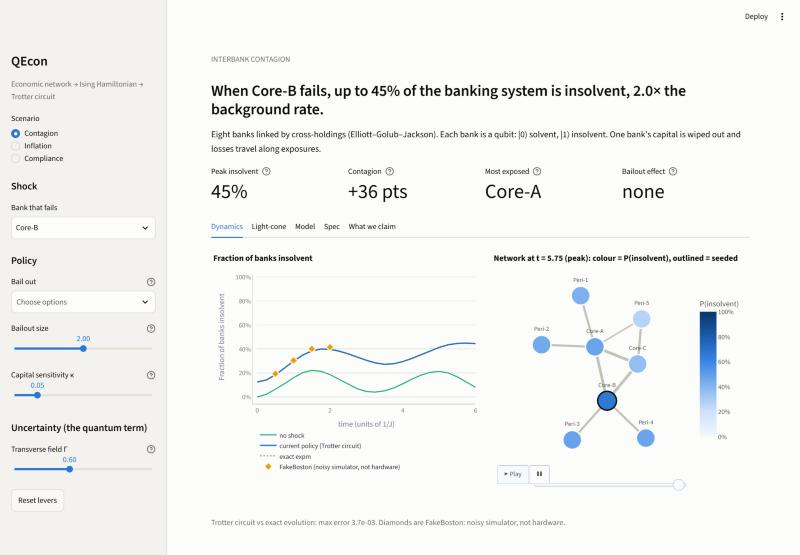

In [46]:
from base64 import b64decode

display(Image(data=b64decode("..."), width=900))

<a id="p7"></a>
## Part 7: The full test suite

The project's own tests run here against the code embedded above. Two groups run only from the
repo, because they need files that aren't embedded: the web-server tests and the headless tests of
the Streamlit app.

In [47]:
%%writefile qecon_src/conftest.py
# Lets pytest import core/, plugins/ and qecon/ from the repo root.
import os
import sys

sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))

# The submission notebook writes a copy of the project here. Its tests are not separate tests.
collect_ignore = ["qecon_src"]


In [48]:
%%writefile qecon_src/validation/test_engine.py
"""The gate: no figure counts until these pass.

Run from the repo root:  python -m pytest validation -q
Each test is a judge question answered in advance.
"""
import numpy as np
import pytest
from qiskit.quantum_info import Statevector, entropy, partial_trace

from core.engine import compile_ising, evolve, exact_state
from validation import glauber, reference as ref
from validation.systems import FIT_FROM, STEPS, T_REF, standard_system

TIGHT = 1e-12


def compile_system(s):
    return compile_ising(s.n, s.edges, s.h, s.gamma)


def trotter_state(s, t, steps, order):
    return Statevector(evolve(compile_system(s), t, steps, s.init_ones, order)).data


@pytest.fixture(scope="module")
def system():
    return standard_system()


@pytest.fixture(scope="module")
def classical():
    return standard_system(gamma_scale=0.0)


def test_engine_hamiltonian_matches_independent_build(system):
    engine_H = compile_system(system).to_matrix(sparse=True).tocsc()
    independent_H = ref.hamiltonian(system.n, system.edges, system.h, system.gamma)
    assert abs(engine_H - independent_H).max() < TIGHT


def test_engine_exact_state_matches_independent_evolution(system):
    engine = exact_state(compile_system(system), T_REF, system.init_ones)
    assert abs(ref.infidelity(engine, ref.exact_evolve(system, T_REF))) < TIGHT


def test_seeded_agents_land_on_the_right_qubits(system):
    psi = trotter_state(system, 0.0, 1, 2)
    expected = np.ones(system.n)
    expected[list(system.init_ones)] = -1.0
    assert np.allclose(ref.z_expectations(psi, system.n), expected, atol=TIGHT)


@pytest.mark.parametrize("t", [0.3, 1.1, 2.7])
def test_single_qubit_matches_analytic_rotation(t):
    """Catches the classic factor of 2: <Z>(t) = cos(2 Gamma t)."""
    gamma = 0.7
    psi = Statevector(evolve(compile_ising(1, {}, [0.0], [gamma]), t, 1)).data
    assert abs(abs(psi[0]) ** 2 - abs(psi[1]) ** 2 - np.cos(2 * gamma * t)) < TIGHT


@pytest.mark.parametrize("steps", STEPS)
@pytest.mark.parametrize("order", [1, 2])
def test_gamma_zero_has_no_motion_and_no_error(classical, steps, order):
    """The most important test: with the transverse field off, nothing happens."""
    t = 2.3
    psi = trotter_state(classical, t, steps, order)
    start = ref.basis_state(classical.n, classical.init_ones)
    assert np.abs(np.abs(psi) ** 2 - np.abs(start) ** 2).max() < TIGHT
    assert abs(ref.infidelity(psi, ref.exact_evolve(classical, t))) < TIGHT


def test_circuit_really_trotterizes(system):
    """Guards the trap: un-unrolled circuits silently evolve exactly."""
    exact = ref.exact_evolve(system, T_REF)
    for order in (1, 2):
        assert ref.infidelity(trotter_state(system, T_REF, 1, order), exact) > 1e-3


@pytest.mark.parametrize("order,expected,tolerance", [(1, -2.0, 0.2), (2, -4.0, 0.3)])
def test_infidelity_converges_at_theoretical_rate(system, order, expected, tolerance):
    exact = ref.exact_evolve(system, T_REF)
    values = [ref.infidelity(trotter_state(system, T_REF, r, order), exact) for r in STEPS]
    assert abs(ref.slope(STEPS, values, FIT_FROM) - expected) < tolerance


@pytest.mark.parametrize("steps", STEPS)
def test_orders_agree_on_every_z_basis_probability(system, steps):
    """Order 1 and 2 differ by diagonal phases only. Needs all Z terms before X terms."""
    first = trotter_state(system, T_REF, steps, 1)
    second = trotter_state(system, T_REF, steps, 2)
    assert np.abs(np.abs(first) ** 2 - np.abs(second) ** 2).max() < TIGHT


def test_entropy_two_independent_routes_agree(system):
    state = Statevector(trotter_state(system, T_REF, 12, 2))
    n = system.n
    via_qiskit = entropy(partial_trace(state, list(range(n // 2, n))), base=2)
    assert abs(ref.half_entropy(state.data, n) - via_qiskit) < 1e-9


def test_gamma_zero_entropy_stays_zero(classical):
    for t in (0.5, 2.0, 4.0):
        psi = trotter_state(classical, t, 16, 2)
        assert ref.half_entropy(psi, classical.n) < 1e-9


def test_glauber_energy_matches_hamiltonian_diagonal(classical):
    """The classical baseline must use the same signs as the quantum model."""
    n = classical.n
    J = glauber.coupling_matrix(n, classical.edges)
    diagonal = ref.diagonal_energy(n, classical.edges, classical.h)
    assert np.allclose(glauber.energy(ref.spins(n).T.astype(float), J, classical.h), diagonal)


def test_glauber_reaches_the_exact_boltzmann_average(classical):
    """Long-run Glauber must match the thermal average summed over all 4096 states."""
    temperature = 2.5
    n = classical.n
    energies = ref.diagonal_energy(n, classical.edges, classical.h)
    weights = np.exp(-(energies - energies.min()) / temperature)
    exact = (ref.spins(n) @ (weights / weights.sum()))
    history = glauber.run(classical, temperature, sweeps=300)
    assert np.abs(history[-100:].mean(axis=0) - exact).max() < 0.02


def test_glauber_replicas_update_independently(classical):
    """Shared site choices would leave a seeded agent untouched in every replica at once."""
    history = glauber.run(classical, 2.5, sweeps=1)
    assert -1.0 < history[1][classical.init_ones[0]] < 1.0
    # A replica visits a given agent in a sweep with probability 1 - (1 - 1/n)^n, and a
    # visit moves that agent's spin by at most 2, which bounds the ensemble mean's jump.
    n = classical.n
    largest_possible_jump = 2 * (1 - (1 - 1 / n) ** n)
    per_sweep_jump = np.abs(np.diff(glauber.run(classical, 1.0, sweeps=10), axis=0)).max()
    assert per_sweep_jump < largest_possible_jump + 0.05


def test_glauber_flip_cost_matches_energy_difference(classical):
    n = classical.n
    J = glauber.coupling_matrix(n, classical.edges)
    rng = np.random.default_rng(0)
    s = rng.choice([-1.0, 1.0], size=(50, n))
    for i in range(n):
        flipped = s.copy()
        flipped[:, i] *= -1.0
        difference = glauber.energy(flipped, J, classical.h) - glauber.energy(s, J, classical.h)
        assert np.allclose(glauber.flip_cost(s, i, J, classical.h), difference)


In [49]:
%%writefile qecon_src/tests/test_plugins.py
"""Tests for Isha's workstream: specs, validator, plugins, CLI.

    python -m pytest tests -q
"""
import copy
import json
import os
import subprocess
import sys

import numpy as np
import pytest

from plugins import REGISTRY
from plugins.banks import coupling_matrix, egj_dependency, holdings_matrix
from plugins.common import grid_edges
from qecon.api import exact_series, prepare, run_spec
from qecon.spec import SpecError, load_spec, validate

ROOT = os.path.dirname(os.path.dirname(os.path.abspath(__file__)))
SPECS = {name: os.path.join(ROOT, "specs", f"{name}.yaml") for name in REGISTRY}
FAST = ["simulation.n_times=4", "simulation.steps=4", "simulation.t_max=1.0"]


def spec(name):
    return load_spec(SPECS[name])


# ---- validator ---------------------------------------------------------------------
@pytest.mark.parametrize("name", list(REGISTRY))
def test_shipped_specs_are_valid(name):
    validate(spec(name))


def test_bad_spec_lists_every_error():
    s = spec("banks")
    s["network"]["holdings"].append([0, 99, 0.1])        # index out of range
    s["initial"]["ones"] = [1, 1]                         # duplicate
    s["simulation"]["order"] = 3                          # bad order
    with pytest.raises(SpecError) as e:
        validate(s)
    msg = str(e.value)
    assert "3 problems" in msg
    assert "out of range" in msg and "listed twice" in msg and "simulation.order" in msg


def test_column_sum_must_be_below_one():
    s = spec("banks")
    s["network"]["holdings"] = [[1, 0, 0.6], [2, 0, 0.5]]
    with pytest.raises(SpecError, match="column 0 sums to 1.100"):
        validate(s)


def test_unknown_preset():
    with pytest.raises(SpecError, match="not one of"):
        validate({"preset": "crypto"})


def test_too_many_agents():
    s = spec("firms")
    s["agents"]["grid"] = [5, 5]
    with pytest.raises(SpecError, match="GiB per statevector"):
        validate(s)


def test_gamma_zero_warns():
    _, _, warns = prepare(SPECS["banks"], ["uncertainty.gamma=0"])
    assert any("nothing will move" in w for w in warns)


def test_chain_without_field_warns():
    s = spec("firms")
    s["agents"]["grid"] = [6, 1]
    s["fields"].update(credibility=0.0, money_growth=2.0, target=2.0, disorder={"sigma": 0})
    _, warns = validate(s)
    assert any("free-fermion" in w for w in warns)


# ---- banks math --------------------------------------------------------------------
def test_egj_columns_sum_to_one():
    s = spec("banks")
    C = holdings_matrix(s["agents"]["n"], s["network"]["holdings"])
    assert np.allclose(egj_dependency(C).sum(axis=0), 1.0)


def test_bank_couplings_symmetric_and_scaled():
    pl, s, _ = prepare(SPECS["banks"])
    n, edges, h, gamma = pl.system()
    assert all(i < j for i, j in edges)
    assert max(edges.values()) == pytest.approx(s["network"]["J_scale"])
    C = holdings_matrix(n, s["network"]["holdings"])
    S = coupling_matrix(C)
    assert np.allclose(S, S.T) and np.all(np.diag(S) == 0)
    assert len(edges) == 9          # the 9 direct relationships survive min_coupling = 0.2


def test_bank_field_signs():
    base, _, _ = prepare(SPECS["banks"], ["fields.shock.nodes=[]"])
    _, _, h, _ = base.system()
    s = base.spec["fields"]
    for hi, buf in zip(h, s["capital_buffer"]):
        assert (hi > 0) == (buf > s["regulatory_min"])     # above the minimum -> solvent-favouring
    shocked, _, _ = prepare(SPECS["banks"], ["fields.shock.nodes=[1]"])
    assert shocked.system()[2][1] < 0
    bailed, _, _ = prepare(SPECS["banks"], ["fields.shock.nodes=[]", "fields.bailout.nodes=[0]"])
    assert bailed.system()[2][0] == pytest.approx(h[0] + s["bailout"]["strength"])


# ---- firms math --------------------------------------------------------------------
def test_grid_edge_count():
    assert len(grid_edges(4, 3)) == 3 * 3 + 4 * 2 == 17


def test_more_money_lowers_h():
    lo, _, _ = prepare(SPECS["firms"], ["fields.money_growth=2"])
    hi, _, _ = prepare(SPECS["firms"], ["fields.money_growth=20"])
    assert np.all(np.array(hi.system()[2]) < np.array(lo.system()[2]))


def test_vat_increase_lowers_h():
    a, _, _ = prepare(SPECS["firms"], ["fields.vat_change=0"])
    b, _, _ = prepare(SPECS["firms"], ["fields.vat_change=5"])
    assert np.all(np.array(b.system()[2]) < np.array(a.system()[2]))


def test_audits_raise_compliance_field():
    a, _, _ = prepare(SPECS["taxpayers"], ["fields.audit_prob=0.01"])
    b, _, _ = prepare(SPECS["taxpayers"], ["fields.audit_prob=0.2"])
    assert b.system()[2][0] > a.system()[2][0]


# ---- end to end through Snigdha's engine -------------------------------------------
@pytest.mark.parametrize("name", list(REGISTRY))
def test_gamma_zero_nothing_moves(name):
    """All terms commute at Gamma = 0: every agent's probability is frozen."""
    r = run_spec(SPECS[name], overrides=FAST + ["uncertainty.gamma=0"])
    P = np.array(r["per_agent"]["p_one"])
    assert np.allclose(P, P[0], atol=1e-10)


@pytest.mark.parametrize("name", list(REGISTRY))
def test_trotter_matches_exact(name):
    r = run_spec(SPECS[name], overrides=["simulation.n_times=5", "simulation.t_max=2.0",
                                         "simulation.steps=16"], exact=True)
    assert r["trotter_max_error"] < 1e-2


@pytest.mark.parametrize("name", list(REGISTRY))
def test_incremental_equals_engine(name):
    """Block-by-block statevector == one circuit per time through the estimator."""
    ov = ["simulation.n_times=5", "simulation.t_max=2.0", "simulation.dt=0.25"]
    a = run_spec(SPECS[name], overrides=ov, method="engine")
    b = run_spec(SPECS[name], overrides=ov, method="incremental")
    assert np.allclose(a["per_agent"]["p_one"], b["per_agent"]["p_one"], atol=1e-10)
    assert a["summary"]["trotter_steps_at_t_max"] == 8


@pytest.mark.parametrize("name", list(REGISTRY))
def test_shipped_specs_accurate_over_full_run(name):
    """Default spec resolution: Trotter vs exact headline error < 1e-2 out to t_max."""
    r = run_spec(SPECS[name], exact=True)
    assert r["trotter_max_error"] < 1e-2


def test_init_state_seed_is_failed():
    r = run_spec(SPECS["banks"], overrides=FAST)
    p0 = r["per_agent"]["p_one"][0]
    assert p0[1] == pytest.approx(1.0) and sum(p0) == pytest.approx(1.0)


def test_shock_causes_excess_failure():
    r = run_spec(SPECS["banks"], overrides=["simulation.n_times=7", "simulation.t_max=3.0",
                                            "simulation.steps=8"], baseline=True)
    excess = np.array(r["excess"]["per_agent"]["p_one"])
    assert excess[:, 0].max() > 0.1      # Core-A is dragged down by Core-B's failure


def test_bailout_reduces_core_a_failure():
    pl, s, _ = prepare(SPECS["banks"])
    pb, _, _ = prepare(SPECS["banks"], ["fields.bailout.nodes=[0]"])
    t = np.linspace(0, 6, 13)
    a = np.array(pl.interpret(t, exact_series(pl, t))["per_agent"]["p_one"])[:, 0]
    b = np.array(pb.interpret(t, exact_series(pb, t))["per_agent"]["p_one"])[:, 0]
    assert b.max() < a.max() / 2


def test_cli_run_writes_json(tmp_path):
    cmd = [sys.executable, "-m", "qecon", "run", SPECS["banks"], "--out", str(tmp_path),
           "--no-plot"] + sum((["--set", o] for o in FAST), [])
    subprocess.run(cmd, cwd=ROOT, check=True, capture_output=True)
    data = json.loads((tmp_path / "banks_core_periphery_8.json").read_text())
    assert len(data["times"]) == 4 and len(data["per_agent"]["p_one"][0]) == 8


def test_cli_rejects_bad_spec(tmp_path):
    bad = tmp_path / "bad.yaml"
    bad.write_text("preset: banks\nagents: {n: 2}\nnetwork: {holdings: [[0, 5, 0.1]]}\n"
                   "fields: {capital_buffer: [10, 10]}\n")
    p = subprocess.run([sys.executable, "-m", "qecon", "validate", str(bad)], cwd=ROOT,
                       capture_output=True, text=True)
    assert p.returncode == 2 and "out of range" in p.stderr


In [50]:
%%writefile qecon_src/tests/test_spec_guards.py
"""Bad input must fail as a readable SpecError, never silently or with a raw traceback."""
import os

import pytest

from plugins import REGISTRY
from qecon.api import prepare, run_spec
from qecon.spec import SpecError

ROOT = os.path.dirname(os.path.dirname(os.path.abspath(__file__)))
BANKS = os.path.join(ROOT, "specs", "banks.yaml")


@pytest.mark.parametrize("name", list(REGISTRY))
def test_shipped_specs_have_no_unknown_keys(name):
    prepare(os.path.join(ROOT, "specs", f"{name}.yaml"))


@pytest.mark.parametrize("override,where,hint", [
    ("fields.kapa=0.5", "fields.kapa", "kappa"),
    ("simulation.t_mx=3", "simulation.t_mx", "t_max"),
    ("uncertainty.gama=0.5", "uncertainty.gama", "gamma"),
    ("network.holding=[]", "network.holding", "holdings"),
    ("feilds.kappa=0.5", "feilds", "fields"),
])
def test_typo_is_rejected_with_a_suggestion(override, where, hint):
    with pytest.raises(SpecError) as e:
        prepare(BANKS, [override])
    assert where in str(e.value) and hint in str(e.value)


def test_override_into_a_single_value_is_a_spec_error():
    with pytest.raises(SpecError, match="single value"):
        prepare(BANKS, ["agents.n.x=1"])


def test_cloud_backend_points_to_the_hardware_adapter():
    with pytest.raises(SpecError, match="backends.hardware"):
        run_spec(BANKS, backend="cloud")
    with pytest.raises(SpecError, match="backends.hardware"):
        run_spec(BANKS, overrides=["simulation.backend=cloud"])


def test_huge_agent_count_is_rejected_without_allocating():
    with pytest.raises(SpecError, match="limit is"):
        prepare(BANKS, ["agents.n=100000", "agents.labels=null"])


In [51]:
%%writefile qecon_src/tests/test_integration.py
"""Cross-workstream checks: the pieces fit together.

- Every real preset's Hamiltonian matches Shiven's NumPy-only reference, which shares
  no code with Qiskit (validation/PLAN.md finding 3, now on the bank network too).
- Presets evolved by the circuits match the independent exact evolution.
- First and second order Trotter agree on every Z-basis observable (finding 5), which
  is why the specs use first order.
- The bank preset shows contagion above the no-seed background (finding 10).
- The demo server API and the hardware adapter work end to end.

    python -m pytest tests -q
"""
import json
import os
import threading
import urllib.request
from http.server import ThreadingHTTPServer

import numpy as np
import pytest

from plugins import REGISTRY
from qecon.api import exact_series, prepare, run_spec
from validation import reference
from validation.systems import System

ROOT = os.path.dirname(os.path.dirname(os.path.abspath(__file__)))
SPECS = {name: os.path.join(ROOT, "specs", f"{name}.yaml") for name in REGISTRY}


def as_system(plugin):
    n, edges, h, gamma = plugin.system()
    return System(n, edges, np.array(h), np.array(gamma), tuple(plugin.init_ones()))


# ---- independent reference ---------------------------------------------------------
@pytest.mark.parametrize("name", list(REGISTRY))
def test_hamiltonian_matches_numpy_reference(name):
    plugin, _, _ = prepare(SPECS[name])
    n, edges, h, gamma = plugin.system()
    ours = plugin.hamiltonian().to_matrix(sparse=True)
    ref = reference.hamiltonian(n, edges, h, gamma)
    assert abs(ours - ref).max() < 1e-12


@pytest.mark.parametrize("name", list(REGISTRY))
def test_presets_match_independent_exact_evolution(name):
    plugin, spec, _ = prepare(SPECS[name], ["simulation.n_times=9", "simulation.t_max=4.0"])
    times = np.linspace(0, 4.0, 9)
    states = reference.exact_series(as_system(plugin), times)
    n = plugin.system()[0]
    p_ref = np.array([(1 - reference.z_expectations(psi, n)) / 2 for psi in states])
    ours_exact = plugin.interpret(times, exact_series(plugin, times))["per_agent"]["p_one"]
    assert np.allclose(ours_exact, p_ref, atol=1e-10)
    circuit = run_spec(SPECS[name], overrides=["simulation.n_times=9", "simulation.t_max=4.0"])
    assert np.abs(np.array(circuit["per_agent"]["p_one"]) - p_ref).max() < 1e-2


@pytest.mark.parametrize("name", list(REGISTRY))
def test_first_order_equals_second_order_on_z_observables(name):
    a = run_spec(SPECS[name], overrides=["simulation.order=1", "simulation.n_times=7"])
    b = run_spec(SPECS[name], overrides=["simulation.order=2", "simulation.n_times=7"])
    for key in ("p_one",):
        assert np.allclose(a["per_agent"][key], b["per_agent"][key], atol=1e-12)
    assert np.allclose(a["series"]["synchronization"], b["series"]["synchronization"], atol=1e-12)
    assert a["summary"]["cx_per_step"] * 2 == b["summary"]["cx_per_step"]


def test_bank_contagion_exceeds_no_seed_background():
    """Finding 10 on the real bank network: the seed's neighbours rise well above the
    no-seed background, and the effect weakens with distance."""
    r = run_spec(SPECS["banks"], baseline=True)
    ex = np.array(r["excess"]["per_agent"]["p_one"]).max(axis=0)
    d = np.array(r["graph"]["distance_from_seed"])
    seed = r["graph"]["init_ones"][0]
    core_neighbours = [i for i in range(r["graph"]["n"]) if d[i] == 1 and i in (0, 2)]
    assert all(ex[i] > 0.2 for i in core_neighbours)
    assert ex[d == 2].mean() < ex[(d == 1)].mean()
    assert ex[seed] > 0.5


# ---- demo server -------------------------------------------------------------------
@pytest.fixture(scope="module")
def server():
    from demo.server import Handler
    srv = ThreadingHTTPServer(("127.0.0.1", 0), Handler)
    th = threading.Thread(target=srv.serve_forever, daemon=True)
    th.start()
    yield f"http://127.0.0.1:{srv.server_address[1]}"
    srv.shutdown()


def post(url, body):
    req = urllib.request.Request(url, data=json.dumps(body).encode(),
                                 headers={"Content-Type": "application/json"})
    try:
        with urllib.request.urlopen(req, timeout=120) as r:
            return r.status, json.loads(r.read())
    except urllib.error.HTTPError as e:
        return e.code, json.loads(e.read())


def test_server_serves_page_and_presets(server):
    with urllib.request.urlopen(server + "/", timeout=10) as r:
        assert b"QEcon" in r.read()
    with urllib.request.urlopen(server + "/api/presets", timeout=10) as r:
        assert set(json.loads(r.read())) == set(REGISTRY)
    for asset in ("/app.js", "/styles.css"):
        with urllib.request.urlopen(server + asset, timeout=10) as r:
            assert r.status == 200


def test_server_blocks_path_traversal(server):
    with pytest.raises(urllib.error.HTTPError):
        urllib.request.urlopen(server + "/../qecon/api.py", timeout=10)


@pytest.mark.parametrize("name", list(REGISTRY))
def test_server_run_each_preset(server, name):
    code, d = post(server + "/api/run", {"preset": name, "overrides": ["simulation.n_times=7"]})
    assert code == 200
    r = d["result"]
    assert len(r["times"]) == 7 and "baseline" in r and "exact" in r


def test_server_bailout_counterfactual(server):
    code, d = post(server + "/api/run", {"preset": "banks", "overrides": ["fields.bailout.nodes=[0]", "simulation.n_times=7"]})
    assert code == 200 and d["counterfactual"] is not None
    assert d["counterfactual"]["spec"]["fields"]["bailout"]["nodes"] == []


def test_server_hardware_points_match_default_spec(server):
    """The cached FakeBoston run must line up with the default bank spec, so it shows
    in the demo. If the spec changes, rerun: python -m backends.hardware fake specs/banks.yaml"""
    ui_overrides = ["initial.ones=[1]", "fields.shock.nodes=[1]", "fields.bailout.nodes=[]",
                    "fields.bailout.strength=2.0", "fields.kappa=0.05", "uncertainty.gamma=0.6"]
    code, d = post(server + "/api/run", {"preset": "banks", "overrides": ui_overrides})
    assert code == 200 and len(d["hardware"]) >= 1


def test_server_rejects_bad_spec(server):
    code, d = post(server + "/api/run", {"preset": "banks", "overrides": ["initial.ones=[42]"]})
    assert code == 400 and "out of range" in d["error"]
    code, d = post(server + "/api/run_yaml", {"yaml": "preset: banks\nagents: {n: 2}\n"})
    assert code == 200 and not d["ok"] and d["errors"]


# ---- hardware adapter --------------------------------------------------------------
def test_hardware_plan_on_fake_backend(capsys):
    from backends.hardware import main
    assert main(["plan", SPECS["banks"], "--device", "FakeBoston", "--times", "0.5,1.0"]) == 0
    assert "2q gates per circuit" in capsys.readouterr().out


In [52]:
run = subprocess.run([sys.executable, "-m", "pytest", "validation", "tests", "-q", "-k", "not server",
                      "--color=no", "-p", "no:cacheprovider"], cwd=BUILD, capture_output=True, text=True)
print("\n".join(run.stdout.strip().splitlines()[-6:]))
assert run.returncode == 0

........................................................................ [ 81%]
................                                                         [100%]
88 passed, 8 deselected in 18.31s


<a id="p8"></a>
## Part 8: Limits and references

### What we do not claim

- **No better forecasts.** This is a stylised model, not one fitted to economic data.
- **No speedup over classical econophysics.** Models such as Zaklan's are classical Monte Carlo
  and already scale to millions of agents. Ours is a different model, not a faster version.
- **No claim that economies are quantum.** The Hilbert-space maths is a modelling choice.
  Quantum cognition has contested single-agent evidence, and inter-agent entanglement has no
  empirical support we know of. Entanglement here is a correlation measure of the model.
- **No claim to beat all classical simulation.** The memory wall is about exact state vectors.
  Tensor networks reproduced IBM's 127-qubit kicked-Ising experiment, and they go much further
  when entanglement stays low. One-dimensional chains are exactly solvable, which is why our
  presets use 2D grids and networks with a longitudinal field.

### Modelling limits

- Scales such as $\kappa$, $\beta$ and $\Gamma$ are dimensionless calibration knobs chosen by
  exact-evolution scans. The literature fixes the structure and the direction of each policy,
  not these sizes.
- Bank data is illustrative, not real institutions.
- Real exposure is directed. A Hermitian ZZ coupling is symmetric, so we use
  $(A_{ij} + A_{ji})/2$ and lose direction.
- Coherent dynamics is reversible, so a cascade can partly un-spread. We report peaks and time
  series, not a settled equilibrium.
- $\Gamma$ flips agents even with no shock, so contagion is always reported against a no-shock
  baseline.
- No job has run on real IBM hardware yet. Hardware points are a noisy simulation using a fake
  backend, and they are labelled that way.

### References

Items marked ⚠️ are preprints, 2026 items, or details not yet checked against the source.

### Used directly in the presets (source comments in `specs/*.yaml`)

| Where | Reference |
|---|---|
| banks J | Elliott, M., Golub, B. & Jackson, M. O. (2014). Financial Networks and Contagion. *American Economic Review* 104(10), 3115–3153. Dependency matrix A = Ĉ(I−C)⁻¹. |
| banks J (Ising mapping), bailout field | ⚠️ Tomar, Nagpal, Chauhan & Hassan (2026). Financial Contagion Networks as Annealing-Ready Ising Systems. arXiv:2609.17415 (**preprint, not peer-reviewed**). |
| banks topology | Craig, B. & von Peter, G. (2014). Interbank tiering and money center banks. *Journal of Financial Intermediation* 23(3), 322–347. |
| banks h | Basel Committee on Banking Supervision (2010, rev. 2011). Basel III: A global regulatory framework for more resilient banks and banking systems. 4.5% CET1 minimum + 2.5% conservation buffer. |
| firms J | Cooper, R. & John, A. (1988). Coordinating Coordination Failures in Keynesian Models. *Quarterly Journal of Economics* 103(3), 441–463. |
| firms J | ⚠️ Ball, L. & Romer, D. (1991). Sticky Prices as Coordination Failure. *American Economic Review* 81(3), 539–552. |
| firms disorder (RFIM) | Bouchaud, J.-P. (2013). Crises and collective socio-economic phenomena: simple models and challenges. *J. Stat. Phys.* 151, 567–606. arXiv:1209.0453. |
| taxpayers | ⚠️ Zaklan, G., Westerhoff, F. & Stauffer, D. (2009). Analysing tax evasion dynamics via the Ising model. *J. Economic Interaction and Coordination* 4, 1–14. |

### Background / framing

| Topic | Reference |
|---|---|
| Ising ↔ logit bridge, review | Sornette, D. (2014). Physics and Financial Economics (1776–2014). arXiv:1404.0243. |
| spin market model | Bornholdt, S. (2001). Expectation bubbles in a spin model of markets. *Int. J. Mod. Phys. C* 12, 667–674. |
| crashes | Krawiecki, A. & Hołyst, J. A. (2003). *Physica A* 317, 597–608. |
| Hamiltonian finance | Baaquie, B. E. (2004). *Quantum Finance*. Cambridge University Press. (Mostly imaginary-time / classical stochastic processes in quantum notation.) |
| quantum decision theory | Yukalov, V. I. & Sornette, D. (2011). Decision theory with prospect interference and entanglement. *Theory and Decision* 70, 283–328. |
| quantum cognition | Pothos, E. M. & Busemeyer, J. R. (2009). *Proc. R. Soc. B* 276, 2171–2178. Pothos & Busemeyer (2022). Quantum Cognition. *Annual Review of Psychology* 73, 749–778. |
| order effects | Trueblood, J. S. & Busemeyer, J. R. (2011). *Cognitive Science* 35(8), 1518–1552. |
| critique | Boyer-Kassem, T., Duchêne, S. & Guerci, E. (2016). *Mathematical Social Sciences* 80, 33–46; and *Theory and Decision* 81(4), 479–510. |
| quantum games | Eisert, Wilkens & Lewenstein (1999). *PRL* 83, 3077. Li, Du & Massar (2002). *Phys. Lett. A* 306, 73. |

### Quantum simulation (Shiven's slides)

| Topic | Reference |
|---|---|
| idea | Feynman, R. P. (1982). Simulating physics with computers. *Int. J. Theor. Phys.* 21, 467–488. |
| Trotter simulation | Lloyd, S. (1996). Universal Quantum Simulators. *Science* 273, 1073–1078. |
| Trotter error | Childs, Su, Tran, Wiebe & Zhu (2021). Theory of Trotter Error with Commutator Scaling. *PRX* 11, 011020. |
| 127-qubit kicked Ising | Kim et al. (2023). Evidence for the utility of quantum computing before fault tolerance. *Nature* 618, 500–505. |
| classical rebuttals | Tindall et al. (2024). *PRX Quantum* 5, 010308. Begušić & Chan (2024). *Science Advances* 10, eadk4321. |

### Software

Qiskit 2.6.2 (`SparsePauliOp`, `PauliEvolutionGate`, `SuzukiTrotter`, `StatevectorEstimator`), SciPy `expm_multiply`, NetworkX. qiskit-finance is archived and **not** used.